# Analysis of the abstract-only corpus, part 2/2

This Notebook continues the exploratory analysis done on the cleaned data, filtered to contain only the abstracts from years 2016-2026. The thesis only reports the main findings; many things found out here could not fit into the final reported results.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import scikit_posthocs as sp
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

In [2]:
CLEANED_ABSTRACTS = "/scratch/project_2020431/data/scores_2016-2026.csv.gz"

cat_cols = "id domain entity_lower pos tag dep ent_type ent_iob entity_type entity_type_updated".split()
dtypes = {col: "category" for col in cat_cols}

preview_cols = "id year domain masked_sentence_minimal entity score dep pos ent_type".split()

In [3]:
domain_order = ["Physical Sciences", "Life Sciences", "Social Sciences", "Health Sciences"]
abbr_map = {"Physical Sciences": "PS",
            "Life Sciences": "LS",
            "Social Sciences": "SS",
            "Health Sciences": "HS"}

et_order = ["artifact", "lm", "propn_llm", "human", "human_pron"]

In [4]:
et_map = {"artifact": "artifact",
          "lm": "LM",
          "propn_llm": "product name",
          "human": "human",
          "human_pron": "human pronoun"}

In [5]:
avg_score_map = {
    "avg_score_artifact": "artifact",
    "avg_score_lm_no_propn": "LM",
    "avg_score_propn_llm": "product name"
}

In [6]:
df = pd.read_csv(CLEANED_ABSTRACTS, dtype=dtypes)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276497 entries, 0 to 3276496
Data columns (total 27 columns):
 #   Column                   Dtype   
---  ------                   -----   
 0   id                       category
 1   year                     int64   
 2   domain                   category
 3   sent_id                  int64   
 4   match_id                 int64   
 5   sentence                 object  
 6   masked_sentence_minimal  object  
 7   masked_sentence_chunk    object  
 8   entity                   object  
 9   entity_lower             category
 10  in_noun_chunk            bool    
 11  chunk_text               object  
 12  chunk_root_text          object  
 13  chunk_root_dep           object  
 14  score                    float64 
 15  token_i                  int64   
 16  token_text               object  
 17  pos                      category
 18  tag                      category
 19  dep                      category
 20  ent_type                

In [7]:
multi_token_mask = df["entity_lower"].str.contains(" ")
multi_token_ents = df.loc[multi_token_mask]["entity_lower"].unique()

In [8]:
# For calculating averages, drop duplicated multi-token columns,
# keeping only the last row (e.g. keep "moel" from "large language model")
detect_dupl_cols = "id entity_lower sent_id match_id score".split()
df_dedupl = df.drop_duplicates(detect_dupl_cols, keep="last").copy()

In [17]:
stripped_cols = "id sent_id match_id year domain entity_lower score entity_type_updated".split()
stripped_corpus = df_dedupl[stripped_cols].copy()

In [22]:
stripped_corpus["new_id"] = stripped_corpus["id"].astype(str) + "_" + stripped_corpus["sent_id"].astype(str) + "_" + stripped_corpus["match_id"].astype(str)
stripped_corpus["new_sent_id"] = stripped_corpus["id"].astype(str) + "_" + stripped_corpus["sent_id"].astype(str)

In [23]:
stripped_corpus.to_csv("stripped_corpus.csv", index=False)

In [9]:
doc_cat_cols = "year domain paper_type".split()
doc_dtype = {col: "category" for col in doc_cat_cols}

In [10]:
docs = pd.read_csv("../data/doc-level-scores.csv", dtype=doc_dtype)
docs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284148 entries, 0 to 284147
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   id                     284148 non-null  object  
 1   year                   284148 non-null  category
 2   domain                 284148 non-null  category
 3   contains_artifact      284148 non-null  bool    
 4   contains_lm            284148 non-null  bool    
 5   contains_propn_llm     284148 non-null  bool    
 6   contains_human         284148 non-null  bool    
 7   num_artifact           284148 non-null  int64   
 8   num_lm                 284148 non-null  int64   
 9   num_propn_llm          284148 non-null  int64   
 10  num_human              284148 non-null  int64   
 11  num_sents              284148 non-null  int64   
 12  num_unique_entities    284148 non-null  int64   
 13  avg_score              283183 non-null  float64 
 14  avg_score_artifact  

In [11]:
# Important update! The document should not be reported as containing an LM if it only contains a product name
docs.loc[docs["num_lm"] == 0, "contains_lm"] = False

In [12]:
avg_scores = [f"avg_score_{et}" for et in ("artifact", "lm_no_propn", "propn_llm", "human")]
avg_cols = [f"avg_score{et}" for et in ("_artifact", "", "_lm_no_propn", "_lm", "_propn_llm", "_human")]

In [13]:
skip_singular = set(("approaches", "us", "companies"))
def map_to_singular(term):
    if term.endswith("s") and term not in skip_singular:
        return term[:-1]
    return term

In [14]:
df_dedupl["entity_stripped"] = df_dedupl["entity_lower"].apply(map_to_singular)
df_dedupl["entity_stripped"] = df_dedupl["entity_stripped"].replace({"approaches": "approach"})

In [15]:
docs_no_human = (docs[docs["paper_type"] != "human_only"]).copy()
docs_no_human["paper_type"] = docs_no_human["paper_type"].cat.remove_unused_categories()
docs_no_human["year"] = docs_no_human["year"].astype("category")

In [16]:
docs_no_human = docs_no_human.drop(columns="contains_human")
contains_cols_no_human = [col for col in docs_no_human.columns if col.startswith("contains_")]
docs_no_human["contains"] = docs_no_human[contains_cols_no_human].apply(
    lambda col: np.where(col, col.name.replace("contains_", "") + "_", ""),
).sum(axis=1).str.rstrip("_").replace("", "none")

In [17]:
pd.crosstab(docs_no_human["contains"], docs_no_human["domain"], margins=True)

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences,All
contains,,,,,
artifact,33218,14917,95648,51268,195051
artifact_lm,4667,3387,50210,11567,69831
artifact_lm_propn_llm,2776,263,3843,1530,8412
artifact_propn_llm,1942,114,1665,1315,5036
lm,462,236,2668,819,4185
lm_propn_llm,269,18,204,89,580
propn_llm,63,2,13,10,88
All,43397,18937,154251,66598,283183


In [48]:
8412/283183

0.029705172980016455

## How often do which terms co-occur?

In [82]:
def standardize(table):
    row_totals = table.sum(axis=1)
    col_totals = table.sum(axis=0)
    grand_total = table.sum().sum()
    
    E = np.outer(row_totals, col_totals) / grand_total
    E = pd.DataFrame(E, index=table.index, columns=table.columns)
    
    lift = table / E
    log_lift = np.log(lift.mask(lift == 0, np.nan))
    return log_lift

In [83]:
def plot_co_occurrences(df, crosstab_x="id", crosstab_y="entity_lower"):
    indicator = pd.crosstab(df[crosstab_x], df[crosstab_y])
    indicator = (indicator > 0).astype(int)

    co_occurrence = indicator.T.dot(indicator)

    term_totals = np.diag(co_occurrence.values)
    total = indicator.shape[0]  # total number of text_ids
    p_i = term_totals / total
    p_ij = co_occurrence.values / total
    
    with np.errstate(divide='ignore'):
        pmi = np.log(p_ij / np.outer(p_i, p_i))
    pmi[np.isinf(pmi)] = 0  # handle zero co-occurrences
    pmi = pd.DataFrame(pmi, index=co_occurrence.index, columns=co_occurrence.columns)

    mask = np.eye(len(pmi), dtype=bool)  # True on diagonal
    sns.clustermap(pmi, xticklabels=1, mask=mask, yticklabels=1, cmap="RdBu_r", center=0)
    plt.show()

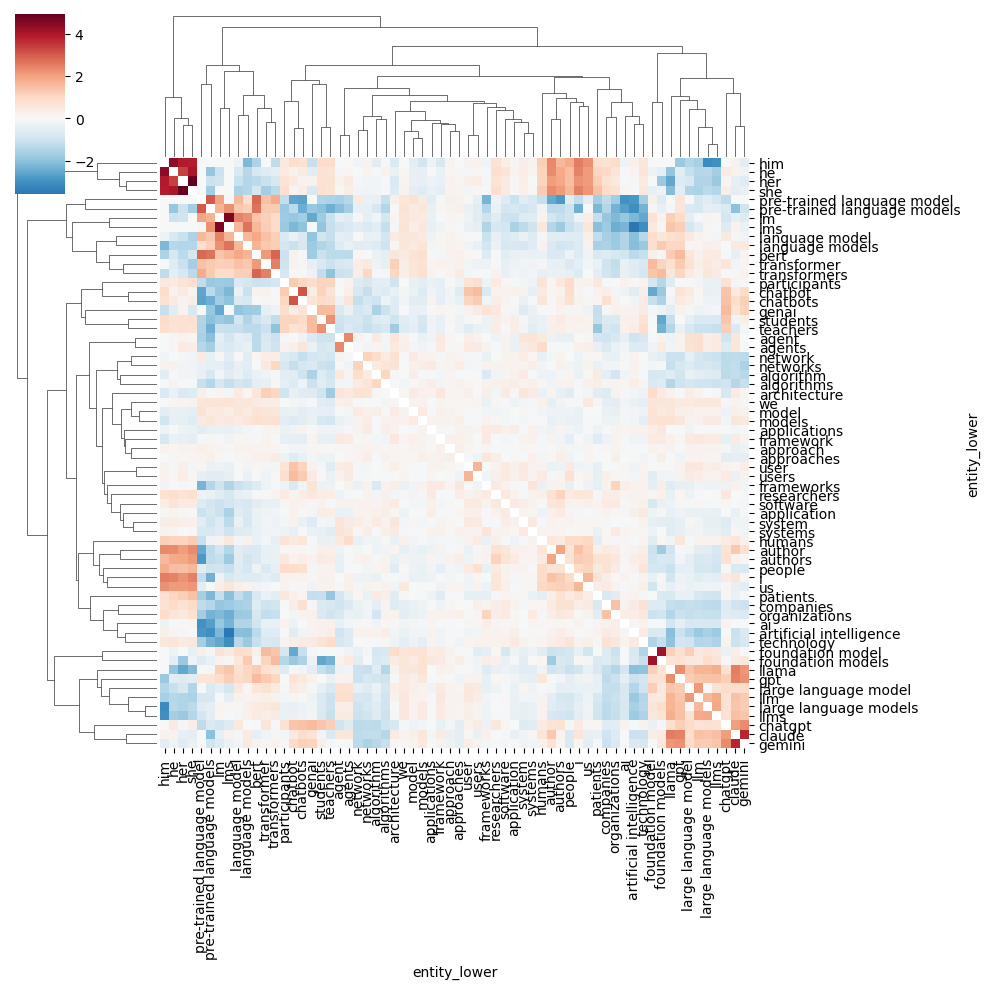

In [84]:
plot_co_occurrences(df_dedupl)

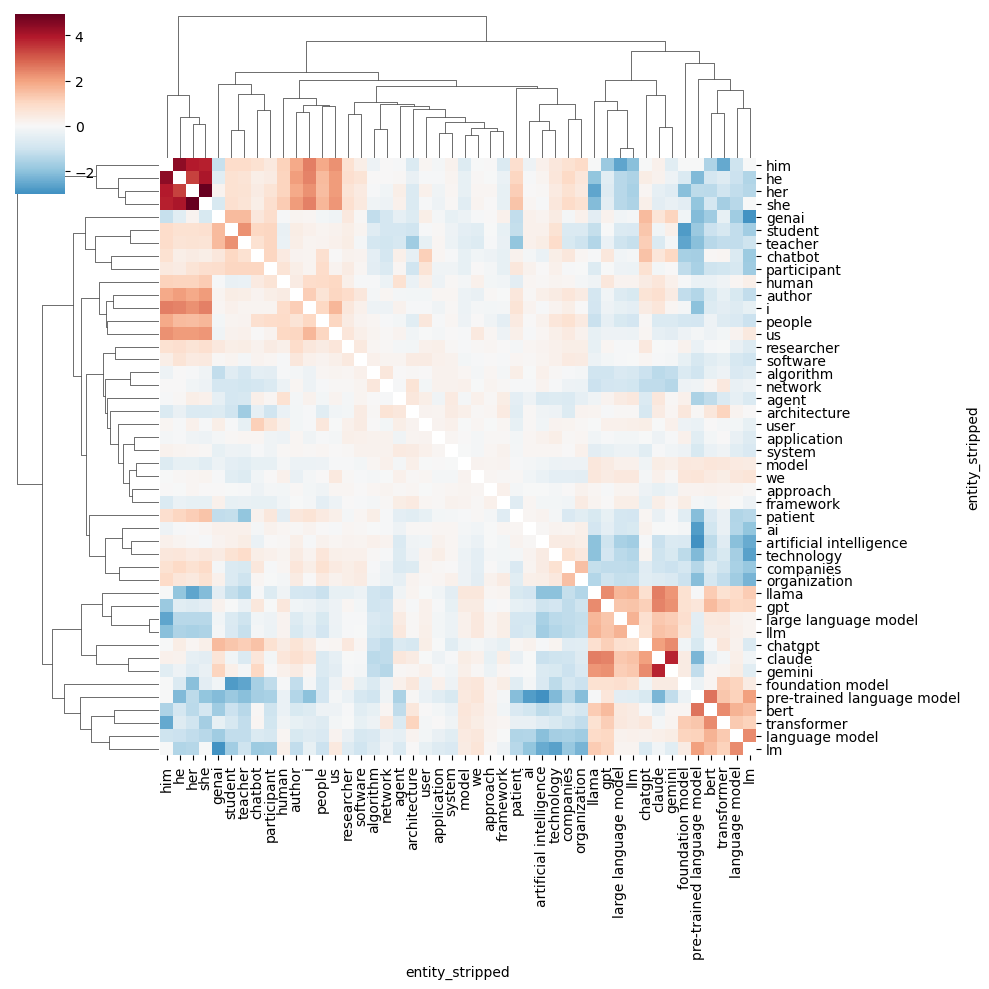

In [87]:
plot_co_occurrences(df_dedupl, crosstab_y="entity_stripped")

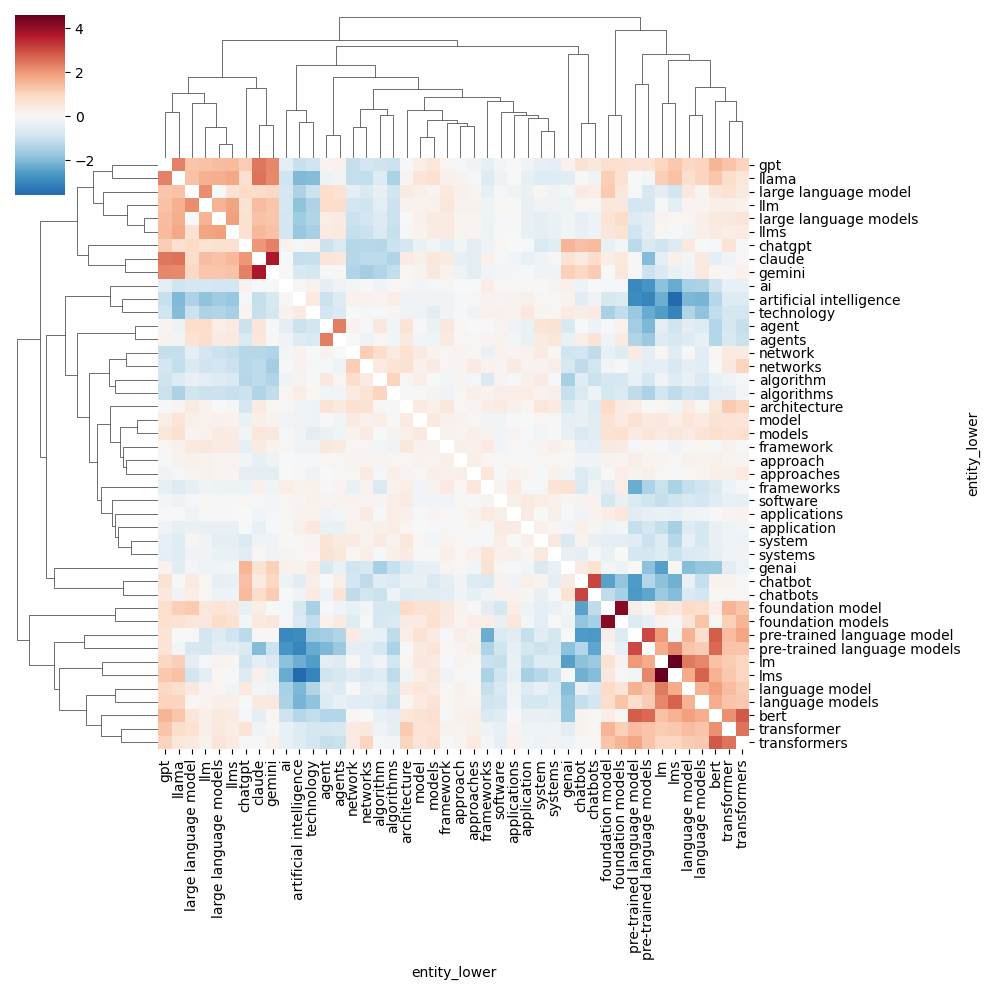

In [88]:
# Exclude the human terms
plot_co_occurrences(df_dedupl[df_dedupl["entity_type_updated"] != "human"])

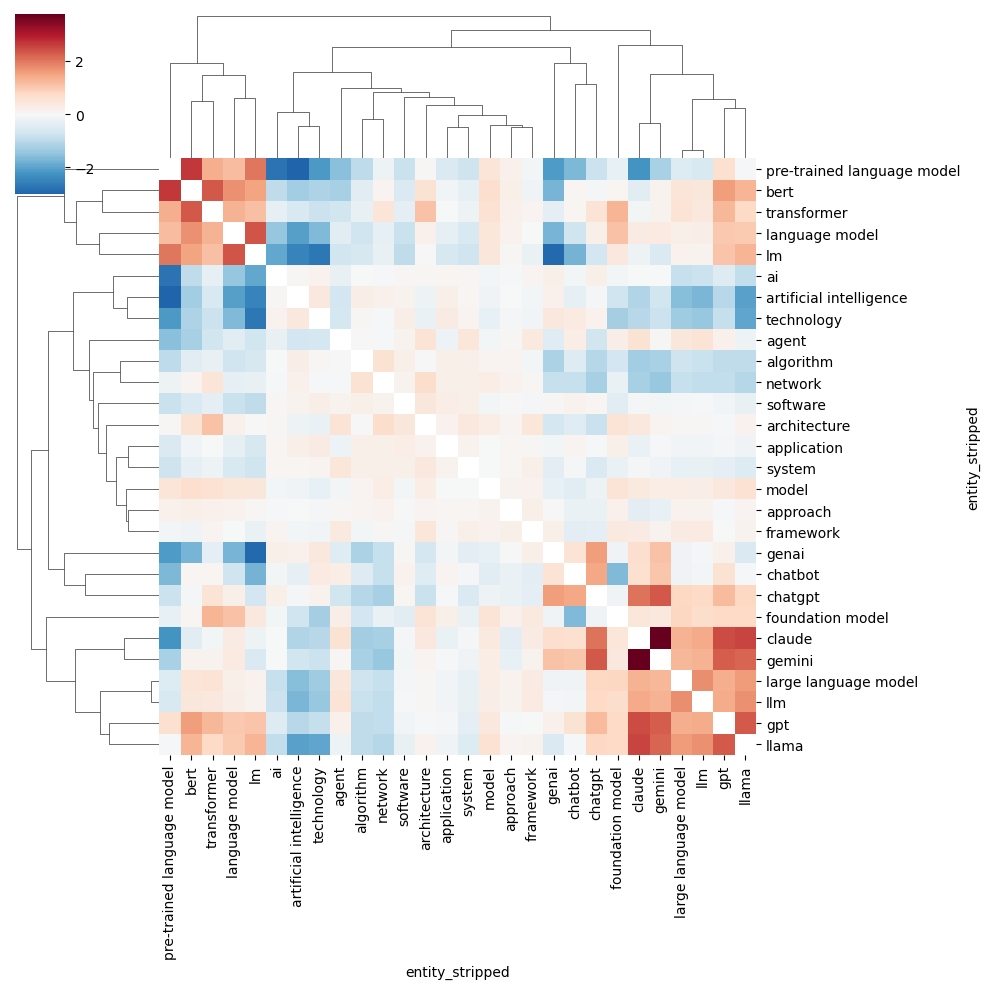

In [89]:
plot_co_occurrences(df_dedupl[df_dedupl["entity_type_updated"] != "human"], crosstab_y="entity_stripped")

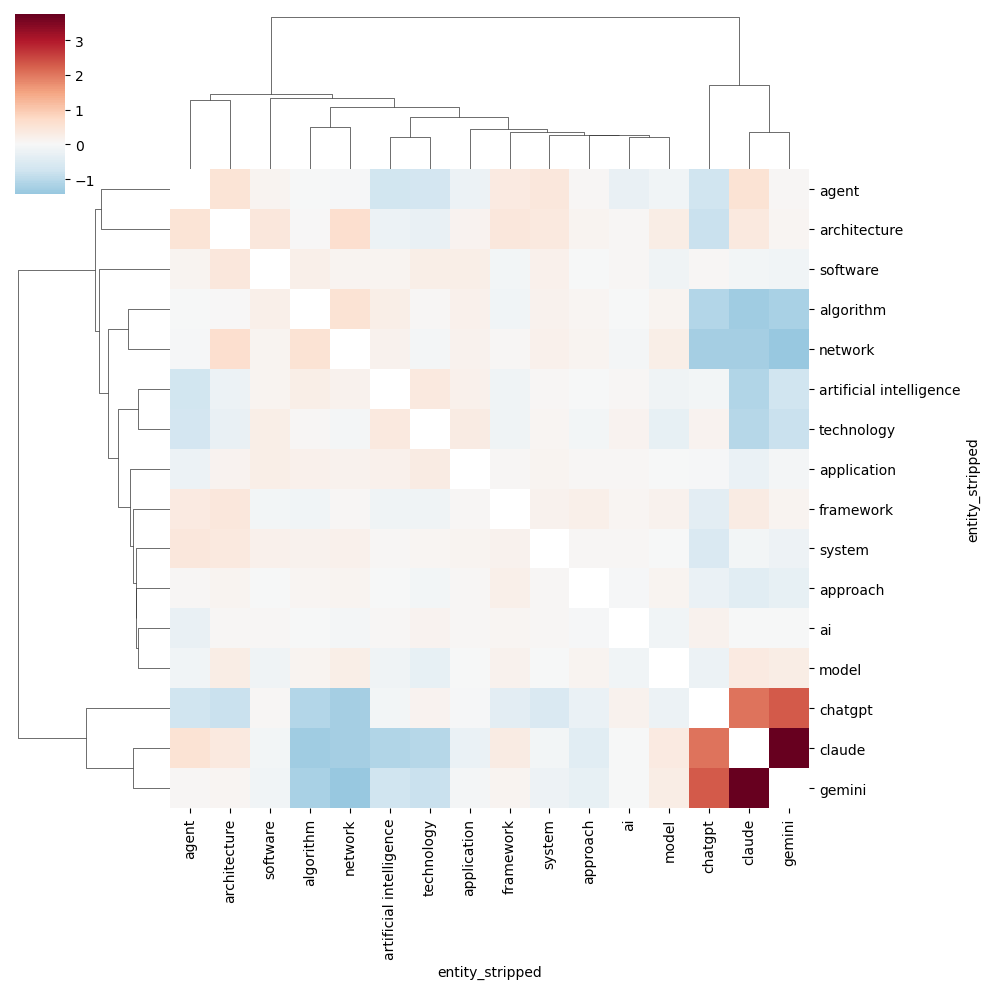

In [90]:
# Exclude general LM terms
plot_co_occurrences(df_dedupl[df_dedupl["entity_type_updated"].isin(("artifact", "propn_llm"))], crosstab_y="entity_stripped")

PHYSICAL SCIENCES


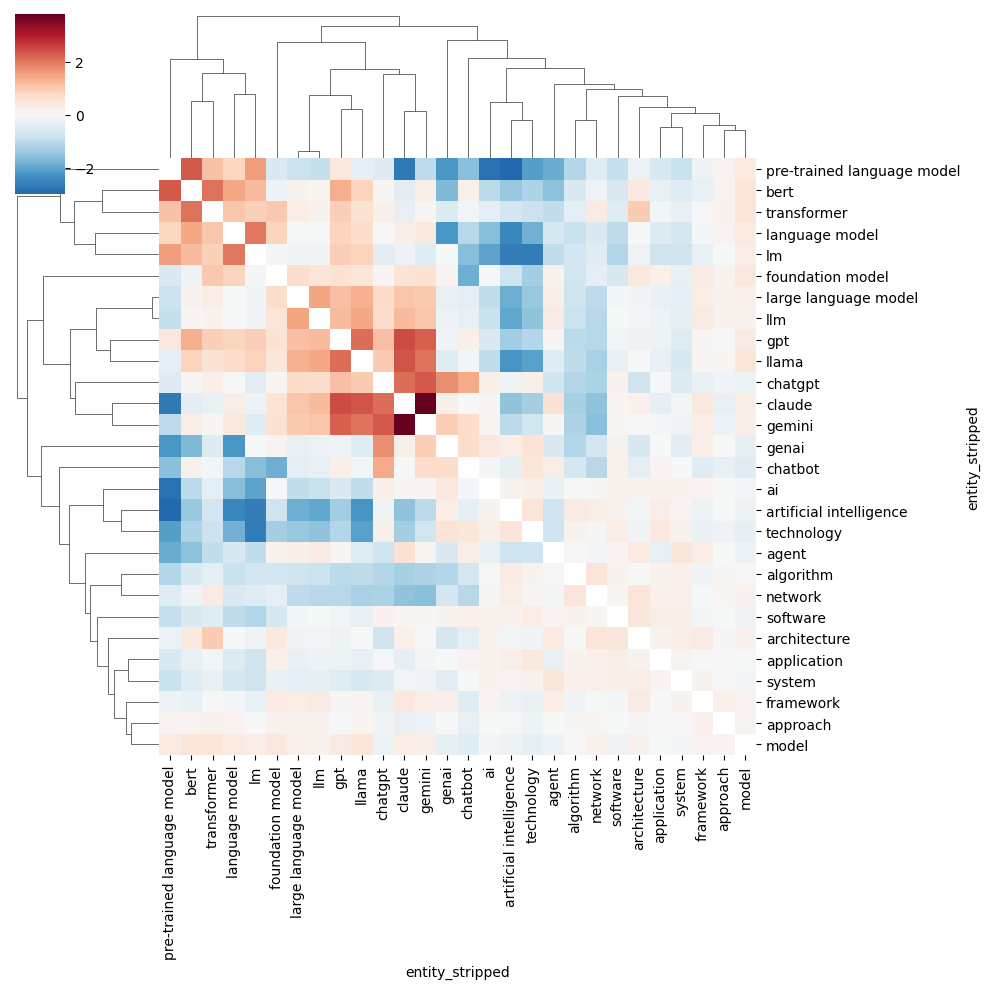

LIFE SCIENCES


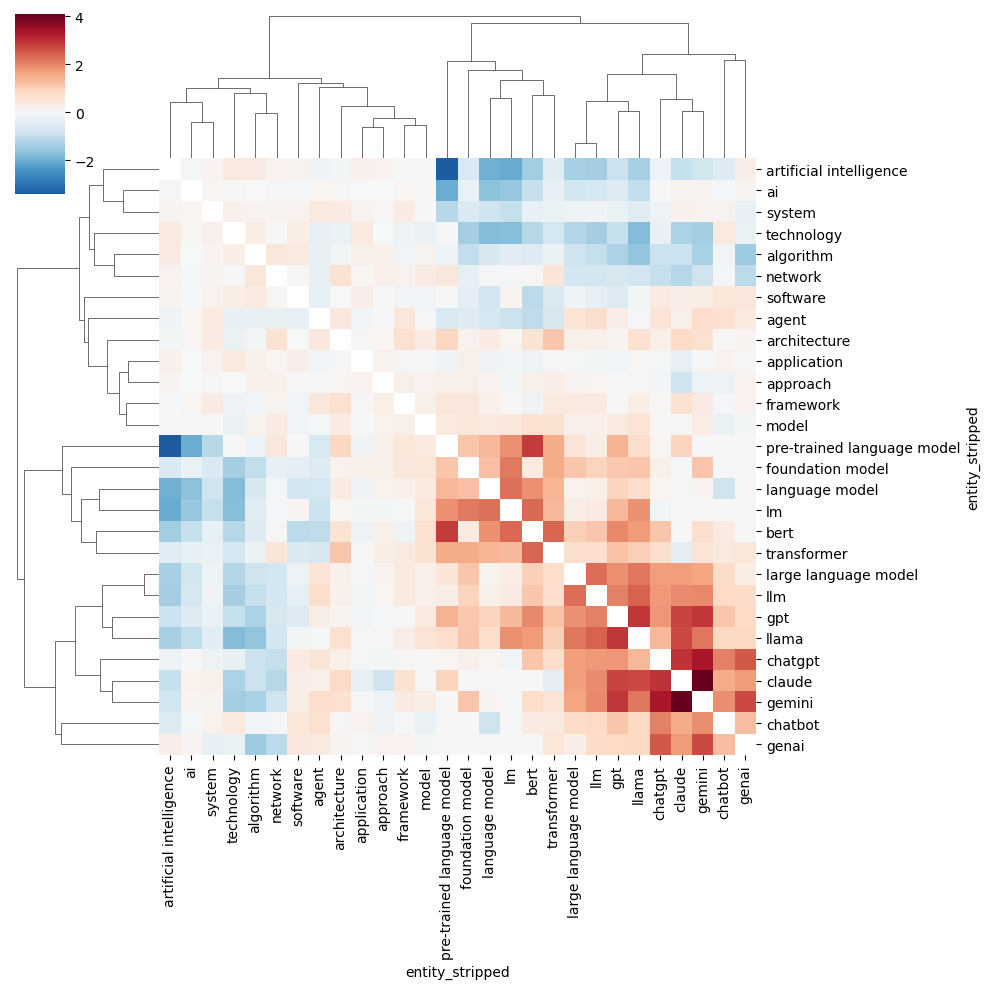

SOCIAL SCIENCES


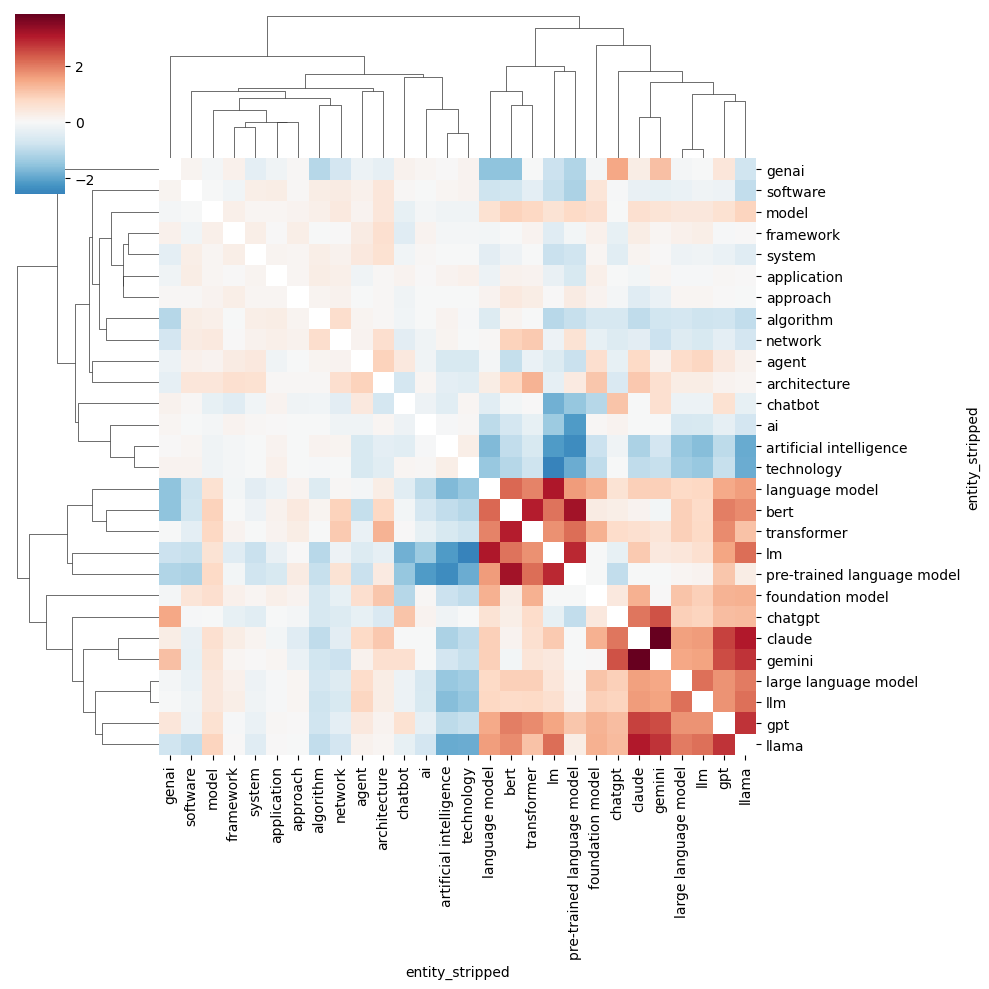

HEALTH SCIENCES


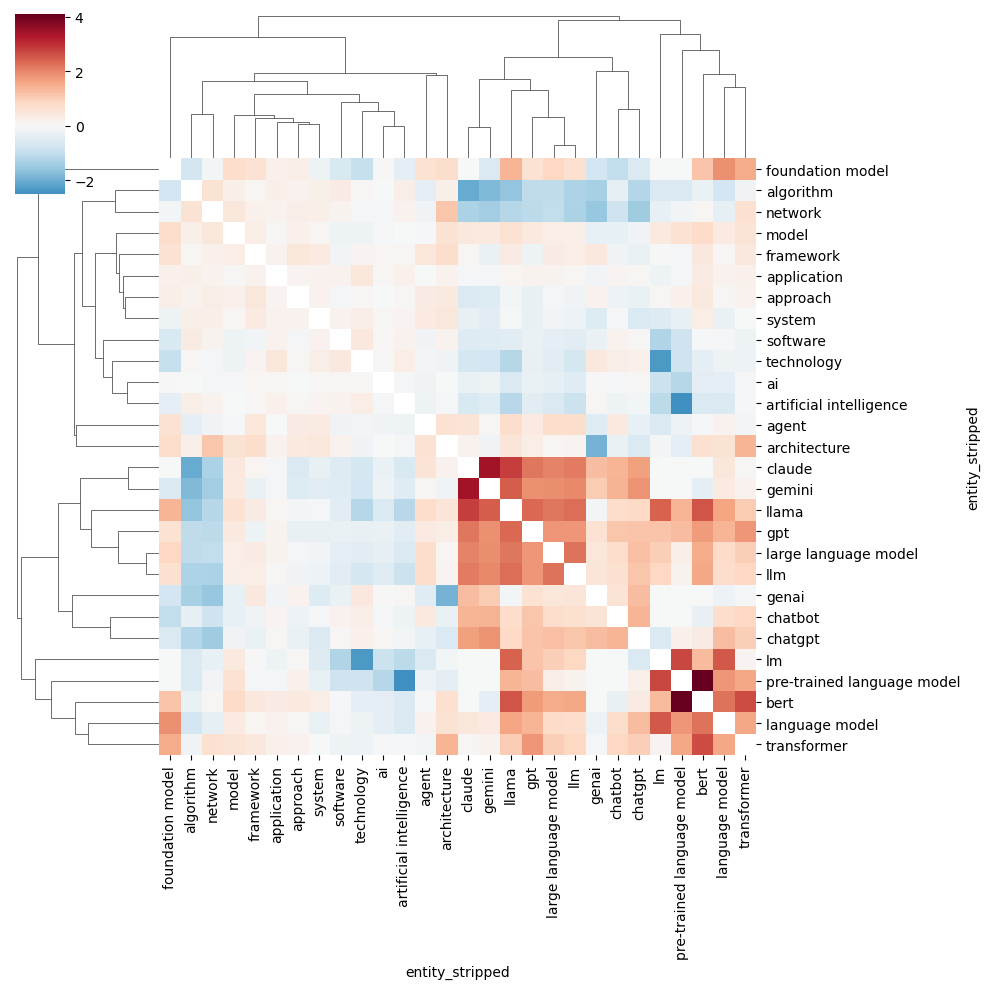

In [91]:
# Domain-wise inspection

for domain in domain_order:
    print(domain.upper())
    plot_co_occurrences(df_dedupl[(df_dedupl["entity_type_updated"] != "human") & (df_dedupl["domain"] == domain)], crosstab_y="entity_stripped")

PHYSICAL SCIENCES


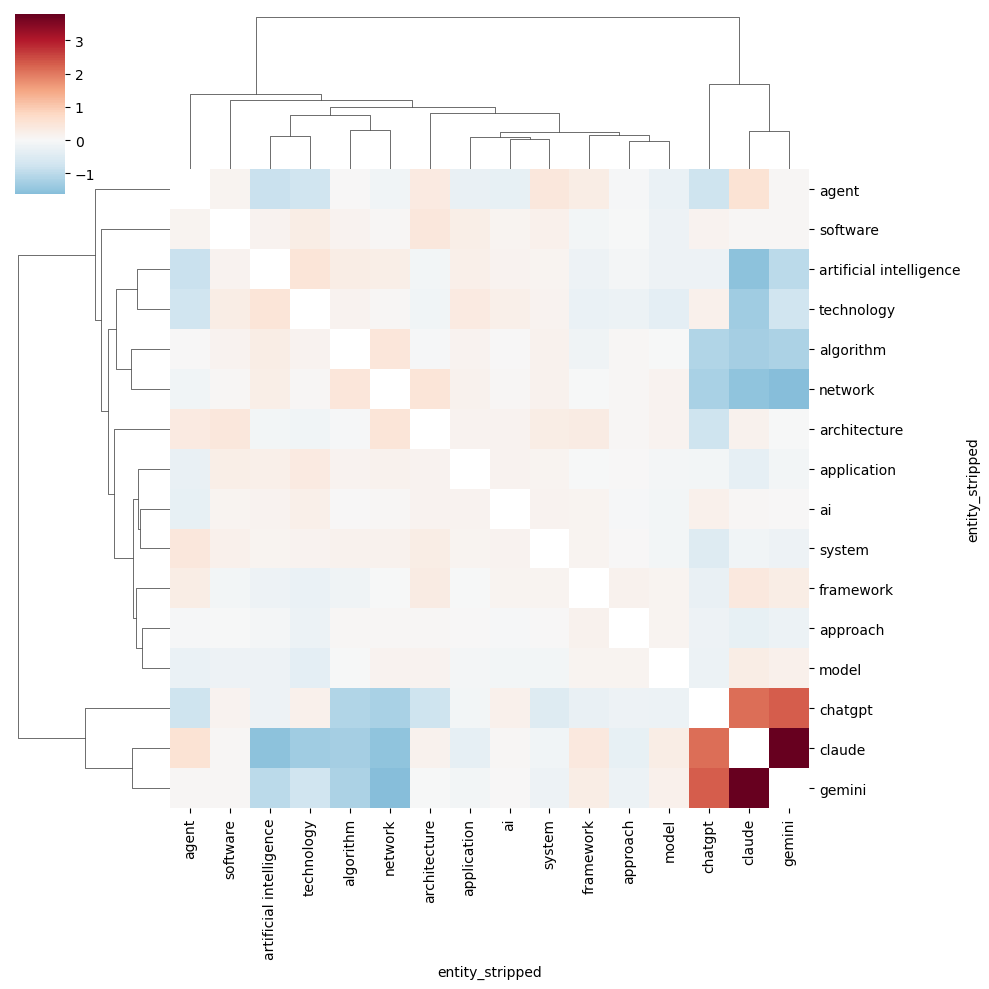

LIFE SCIENCES


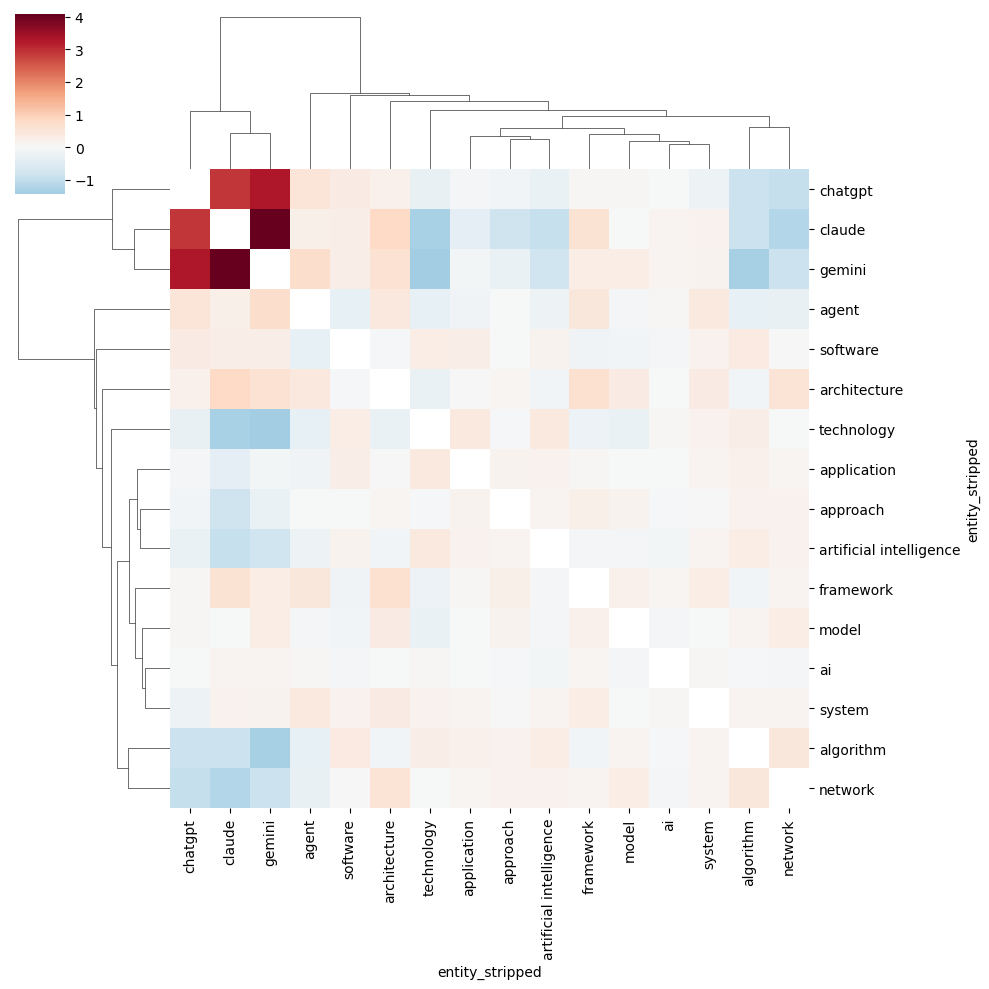

SOCIAL SCIENCES


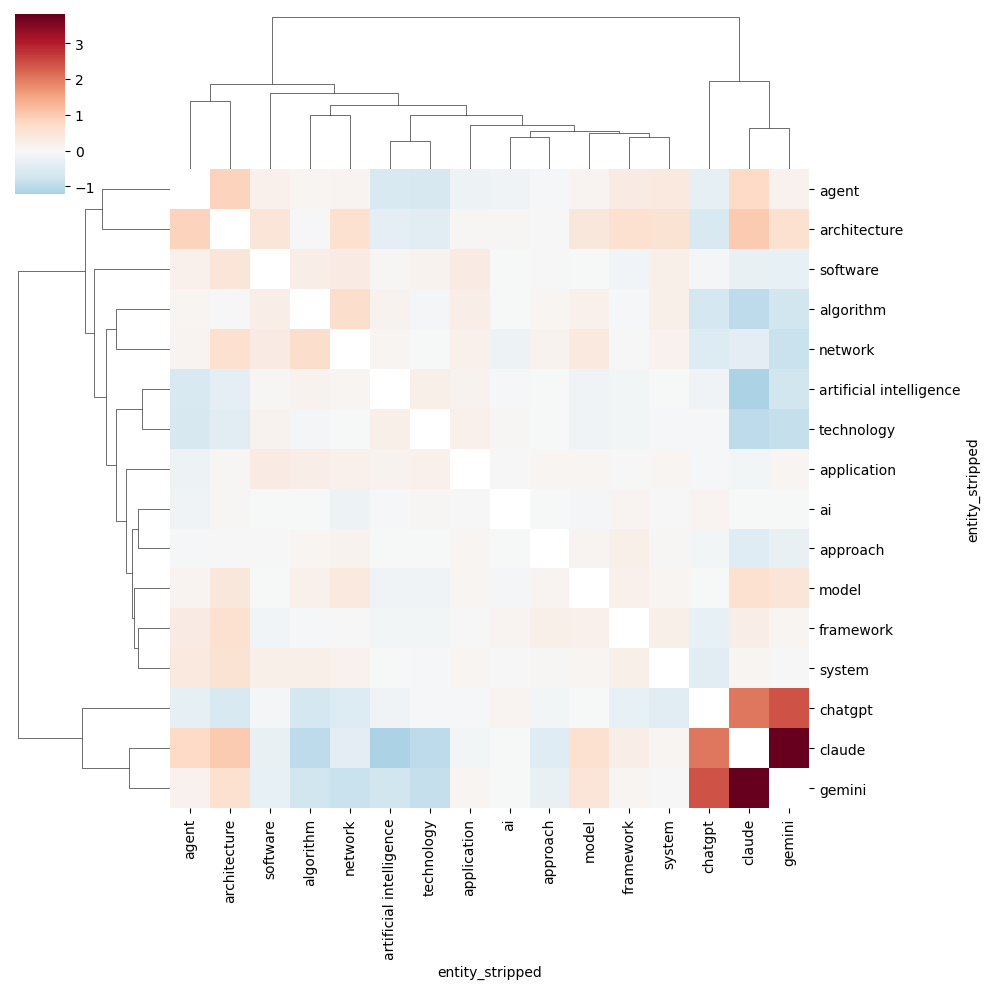

HEALTH SCIENCES


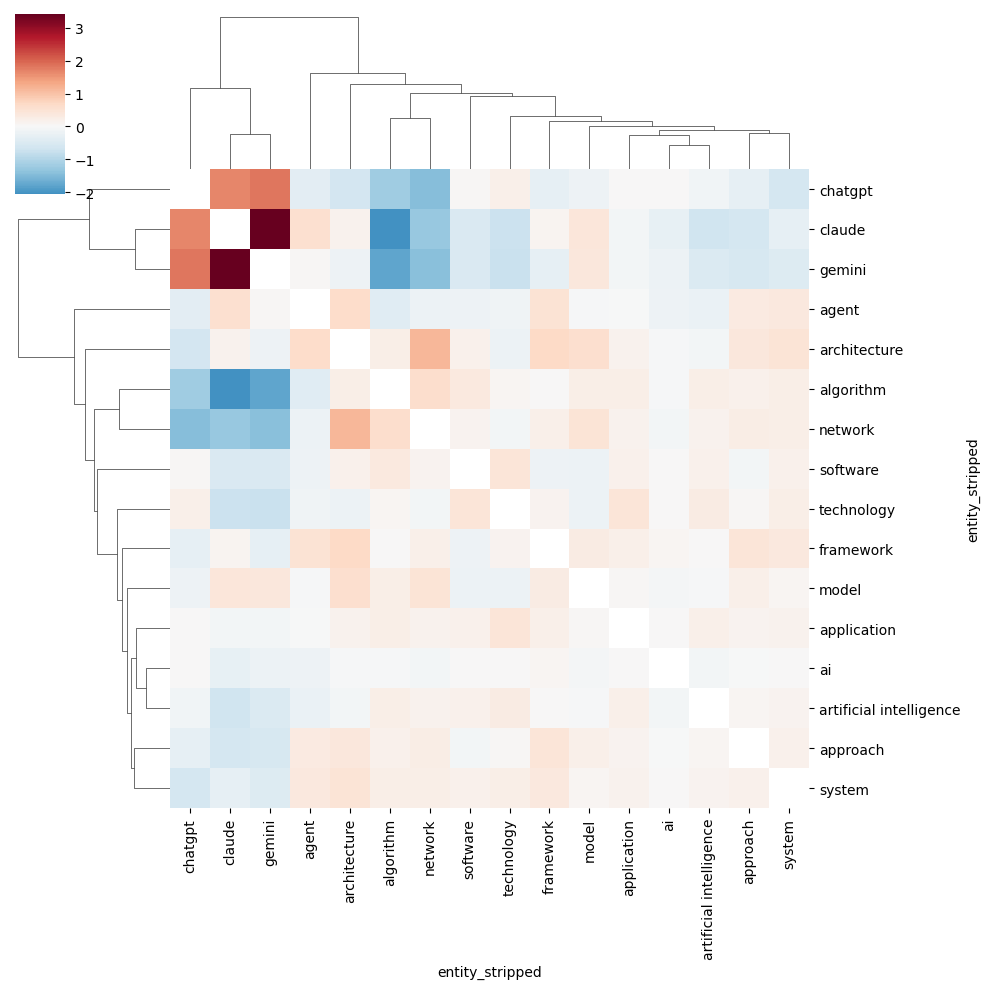

In [92]:
# Exclude general LM terms in domain-wise inspection

for domain in domain_order:
    print(domain.upper())
    plot_co_occurrences(df_dedupl[(df_dedupl["entity_type_updated"].isin(("artifact", "propn_llm"))) & (df_dedupl["domain"] == domain)], crosstab_y="entity_stripped")

The above plots do not support my initial hypothesis of specific terms co-occurring with product name terms and thus resulting in higher overall scores. Almost to the contrary; AI and artificial intelligence are rarely co-occurring. But this could also be hidden by the PMI, as artificial intelligence and AI dominate the whole corpus.

## Research question #2: Are there differences in the degree of anthropomorphization between different research domains?

### Treating the domain-wise documents as independent samples

In [27]:
docs.groupby(["domain"], observed=True)["avg_score"].agg(["mean", "median", "std", "var"])

,mean,median,std,var
domain,,,,
Health Sciences,-0.030302,-0.032449,0.030650,0.000939
Life Sciences,-0.040107,-0.043520,0.030272,0.000916
Physical Sciences,-0.043837,-0.046120,0.029189,0.000852
Social Sciences,-0.035770,-0.037110,0.032089,0.001030


Are the scores normally distributed and do they have equal variances?

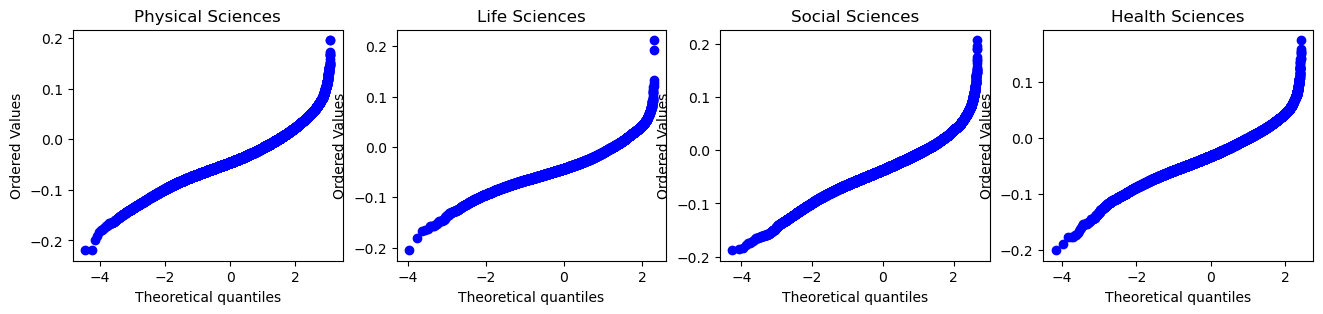

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for i, domain in enumerate(domain_order):
    stats.probplot(docs[docs["domain"] == domain]["avg_score"], plot=axes[i])
    axes[i].set_title(domain)
plt.show()

In [35]:
# Use Levene's test for equal variances
docs = docs.dropna(subset="avg_score")
domain_groups = docs.groupby(["domain"], observed=True)["avg_score"].apply(list)
stats.levene(*domain_groups)

LeveneResult(statistic=250.41391297035952, pvalue=2.665401664737105e-162)

Note that the following functions refer to Cliff's delta and the thesis to rank-biserial correlation - this is due to them being mathematically equivalent ([source](https://metricgate.com/docs/glass-rank-biserial/)). However, their thresholds are interpreted differently. In the final report, I have opted for rank-biserial threshold, for the simple (but not necessarily the most valid) reason that they are easier to remember. Claude has been used to implement these functions.

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
import scikit_posthocs as sp


def cliffs_delta(x, y):
    """
    Cliff's delta: P(X > Y) - P(Y > X).
    Uses the Mann-Whitney U relationship for an O(n log n) computation
    rather than a brute-force O(n*m) pairwise comparison.
    """
    x = np.asarray(x)
    y = np.asarray(y)
    n1, n2 = len(x), len(y)

    # U statistic from Mann-Whitney gives us the count of (x_i > y_j) pairs
    # directly, adjusted for ties, without ever forming the full pairwise matrix.
    u_stat, _ = stats.mannwhitneyu(x, y, alternative="two-sided")
    delta = (2 * u_stat) / (n1 * n2) - 1
    return delta

"""
def cliffs_delta_ci(x, y, alpha=0.05):
    
    #Approximate CI for Cliff's delta using the normal approximation
    #to the Mann-Whitney U distribution (adequate at large n; for small
    #samples a bootstrap CI would be more reliable).
    
    x = np.asarray(x)
    y = np.asarray(y)
    n1, n2 = len(x), len(y)

    delta = cliffs_delta(x, y)

    # Standard error approximation (Cliff, 1993)
    # Uses the relationship between delta and the AUC form of Mann-Whitney.
    auc = (delta + 1) / 2
    se = np.sqrt((n1 + n2 + 1) / (12 * n1 * n2)) * 2  # factor of 2: delta = 2*AUC - 1

    z_crit = stats.norm.ppf(1 - alpha / 2)
    ci_low = max(delta - z_crit * se, -1)
    ci_high = min(delta + z_crit * se, 1)

    return delta, ci_low, ci_high
"""

def _cliffs_delta_ranked(x, y):
    """
    Same O(n log n)/O(n) approach as cliffs_delta, but without scipy's
    p-value machinery -- just the rank computation, for speed inside a
    bootstrap loop. Never builds an n1 x n2 matrix.
    """
    n1, n2 = len(x), len(y)
    combined = np.concatenate([x, y])
    ranks = stats.rankdata(combined)  # average ranks for ties
    r1 = ranks[:n1].sum()
    u1 = r1 - n1 * (n1 + 1) / 2
    return 2 * u1 / (n1 * n2) - 1

def cliffs_delta_ci(x, y, alpha=0.05, n_boot=500, seed=None):
    """
    Confidence interval for Cliff's delta via percentile bootstrap.

    Memory: O(n1 + n2), independent of n_boot -- each bootstrap resample
    is drawn, scored, and discarded one at a time, and delta is computed
    via ranks (O(n log n)) rather than an O(n1*n2) pairwise matrix. This
    scales to large datasets; an earlier version of this function built
    the full pairwise comparison matrix on every bootstrap iteration,
    which is what was blowing up your memory.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n1, n2 = len(x), len(y)
    if n1 < 2 or n2 < 2:
        raise ValueError("Need at least 2 observations per group for a bootstrap CI.")

    rng = np.random.default_rng(seed)
    delta = cliffs_delta(x, y)

    boot_deltas = np.empty(n_boot)
    for i in range(n_boot):
        bx = rng.choice(x, size=n1, replace=True)
        by = rng.choice(y, size=n2, replace=True)
        boot_deltas[i] = _cliffs_delta_ranked(bx, by)

    if boot_deltas.std() < 1e-12:
        warnings.warn(
            "Bootstrap distribution has (near) zero variance: the sample shows "
            "complete separation between groups. The returned CI will collapse "
            "to a point and will not reflect true population uncertainty.",
            stacklevel=2,
        )

    ci_low = np.percentile(boot_deltas, 100 * alpha / 2)
    ci_high = np.percentile(boot_deltas, 100 * (1 - alpha / 2))
    return delta, ci_low, ci_high


def kruskal_dunn_cliffs(df, value_col, group_col, alpha=0.05, p_adjust="holm"):
    df = df.dropna(subset=value_col)
    groups = df.groupby(group_col, observed=True)[value_col]

    # 1. Omnibus Kruskal-Wallis test
    group_values = [groups.get_group(name).values for name in domain_order]
    if len(group_values) < 3:
        print("Not enough groups")
        return
    h_stat, kw_p = stats.kruskal(*group_values)
    print(f"Kruskal-Wallis: H = {h_stat:.3f}, p = {kw_p:.4g}")

    # 2. Dunn's post-hoc (pairwise), Holm-corrected p-values by default
    dunn_matrix = sp.posthoc_dunn(df, val_col=value_col, group_col=group_col, p_adjust=p_adjust)

    # 3. Cliff's delta + CI per pair
    rows = []
    for g1, g2 in combinations(domain_order, 2):
        x = groups.get_group(g1).values
        y = groups.get_group(g2).values
        delta, ci_low, ci_high = cliffs_delta_ci(x, y, alpha=alpha)
        p_val = dunn_matrix.loc[g1, g2]

        rows.append({
            "pair": f"{g1} vs {g2}",
            "n1": len(x), "n2": len(y),
            "median1": np.median(x), "median2": np.median(y),
            "cliffs_delta": delta,
            "ci_low": ci_low, "ci_high": ci_high,
            "p_value": p_val,
            "significant": p_val < alpha
        })

    result_df = pd.DataFrame(rows).sort_values("cliffs_delta", ascending=False, key=abs)
    return h_stat, kw_p, result_df


def forest_plot_cliffs(effect_df, alpha=0.05, title="Pairwise domain differences (Cliff's delta)"):
    df = effect_df.sort_values("cliffs_delta").reset_index(drop=True)
    y_pos = np.arange(len(df))

    fig, ax = plt.subplots(figsize=(7, max(3, 0.3 * len(df))))

    for i, row in df.iterrows():
        color = "#d62728" if row["significant"] else "#7f7f7f"
        xerr_low = row["cliffs_delta"] - row["ci_low"]
        xerr_high = row["ci_high"] - row["cliffs_delta"]

        ax.errorbar(
            row["cliffs_delta"], i,
            xerr=[[xerr_low], [xerr_high]],
            fmt="o", color=color, ecolor=color,
            elinewidth=2, capsize=3, markersize=5
        )

    # Reference gridlines using conventional Cliff's delta benchmarks
    # (Romano et al., 2006): negligible <0.147, small <0.33, medium <0.474, large >=0.474
    # xticklabels = [-0.474, -0.33, -0.147, 0.147, 0.33, 0.474]

    # As rank-biserial correlation is matemathically equivalent to Cliff's delta, use its
    # benchmarks instead so they are used throughout the thesis
    xticklabels = [-0.5, -0.3, -0.1, 0.1, 0.3, 0.5]
    for x in xticklabels:
        ax.axvline(x, color="lightgray", linestyle="--", linewidth=0.7, zorder=0)
    ax.axvline(0, color="black", linewidth=1)

    ax.set_xlim(-0.55, 0.55)
    ax.set_xticks(xticklabels)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df["pair"], fontsize=8)
    ax.set_xlabel("Rank-biserial correlation (95% CI)")
    ax.set_title(title)

    from matplotlib.lines import Line2D
    legend_elems = [
        Line2D([0], [0], marker="o", color="#d62728", lw=2, label=f"Significant\n(p < {alpha})"),
        Line2D([0], [0], marker="o", color="#7f7f7f", lw=2, label="Not significant"),
    ]
    ax.legend(handles=legend_elems, loc="upper left", frameon=False, fontsize=8)

    plt.tight_layout()
    return fig, ax

In [90]:
# The most basic test without entity type separation
h_stat, kw_p, effects = kruskal_dunn_cliffs(docs_no_human, "avg_score", "domain")
display(effects)

Kruskal-Wallis: H = 9254.747, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
2,Physical Sciences vs Health Sciences,154251,43397,-0.04612,-0.032449,-0.271748,-0.277921,-0.266462,0.000000e+00,True
4,Life Sciences vs Health Sciences,18937,43397,-0.04352,-0.032449,-0.206890,-0.216549,-0.197575,0.000000e+00,True
1,Physical Sciences vs Social Sciences,154251,66598,-0.04612,-0.037110,-0.167610,-0.172648,-0.162095,0.000000e+00,True
3,Life Sciences vs Social Sciences,18937,66598,-0.04352,-0.037110,-0.103037,-0.112722,-0.093759,2.397471e-102,True
5,Social Sciences vs Health Sciences,66598,43397,-0.03711,-0.032449,-0.100231,-0.106974,-0.093689,5.360904e-182,True
0,Physical Sciences vs Life Sciences,154251,18937,-0.04612,-0.043520,-0.066973,-0.075337,-0.059089,5.543967e-50,True


In [16]:
effects_list = []
for score_key, score_val in avg_score_map.items():
    print(score_val)
    h_stat, kw_p, effects = kruskal_dunn_cliffs(docs, score_key, "domain")
    display(effects)
    effects_list.append(effects)

artifact
Kruskal-Wallis: H = 11259.997, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
2,Physical Sciences vs Health Sciences,151366,42603,-0.049692,-0.034769,-0.294486,-0.300544,-0.289049,0.000000e+00,True
1,Physical Sciences vs Social Sciences,151366,65680,-0.049692,-0.039131,-0.197441,-0.203088,-0.191588,0.000000e+00,True
4,Life Sciences vs Health Sciences,18681,42603,-0.044880,-0.034769,-0.186182,-0.195468,-0.176606,3.232852e-281,True
0,Physical Sciences vs Life Sciences,151366,18681,-0.049692,-0.044880,-0.114318,-0.125040,-0.105440,1.261507e-137,True
5,Social Sciences vs Health Sciences,65680,42603,-0.039131,-0.034769,-0.091875,-0.098440,-0.084596,9.357155e-154,True
3,Life Sciences vs Social Sciences,18681,65680,-0.044880,-0.039131,-0.089361,-0.099324,-0.080367,2.397402e-73,True


LM
Kruskal-Wallis: H = 638.253, p = 5.131e-138


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
3,Life Sciences vs Social Sciences,3904,14005,-0.038498,-0.025323,-0.183446,-0.204896,-0.165124,7.036283e-72,True
4,Life Sciences vs Health Sciences,3904,8174,-0.038498,-0.025241,-0.166227,-0.187311,-0.145331,2.058529e-55,True
1,Physical Sciences vs Social Sciences,56925,14005,-0.032996,-0.025323,-0.107234,-0.117032,-0.096617,5.010897e-84,True
2,Physical Sciences vs Health Sciences,56925,8174,-0.032996,-0.025241,-0.094771,-0.108300,-0.080677,1.298127e-43,True
0,Physical Sciences vs Life Sciences,56925,3904,-0.032996,-0.038498,0.084754,0.065633,0.104112,1.816923e-17,True
5,Social Sciences vs Health Sciences,14005,8174,-0.025323,-0.025241,0.006748,-0.009612,0.022327,1.649258e-01,False


product name
Kruskal-Wallis: H = 274.062, p = 4.079e-59


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
2,Physical Sciences vs Health Sciences,5725,5050,-0.016822,-0.003841,-0.178762,-0.200100,-0.159667,9.768718e-56,True
5,Social Sciences vs Health Sciences,2944,5050,-0.015139,-0.003841,-0.141196,-0.169515,-0.115665,1.909005e-26,True
0,Physical Sciences vs Life Sciences,5725,397,-0.016822,-0.007446,-0.135505,-0.198316,-0.070993,1.234941e-05,True
3,Life Sciences vs Social Sciences,397,2944,-0.007446,-0.015139,0.103266,0.039576,0.168164,1.457738e-03,True
4,Life Sciences vs Health Sciences,397,5050,-0.007446,-0.003841,-0.029351,-0.093413,0.030302,2.216568e-01,False
1,Physical Sciences vs Social Sciences,5725,2944,-0.016822,-0.015139,-0.028910,-0.053676,-0.005129,2.845310e-02,True


In [17]:
alpha = 0.01
for e in effects_list:
    e["below_alpha"] = e["p_value"] < alpha
    display(e.round(3))

,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant,below_alpha
2,Physical Sciences vs Health Sciences,151366,42603,-0.050,-0.035,-0.294,-0.301,-0.289,0.0,True,True
1,Physical Sciences vs Social Sciences,151366,65680,-0.050,-0.039,-0.197,-0.203,-0.192,0.0,True,True
4,Life Sciences vs Health Sciences,18681,42603,-0.045,-0.035,-0.186,-0.195,-0.177,0.0,True,True
0,Physical Sciences vs Life Sciences,151366,18681,-0.050,-0.045,-0.114,-0.125,-0.105,0.0,True,True
5,Social Sciences vs Health Sciences,65680,42603,-0.039,-0.035,-0.092,-0.098,-0.085,0.0,True,True
3,Life Sciences vs Social Sciences,18681,65680,-0.045,-0.039,-0.089,-0.099,-0.080,0.0,True,True


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant,below_alpha
3,Life Sciences vs Social Sciences,3904,14005,-0.038,-0.025,-0.183,-0.205,-0.165,0.000,True,True
4,Life Sciences vs Health Sciences,3904,8174,-0.038,-0.025,-0.166,-0.187,-0.145,0.000,True,True
1,Physical Sciences vs Social Sciences,56925,14005,-0.033,-0.025,-0.107,-0.117,-0.097,0.000,True,True
2,Physical Sciences vs Health Sciences,56925,8174,-0.033,-0.025,-0.095,-0.108,-0.081,0.000,True,True
0,Physical Sciences vs Life Sciences,56925,3904,-0.033,-0.038,0.085,0.066,0.104,0.000,True,True
5,Social Sciences vs Health Sciences,14005,8174,-0.025,-0.025,0.007,-0.010,0.022,0.165,False,False


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant,below_alpha
2,Physical Sciences vs Health Sciences,5725,5050,-0.017,-0.004,-0.179,-0.200,-0.160,0.000,True,True
5,Social Sciences vs Health Sciences,2944,5050,-0.015,-0.004,-0.141,-0.170,-0.116,0.000,True,True
0,Physical Sciences vs Life Sciences,5725,397,-0.017,-0.007,-0.136,-0.198,-0.071,0.000,True,True
3,Life Sciences vs Social Sciences,397,2944,-0.007,-0.015,0.103,0.040,0.168,0.001,True,True
4,Life Sciences vs Health Sciences,397,5050,-0.007,-0.004,-0.029,-0.093,0.030,0.222,False,False
1,Physical Sciences vs Social Sciences,5725,2944,-0.017,-0.015,-0.029,-0.054,-0.005,0.028,True,False


In [18]:
diff_order = pd.concat(effects_list).groupby("pair")["cliffs_delta"].mean().sort_values(ascending=False).index

In [19]:
pd.concat(effects_list).groupby("pair")["cliffs_delta"].mean().sort_values()

pair
Physical Sciences vs Health Sciences   -0.189340
Life Sciences vs Health Sciences       -0.127253
Physical Sciences vs Social Sciences   -0.111195
Social Sciences vs Health Sciences     -0.075441
Life Sciences vs Social Sciences       -0.056514
Physical Sciences vs Life Sciences     -0.055023
Name: cliffs_delta, dtype: float64

In [34]:
def pick_color(p):
    if p < 0.001:
        return "brown"
    elif p < 0.01:
        return "indianred"
    elif p < 0.05:
        return "lightcoral"
    else: return "0.6"

In [37]:
from matplotlib.lines import Line2D
def forest_plot_cliffs_subplots(effect_list, alpha=0.05, title="Pairwise domain differences (Cliff's delta)"):

    fig, axes = plt.subplots(1, len(effect_list), figsize=(11, 3))
    axes = axes.flatten()

    for sp_i, (effect_df, score_val) in enumerate(zip(effect_list, avg_score_map.values())):
        ax = axes[sp_i]

        df = effect_df.sort_values(by="pair", key=lambda col: col.map({v: i for i, v in enumerate(diff_order)})).reset_index(drop=True)
        y_pos = np.arange(len(df))

        for i, row in df.iterrows():
            color = "C3" if row["p_value"] <  alpha else "0.6"
            xerr_low = row["cliffs_delta"] - row["ci_low"]
            xerr_high = row["ci_high"] - row["cliffs_delta"]
    
            ax.errorbar(
                row["cliffs_delta"], i,
                xerr=[[xerr_low], [xerr_high]],
                fmt="o", color=color, ecolor=color,
                elinewidth=2, capsize=3, markersize=5
            )
    
        # Reference gridlines using conventional Cliff's delta benchmarks
        # (Romano et al., 2006): negligible <0.147, small <0.33, medium <0.474, large >=0.474
        # xticklabels = [-0.474, -0.33, 0.0, -0.147, 0.147]

        # As rank-biserial correlation is matemathically equivalent to Cliff's delta, use its
        # benchmarks instead so they are used throughout the thesis
        xticklabels = [-0.3, -0.1, 0.1]
        for x in xticklabels:
            ax.axvline(x, color="0.75", linestyle="--", linewidth=0.7, zorder=0)
        ax.axvline(0, color="firebrick", linestyle="--", linewidth=1.2)
    
        ax.set_xlim(-0.35, 0.2)
        ax.set_xticks(xticklabels)
        ax.set_xticklabels(xticklabels, fontsize=8)
        ax.set_yticks(y_pos)
        if sp_i == 0:
            ax.set_yticklabels(df["pair"], fontsize=9)
        else:
            ax.set_yticklabels([])
        ax.set_title(score_val)     

        handles = [plt.Line2D([0], [0], marker="o", color="C3", linestyle="", label=f"p (Holm-adjusted) < {alpha}"),
                   plt.Line2D([0], [0], marker="o", color="0.6", linestyle="", label="not significant")]
        fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.08))
        
        """
        legend_elems = [
            Line2D([0], [0], marker="o", color="#d62728", lw=2, label=f"Significant\n(p < {alpha})"),
            Line2D([0], [0], marker="o", color="#7f7f7f", lw=2, label="Not significant"),
        ]
        if sp_i == 1:
            ax.legend(handles=legend_elems, loc="upper right", fontsize=8)
        """

    return fig, ax

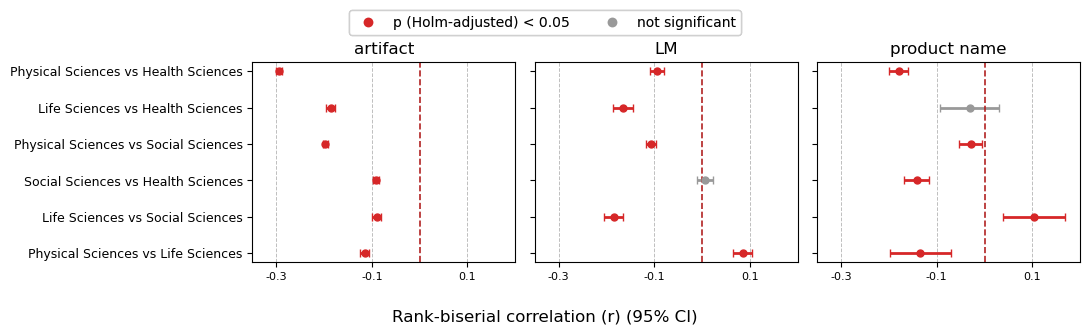

In [39]:
fig, ax = forest_plot_cliffs_subplots(effects_list)
fig.supxlabel("Rank-biserial correlation (r) (95% CI)")
fig.subplots_adjust(bottom=0.18)
plt.savefig("../figures/domain_diff_forestplot.pdf", bbox_inches="tight")
plt.tight_layout()
plt.show()

Kruskal-Wallis: H = 11259.997, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
1,Health Sciences vs Physical Sciences,42603,151366,-0.034769,-0.049692,0.294486,0.288713,0.300497,0.000000e+00,True
5,Physical Sciences vs Social Sciences,151366,65680,-0.049692,-0.039131,-0.197441,-0.202917,-0.192321,0.000000e+00,True
0,Health Sciences vs Life Sciences,42603,18681,-0.034769,-0.044880,0.186182,0.176296,0.195597,3.232852e-281,True
3,Life Sciences vs Physical Sciences,18681,151366,-0.044880,-0.049692,0.114318,0.105681,0.122754,1.261507e-137,True
2,Health Sciences vs Social Sciences,42603,65680,-0.034769,-0.039131,0.091875,0.084850,0.098719,9.357155e-154,True
4,Life Sciences vs Social Sciences,18681,65680,-0.044880,-0.039131,-0.089361,-0.098466,-0.080404,2.397402e-73,True


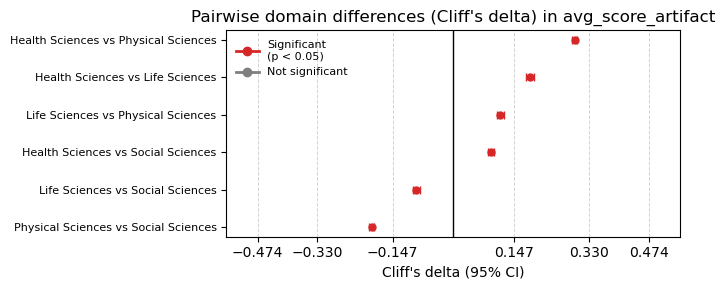

Kruskal-Wallis: H = 9254.747, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
1,Health Sciences vs Physical Sciences,43397,154251,-0.032449,-0.04612,0.271748,0.265893,0.277756,0.000000e+00,True
0,Health Sciences vs Life Sciences,43397,18937,-0.032449,-0.04352,0.206890,0.197498,0.216209,0.000000e+00,True
5,Physical Sciences vs Social Sciences,154251,66598,-0.046120,-0.03711,-0.167610,-0.172888,-0.162161,0.000000e+00,True
4,Life Sciences vs Social Sciences,18937,66598,-0.043520,-0.03711,-0.103037,-0.112339,-0.094068,2.397471e-102,True
2,Health Sciences vs Social Sciences,43397,66598,-0.032449,-0.03711,0.100231,0.093380,0.107331,5.360904e-182,True
3,Life Sciences vs Physical Sciences,18937,154251,-0.043520,-0.04612,0.066973,0.058530,0.075698,5.543967e-50,True


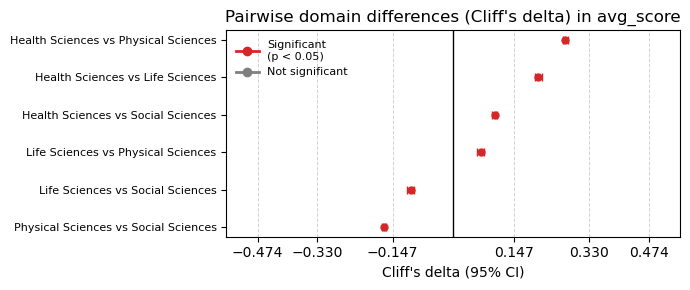

Kruskal-Wallis: H = 638.253, p = 5.131e-138


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
4,Life Sciences vs Social Sciences,3904,14005,-0.038498,-0.025323,-0.183446,-0.203033,-0.163702,7.036283e-72,True
0,Health Sciences vs Life Sciences,8174,3904,-0.025241,-0.038498,0.166227,0.145137,0.188192,2.058529e-55,True
5,Physical Sciences vs Social Sciences,56925,14005,-0.032996,-0.025323,-0.107234,-0.118209,-0.095913,5.010897e-84,True
1,Health Sciences vs Physical Sciences,8174,56925,-0.025241,-0.032996,0.094771,0.080775,0.107927,1.298127e-43,True
3,Life Sciences vs Physical Sciences,3904,56925,-0.038498,-0.032996,-0.084754,-0.103087,-0.065717,1.816923e-17,True
2,Health Sciences vs Social Sciences,8174,14005,-0.025241,-0.025323,-0.006748,-0.022593,0.009352,1.649258e-01,False


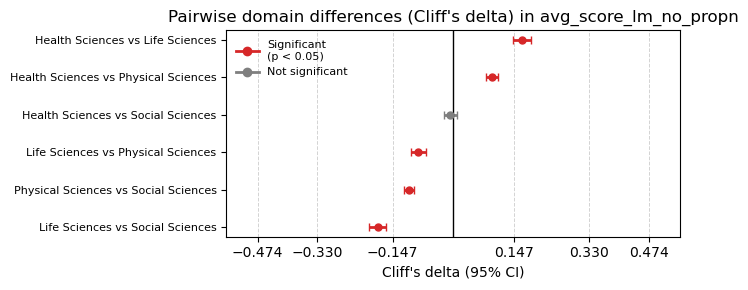

Kruskal-Wallis: H = 1612.173, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
0,Health Sciences vs Life Sciences,10179,4020,-0.016524,-0.037483,0.274058,0.253620,0.294237,6.913331e-153,True
1,Health Sciences vs Physical Sciences,10179,58603,-0.016524,-0.032151,0.212463,0.200557,0.224098,6.009868e-254,True
4,Life Sciences vs Social Sciences,4020,15330,-0.037483,-0.023968,-0.185482,-0.204783,-0.165016,3.117695e-77,True
5,Physical Sciences vs Social Sciences,58603,15330,-0.032151,-0.023968,-0.118418,-0.128938,-0.108622,2.023133e-112,True
2,Health Sciences vs Social Sciences,10179,15330,-0.016524,-0.023968,0.091361,0.077048,0.105182,4.167797e-36,True
3,Life Sciences vs Physical Sciences,4020,58603,-0.037483,-0.032151,-0.075705,-0.095090,-0.057096,1.261268e-14,True


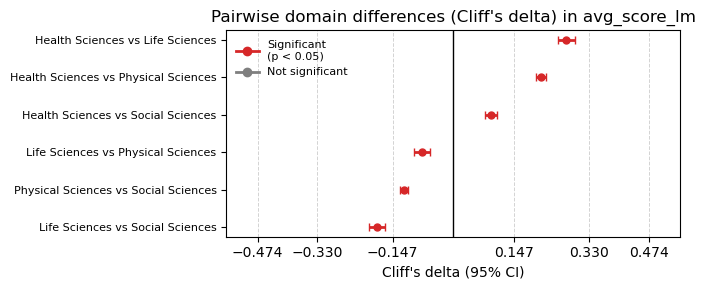

Kruskal-Wallis: H = 274.062, p = 4.079e-59


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
1,Health Sciences vs Physical Sciences,5050,5725,-0.003841,-0.016822,0.178762,0.157236,0.200028,9.768718e-56,True
2,Health Sciences vs Social Sciences,5050,2944,-0.003841,-0.015139,0.141196,0.114648,0.167556,1.909005e-26,True
3,Life Sciences vs Physical Sciences,397,5725,-0.007446,-0.016822,0.135505,0.076971,0.196525,1.234941e-05,True
4,Life Sciences vs Social Sciences,397,2944,-0.007446,-0.015139,0.103266,0.043473,0.161304,1.457738e-03,True
0,Health Sciences vs Life Sciences,5050,397,-0.003841,-0.007446,0.029351,-0.035846,0.090852,2.216568e-01,False
5,Physical Sciences vs Social Sciences,5725,2944,-0.016822,-0.015139,-0.028910,-0.056392,-0.002483,2.845310e-02,True


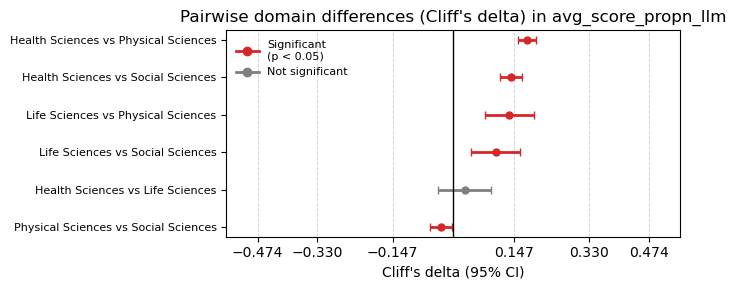

Kruskal-Wallis: H = 2300.700, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
1,Health Sciences vs Physical Sciences,30816,111621,0.080722,0.069575,0.179749,0.172208,0.187307,0.000000e+00,True
2,Health Sciences vs Social Sciences,30816,46567,0.080722,0.071269,0.141744,0.133637,0.150071,1.874395e-269,True
0,Health Sciences vs Life Sciences,30816,12705,0.080722,0.072771,0.133954,0.123258,0.145250,1.973428e-96,True
3,Life Sciences vs Physical Sciences,12705,111621,0.072771,0.069575,0.052603,0.042468,0.063099,4.111582e-20,True
5,Physical Sciences vs Social Sciences,111621,46567,0.069575,0.071269,-0.026551,-0.033243,-0.020229,4.731838e-19,True
4,Life Sciences vs Social Sciences,12705,46567,0.072771,0.071269,0.020529,0.009759,0.031063,1.806987e-04,True


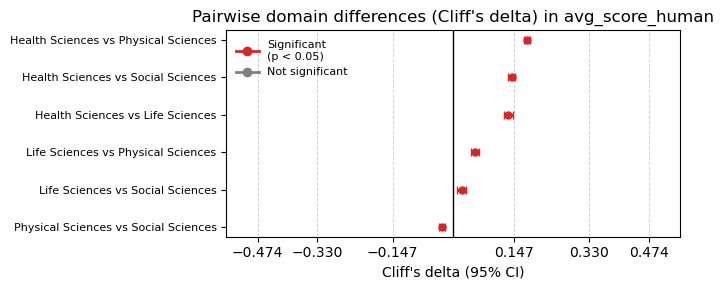

In [13]:
for score in avg_cols:
    h_stat, kw_p, effects = kruskal_dunn_cliffs(docs, score, "domain")
    display(effects)
    
    fig, ax = forest_plot_cliffs(effects, title=f"Pairwise domain differences (Cliff's delta) in {score}")
    plt.show()

### Treating the documents as paired

While these tests are also called rank-biserial correlation, they are calculated differently due to them being applied on paired data, whereas the Cliff's delta / the other rank-biserial correlation was used for independent data. These have also been implemented using Claude.

In [18]:
"""
Wilcoxon signed-rank test with matched-pairs rank-biserial effect sizes,
bootstrap confidence intervals, and a forest plot summarizing the results.

Typical use: you have several paired comparisons (e.g. before/after for
several outcome variables, or the same outcome measured in several
subgroups) and want one figure summarizing effect size + CI + p-value
for all of them, the way a meta-analysis forest plot does.
"""

import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


def rank_biserial(x, y, zero_method="wilcox"):
    """Matched-pairs rank-biserial correlation for paired data x, y.

    Companion effect size to the Wilcoxon signed-rank test.
    r = (W+ - W-) / (W+ + W-), bounded in [-1, 1].
    Zero differences are dropped (Wilcoxon's "wilcox" convention).

    This scalar version is the clearest reference implementation; it's
    kept for point estimates and for small-scale/manual use.
    stats.bootstrap uses the vectorized rank_biserial_vec below instead,
    since looping this version once per resample is what makes bootstrapping
    slow for large samples.
    """
    d = np.asarray(x) - np.asarray(y)
    d = d[d != 0]
    n = len(d)
    if n == 0:
        return np.nan

    ranks = stats.rankdata(np.abs(d))
    W_pos = ranks[d > 0].sum()
    W_neg = ranks[d < 0].sum()
    return (W_pos - W_neg) / (W_pos + W_neg)


def rank_biserial_vec(x, y, axis=-1):
    """Vectorized matched-pairs rank-biserial correlation.

    Numerically identical to rank_biserial(), but operates on a whole
    batch of resamples in one call (as scipy.stats.bootstrap passes when
    vectorized=True) instead of being called once per resample. This
    removes the per-call Python/rankdata overhead that dominates runtime
    once n_resamples and/or the sample size get large.

    The one subtlety: rank_biserial() drops zero differences *before*
    ranking, which isn't directly vectorizable (each row may drop a
    different number of zeros). Instead, this ranks the full row
    (zeros included) and analytically removes their contribution: since
    |0| is always the smallest possible absolute difference, including
    zeros in the ranking simply shifts every nonzero rank up by a
    constant equal to that row's zero-count, which is subtracted back
    out below. This is exactly equivalent to dropping zeros first, just
    written so it can be batched across rows.
    """
    x = np.asarray(x)
    y = np.asarray(y)
    d = x - y
    absd = np.abs(d)
    ranks_full = stats.rankdata(absd, axis=axis)

    pos_mask = d > 0
    neg_mask = d < 0
    zero_count = np.sum(d == 0, axis=axis, keepdims=True)

    n_pos = pos_mask.sum(axis=axis)
    n_neg = neg_mask.sum(axis=axis)

    W_pos_full = np.sum(np.where(pos_mask, ranks_full, 0.0), axis=axis)
    W_neg_full = np.sum(np.where(neg_mask, ranks_full, 0.0), axis=axis)

    zc = np.squeeze(zero_count, axis=axis)
    W_pos = W_pos_full - zc * n_pos
    W_neg = W_neg_full - zc * n_neg

    with np.errstate(invalid="ignore", divide="ignore"):
        r = (W_pos - W_neg) / (W_pos + W_neg)
    return r


def wilcoxon_with_effect_size(
    x,
    y,
    label=None,
    confidence_level=0.95,
    n_resamples=5000,
    random_state=0,
    zero_method="wilcox",
    method="auto",
    large_n_threshold=2000,
):
    """Run Wilcoxon signed-rank test + rank-biserial r with a bootstrap CI.

    method:
        "BCa"        -- always use BCa (bias-corrected, jackknife-based).
                        Best CI quality at small/moderate n, but its
                        jackknife step costs O(n) extra evaluations and can
                        become very slow or memory-heavy for large n.
        "percentile" -- always use the plain percentile method. No jackknife
                        step, so its cost scales with n_resamples * n only
                        (via a single vectorized ranking pass), not with n
                        separately. Recommended once n is in the thousands+.
        "auto" (default) -- use BCa for n <= large_n_threshold, percentile
                        above it, so you don't have to think about this for
                        typical use. Raise/lower large_n_threshold to taste.

    Either way the underlying statistic is rank_biserial_vec, called with
    vectorized=True, so scipy ranks the whole batch of resamples in one
    call instead of looping a plain Python function per resample -- this
    is what actually keeps large-n bootstraps fast, independent of which
    method you choose.

    Returns a dict with n, statistic, p_value, effect_size, ci_low, ci_high,
    and the method actually used for the CI.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)

    stat_res = stats.wilcoxon(x, y, zero_method=zero_method)
    r_point = rank_biserial(x, y, zero_method=zero_method)

    if method == "auto":
        ci_method = "BCa" if n <= large_n_threshold else "percentile"
    else:
        ci_method = method

    boot_res = stats.bootstrap(
        (x, y),
        rank_biserial_vec,
        paired=True,
        vectorized=True,
        confidence_level=confidence_level,
        n_resamples=n_resamples,
        random_state=random_state,
        method=ci_method,
    )
    ci_low, ci_high = boot_res.confidence_interval

    if ci_method == "BCa" and (not np.isfinite(ci_low) or not np.isfinite(ci_high)):
        # BCa's acceleration step is unstable for rank-based statistics with
        # heavy ties/small n. Fall back to percentile rather than return a
        # degenerate interval.
        ci_method = "percentile"
        boot_res = stats.bootstrap(
            (x, y),
            rank_biserial_vec,
            paired=True,
            vectorized=True,
            confidence_level=confidence_level,
            n_resamples=n_resamples,
            random_state=random_state,
            method="percentile",
        )
        ci_low, ci_high = boot_res.confidence_interval

    return {
        "label": label,
        "n": n,
        "statistic": stat_res.statistic,
        "p_value": stat_res.pvalue,
        "effect_size": r_point,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "ci_method": ci_method,
    }


def collect_paired_data(df, x_col, y_col, plot_col, row_col, dropna=True, min_n=2):
    """Build the nested {plot_label: {row_label: (x, y)}} dict from a
    wide-format dataframe -- one row per subject, with an x column and a y
    column already paired on that row, plus two grouping columns:

    plot_col : column whose distinct values become separate forest plots
               (the outer grouping, "a").
    row_col  : column whose distinct values become the rows within each
               plot (the inner grouping, "b") -- e.g. the outcome label.

    Returns: {plot_value: {row_value: (x_array, y_array)}}, where each
    inner dict is ready to pass straight into run_multiple_comparisons().

    Rows with a missing x or y are dropped by default (dropna=True). Any
    (plot, row) group with fewer than min_n paired subjects is skipped
    with a warning, since scipy.stats.bootstrap requires at least 2
    observations per sample.
    """
    data = df[[x_col, y_col, plot_col, row_col]]
    if dropna:
        data = data.dropna(subset=[x_col, y_col])

    nested = {}
    for plot_val, plot_df in data.groupby(plot_col, sort=False):
        row_dict = {}
        for row_val, row_df in plot_df.groupby(row_col, sort=False):
            if len(row_df) < min_n:
                warnings.warn(
                    f"Skipping plot={plot_val!r}, row={row_val!r}: "
                    f"only {len(row_df)} paired observation(s) (need >= {min_n})."
                )
                continue
            row_dict[row_val] = (
                row_df[x_col].to_numpy(dtype=float),
                row_df[y_col].to_numpy(dtype=float),
            )
        if row_dict:
            nested[plot_val] = row_dict
    return nested


def run_multiple_comparisons(paired_data, **kwargs):
    """Run wilcoxon_with_effect_size for several paired comparisons at once.

    paired_data: dict mapping label -> (x, y) array-like pairs.
    Returns a list of result dicts, one per comparison.
    """
    results = []
    for label, (x, y) in paired_data.items():
        res = wilcoxon_with_effect_size(x, y, label=label, **kwargs)
        results.append(res)
    return pd.DataFrame(results)

In [19]:
"""
Wilcoxon signed-rank test with matched-pairs rank-biserial effect sizes,
bootstrap confidence intervals, and a forest plot summarizing the results.

Typical use: you have several paired comparisons (e.g. before/after for
several outcome variables, or the same outcome measured in several
subgroups) and want one figure summarizing effect size + CI + p-value
for all of them, the way a meta-analysis forest plot does.
"""

def rank_biserial(x, y):
    """Matched-pairs rank-biserial correlation for paired data x, y.

    Companion effect size to the Wilcoxon signed-rank test.
    r = (W+ - W-) / (W+ + W-), bounded in [-1, 1].
    Zero differences are dropped (Wilcoxon's "wilcox" convention).
    """
    d = np.asarray(x) - np.asarray(y)
    d = d[d != 0]
    n = len(d)
    if n == 0:
        return np.nan

    ranks = stats.rankdata(np.abs(d))
    W_pos = ranks[d > 0].sum()
    W_neg = ranks[d < 0].sum()
    return (W_pos - W_neg) / (W_pos + W_neg)


def wilcoxon_with_effect_size(
    x,
    y,
    label=None,
    confidence_level=0.95,
    n_resamples=5000,
    random_state=0,
    zero_method="wilcox",
):
    """Run Wilcoxon signed-rank test + rank-biserial r with a bootstrap CI.

    Returns a dict with n, statistic, p_value, effect_size, ci_low, ci_high,
    and the method actually used for the CI (BCa, falling back to percentile
    if BCa is degenerate -- common with medians/ranks and small or tied data).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    assert len(x) == len(y)

    stat_res = stats.wilcoxon(x, y)
    r_point = rank_biserial(x, y)

    ci_method = "BCa"
    try:
        boot_res = stats.bootstrap(
            (x, y),
            rank_biserial,
            paired=True,
            vectorized=False,
            confidence_level=confidence_level,
            n_resamples=n_resamples,
            random_state=random_state,
            method="BCa",
            batch=200
        )
        ci_low, ci_high = boot_res.confidence_interval
        if not np.isfinite(ci_low) or not np.isfinite(ci_high):
            raise ValueError("Non-finite BCa interval")
    except Exception:
        # BCa's jackknife acceleration step can be unstable for rank-based
        # statistics (many tied leave-one-out replicates). Fall back to the
        # plain percentile method, which doesn't need it.
        ci_method = "percentile"
        boot_res = stats.bootstrap(
            (x, y),
            rank_biserial,
            paired=True,
            vectorized=False,
            confidence_level=confidence_level,
            n_resamples=n_resamples,
            random_state=random_state,
            method="percentile",
        )
        ci_low, ci_high = boot_res.confidence_interval

    return {
        "label": label,
        "n": len(x),
        "statistic": stat_res.statistic,
        "p_value": stat_res.pvalue,
        "effect_size": r_point,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "ci_method": ci_method,
    }


def run_multiple_comparisons(paired_data, **kwargs):
    """Run wilcoxon_with_effect_size for several paired comparisons at once.

    paired_data: dict mapping label -> (x, y) array-like pairs.
    Returns a list of result dicts, one per comparison.
    """
    results = []
    for label, (x, y) in paired_data.items():
        res = wilcoxon_with_effect_size(x, y, label=label, **kwargs)
        results.append(res)
    return results


def forest_plot(
    results,
    title="Wilcoxon signed-rank effect sizes (matched-pairs rank-biserial r)",
    sort_by_effect=True,
    figsize=None,
):
    """Draw a forest plot of rank-biserial effect sizes with CIs.

    results: list of dicts as returned by wilcoxon_with_effect_size /
    run_multiple_comparisons.
    """
    if sort_by_effect:
        results = sorted(results, key=lambda r: r["effect_size"])

    labels = [r["label"] for r in results]
    effects = np.array([r["effect_size"] for r in results])
    lows = np.array([r["ci_low"] for r in results])
    highs = np.array([r["ci_high"] for r in results])
    y_pos = np.arange(len(results))

    err_low = effects - lows
    err_high = highs - effects

    fig, ax = plt.subplots(figsize=figsize or (8, 0.6 * len(results) + 2))

    ax.errorbar(
        effects, y_pos,
        xerr=[err_low, err_high],
        fmt="o", color="black", markersize=6,
        ecolor="gray", elinewidth=1.5, capsize=4,
    )
    ax.axvline(0, color="firebrick", linestyle="--", linewidth=1)

    xticklabels = [-0.5, -0.3, -0.1, 0.1, 0.3, 0.5]
    for x in xticklabels:
        ax.axvline(x, color="lightgray", linestyle="--", linewidth=0.7, zorder=0)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.set_xlim(-1.05, 1.05)
    ax.set_xlabel("Rank-biserial correlation (r)")
    ax.set_xticks(xticklabels)
    #ax.set_xticklabels()
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # annotate each row with r [CI], p-value, n
    for i, r in enumerate(results):
        p_str = "< .001" if r["p_value"] < 0.001 else f"= {r['p_value']:.3f}"
        annotation = (
            f"r = {r['effect_size']:.2f} "
            f"[{r['ci_low']:.2f}, {r['ci_high']:.2f}], "
            f"p {p_str}, n = {r['n']}"
        )
        ax.text(0.5, i, annotation, va="center", fontsize=9)

    #ax.set_xlim(-1.05, 2.3)  # leave room for the annotation text
    fig.tight_layout()
    return fig, ax

In [20]:
art_lm_prod = docs_no_human[docs_no_human["contains"] == "artifact_lm_propn_llm"].copy()

In [21]:
run_tests_for = {
    "Artifact vs LM": (art_lm_prod["avg_score_artifact"], art_lm_prod["avg_score_lm_no_propn"]),
    "Artifact vs product name": (art_lm_prod["avg_score_artifact"], art_lm_prod["avg_score_propn_llm"]),
    "LM vs product name": (art_lm_prod["avg_score_lm_no_propn"], art_lm_prod["avg_score_propn_llm"])
}

In [22]:
results = run_multiple_comparisons(run_tests_for, n_resamples=5000)

In [24]:
pd.DataFrame(results)

,label,n,statistic,p_value,effect_size,ci_low,ci_high,ci_method
0,Artifact vs LM,8412,13167056.0,9.024621e-92,-0.255785,-0.279116,-0.232147,BCa
1,Artifact vs product name,8412,6968825.0,0.000000e+00,-0.606115,-0.624692,-0.587165,BCa
2,LM vs product name,8412,11373274.0,4.654096e-177,-0.357171,-0.379702,-0.334749,BCa


In [26]:
# Test with papers that include only artifact and LM terms
art_lm = docs_no_human[docs_no_human["contains"] == "artifact_lm"].copy()
results = run_multiple_comparisons({"Artifact vs LM": (art_lm["avg_score_artifact"], art_lm["avg_score_lm_no_propn"])})
pd.DataFrame(results)

,label,n,statistic,p_value,effect_size,ci_low,ci_high,ci_method
0,Artifact vs LM,69831,787775961.0,0.0,-0.35381,-0.361863,-0.346084,BCa


In [27]:
abs_per_domain = {name: group for name, group in art_lm_prod.groupby("domain", observed=True)[["avg_score_artifact", "avg_score_lm_no_propn", "avg_score_propn_llm"]]}
pairs = (("avg_score_artifact", "avg_score_lm_no_propn"), ("avg_score_artifact", "avg_score_propn_llm"), ("avg_score_lm_no_propn", "avg_score_propn_llm"))

In [28]:
run_tests_for = {}
for domain in domain_order:
    for pair in pairs:
        x, y = pair
        run_tests_for[(avg_score_map[x], avg_score_map[y], domain)] = (abs_per_domain[domain][x], abs_per_domain[domain][y])
        #run_tests_for[f"{domain}_{pair}"] = (abs_per_domain[domain][x], abs_per_domain[domain][y])

results = run_multiple_comparisons(run_tests_for, n_resamples=5000)

In [29]:
art_lm_prod_results = pd.DataFrame(results).sort_values("effect_size").reset_index(drop=True)
art_lm_prod_results[["x", "y", "domain"]] = pd.DataFrame(art_lm_prod_results["label"].tolist())
art_lm_prod_results["label"] = art_lm_prod_results["x"].astype(str) + " vs " + art_lm_prod_results["y"].astype(str)
art_lm_prod_results

,label,n,statistic,p_value,effect_size,ci_low,ci_high,ci_method,x,y,domain
0,artifact vs product name,263,6158.0,1.183071e-19,-0.645236,-0.731892,-0.535281,BCa,artifact,product name,Life Sciences
1,artifact vs product name,3843,1320072.0,8.283614e-261,-0.642559,-0.667855,-0.616526,BCa,artifact,product name,Physical Sciences
2,artifact vs product name,2776,750097.0,5.784384e-171,-0.610792,-0.642871,-0.578307,BCa,artifact,product name,Health Sciences
3,artifact vs product name,1530,295458.0,3.059272e-63,-0.495468,-0.541403,-0.446567,BCa,artifact,product name,Social Sciences
4,LM vs product name,2776,1015828.0,2.749518e-103,-0.472910,-0.508276,-0.436436,BCa,LM,product name,Health Sciences
5,artifact vs LM,3843,2271976.0,7.866500e-95,-0.384809,-0.417758,-0.352515,BCa,artifact,LM,Physical Sciences
6,artifact vs LM,263,11365.0,1.212349e-06,-0.345259,-0.468377,-0.208216,BCa,artifact,LM,Life Sciences
7,LM vs product name,263,11960.0,1.232658e-05,-0.310981,-0.434680,-0.180038,BCa,LM,product name,Life Sciences
8,LM vs product name,3843,2555627.0,1.994972e-61,-0.308004,-0.341266,-0.274322,BCa,LM,product name,Physical Sciences
9,LM vs product name,1530,432373.0,7.624575e-19,-0.261668,-0.314733,-0.205751,BCa,LM,product name,Social Sciences


In [30]:
alpha = 0.001
_, pvals_corr, _, _ = multipletests(art_lm_prod_results["p_value"], method="holm")
art_lm_prod_results["p_holm"] = pvals_corr
art_lm_prod_results["alpha"] = alpha
art_lm_prod_results["below_alpha"] = art_lm_prod_results["p_holm"] < alpha
art_lm_prod_results

,label,n,statistic,p_value,effect_size,ci_low,ci_high,ci_method,x,y,domain,p_holm,alpha,below_alpha
0,artifact vs product name,263,6158.0,1.183071e-19,-0.645236,-0.731892,-0.535281,BCa,artifact,product name,Life Sciences,7.098426e-19,0.001,True
1,artifact vs product name,3843,1320072.0,8.283614e-261,-0.642559,-0.667855,-0.616526,BCa,artifact,product name,Physical Sciences,9.940337e-260,0.001,True
2,artifact vs product name,2776,750097.0,5.784384e-171,-0.610792,-0.642871,-0.578307,BCa,artifact,product name,Health Sciences,6.362823e-170,0.001,True
3,artifact vs product name,1530,295458.0,3.059272e-63,-0.495468,-0.541403,-0.446567,BCa,artifact,product name,Social Sciences,2.447417e-62,0.001,True
4,LM vs product name,2776,1015828.0,2.749518e-103,-0.472910,-0.508276,-0.436436,BCa,LM,product name,Health Sciences,2.749518e-102,0.001,True
5,artifact vs LM,3843,2271976.0,7.866500e-95,-0.384809,-0.417758,-0.352515,BCa,artifact,LM,Physical Sciences,7.079850e-94,0.001,True
6,artifact vs LM,263,11365.0,1.212349e-06,-0.345259,-0.468377,-0.208216,BCa,artifact,LM,Life Sciences,3.637047e-06,0.001,True
7,LM vs product name,263,11960.0,1.232658e-05,-0.310981,-0.434680,-0.180038,BCa,LM,product name,Life Sciences,2.465315e-05,0.001,True
8,LM vs product name,3843,2555627.0,1.994972e-61,-0.308004,-0.341266,-0.274322,BCa,LM,product name,Physical Sciences,1.396480e-60,0.001,True
9,LM vs product name,1530,432373.0,7.624575e-19,-0.261668,-0.314733,-0.205751,BCa,LM,product name,Social Sciences,3.812288e-18,0.001,True


In [31]:
art_lm_prod_results.to_csv("ent_type_domain_rank_biserial.csv", index=False)

In [42]:
art_lm_prod_results.sort_values(["domain", "label"])

,label,n,statistic,p_value,effect_size,ci_low,ci_high,ci_method,x,y,domain,p_holm,alpha,below_alpha
4,LM vs product name,2776,1015828.0,2.749518e-103,-0.472910,-0.508276,-0.436436,BCa,LM,product name,Health Sciences,2.749518e-102,0.001,True
11,artifact vs LM,2776,1755962.0,5.003473e-05,-0.088871,-0.131128,-0.045472,BCa,artifact,LM,Health Sciences,5.003473e-05,0.001,True
2,artifact vs product name,2776,750097.0,5.784384e-171,-0.610792,-0.642871,-0.578307,BCa,artifact,product name,Health Sciences,6.362823e-170,0.001,True
7,LM vs product name,263,11960.0,1.232658e-05,-0.310981,-0.434680,-0.180038,BCa,LM,product name,Life Sciences,2.465315e-05,0.001,True
6,artifact vs LM,263,11365.0,1.212349e-06,-0.345259,-0.468377,-0.208216,BCa,artifact,LM,Life Sciences,3.637047e-06,0.001,True
0,artifact vs product name,263,6158.0,1.183071e-19,-0.645236,-0.731892,-0.535281,BCa,artifact,product name,Life Sciences,7.098426e-19,0.001,True
8,LM vs product name,3843,2555627.0,1.994972e-61,-0.308004,-0.341266,-0.274322,BCa,LM,product name,Physical Sciences,1.396480e-60,0.001,True
5,artifact vs LM,3843,2271976.0,7.866500e-95,-0.384809,-0.417758,-0.352515,BCa,artifact,LM,Physical Sciences,7.079850e-94,0.001,True
1,artifact vs product name,3843,1320072.0,8.283614e-261,-0.642559,-0.667855,-0.616526,BCa,artifact,product name,Physical Sciences,9.940337e-260,0.001,True
9,LM vs product name,1530,432373.0,7.624575e-19,-0.261668,-0.314733,-0.205751,BCa,LM,product name,Social Sciences,3.812288e-18,0.001,True


In [52]:
label_order = art_lm_prod_results.groupby("label", observed=True)["effect_size"].mean().sort_values(ascending=False).index
art_lm_prod_results = art_lm_prod_results.sort_values("label", key=lambda s: s.map({v: i for i, v in enumerate(label_order)}))

In [72]:
def add_linebreak(label):
    return label.replace(" vs ", "\nvs\n", 1)

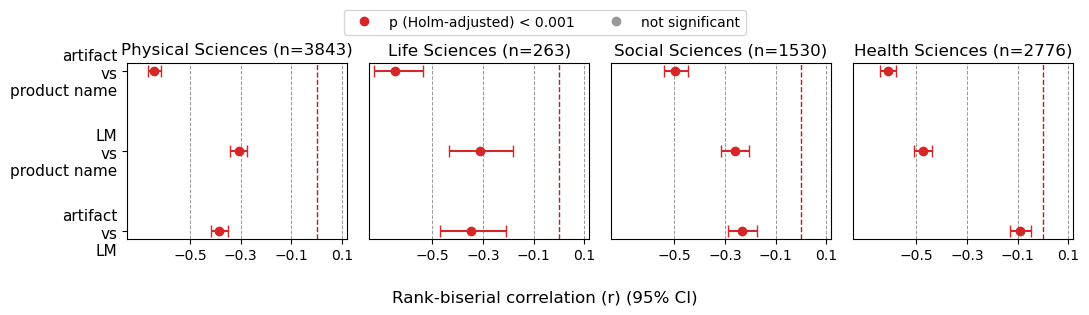

In [77]:
def forest_plot_ax(
    results,
    ax,
    title="Wilcoxon signed-rank effect sizes (matched-pairs rank-biserial r)",
    sort_by_effect=True,
    figsize=None,
):
    """Draw a forest plot of rank-biserial effect sizes with CIs.

    results: list of dicts as returned by wilcoxon_with_effect_size /
    run_multiple_comparisons.
    """
    if sort_by_effect:
        results = results.sort_values("effect_size")

    n = results.n.iloc[0]

    y_pos = np.arange(len(results))

    err_low = results["effect_size"] - results["ci_low"]
    err_high = results["ci_high"] - results["effect_size"]

    ax.errorbar(
        results["effect_size"], y_pos,
        xerr=[err_low, err_high],
        fmt="o", color="C3", markersize=6,
        ecolor="C3", elinewidth=1.5, capsize=4,
    )
    ax.axvline(0, color="firebrick", linestyle="--", linewidth=1)

    xticklabels = [-0.5, -0.3, -0.1, 0.1]
    for x in xticklabels:
        ax.axvline(x, color="0.6", linestyle="--", linewidth=0.7, zorder=0)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(results["label"].apply(add_linebreak), fontsize=11)
    ax.set_xlim(-0.75, 0.12)
    #ax.set_xlabel("Rank-biserial correlation (r)")
    ax.set_xticks(xticklabels)
    #ax.set_xticklabels()
    ax.set_title(f"{title} (n={n})")
    #ax.spines["top"].set_visible(False)
    #ax.spines["right"].set_visible(False)

    #ax.set_xlim(-1.05, 2.3)  # leave room for the annotation text
    #fig.tight_layout()
    return ax
    
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
axes = axes.flatten()

for i, domain in enumerate(domain_order):
    forest_plot_ax(art_lm_prod_results[art_lm_prod_results["domain"] == domain], ax=axes[i], title=domain, sort_by_effect=False)
    if i != 0:
        axes[i].set_yticks([])
        axes[i].set_yticklabels([])
    
handles = [plt.Line2D([0], [0], marker="o", color="C3", linestyle="", label=f"p (Holm-adjusted) < {0.001}"),
       plt.Line2D([0], [0], marker="o", color="0.6", linestyle="", label="not significant")]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.09))
fig.supxlabel("Rank-biserial correlation (r) (95% CI)", fontsize=12)
fig.subplots_adjust(bottom=0.18)
plt.savefig("../figures/et-differences-per-domain.pdf", bbox_inches="tight")
plt.tight_layout()
plt.show()

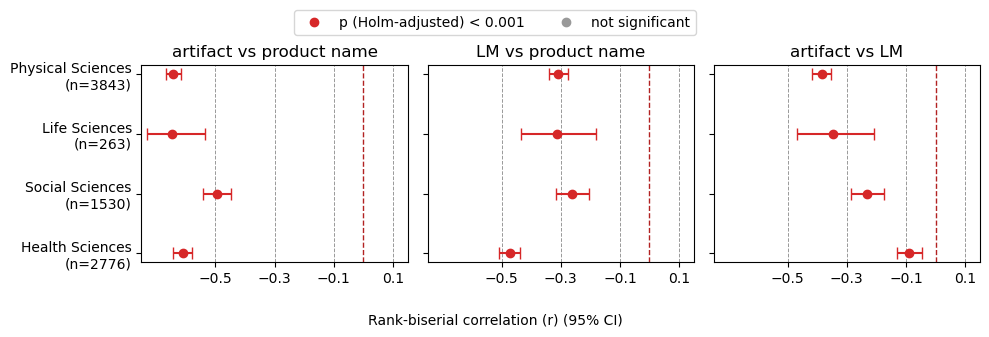

In [49]:
def forest_plot_ax(
    results,
    ax,
    title="Wilcoxon signed-rank effect sizes (matched-pairs rank-biserial r)",
    figsize=None,
):
    """Draw a forest plot of rank-biserial effect sizes with CIs.

    results: list of dicts as returned by wilcoxon_with_effect_size /
    run_multiple_comparisons.
    """

    n_per_domain = results.groupby("domain")["n"].first()

    results = results.sort_values(by="domain", key=lambda col: col.map({v: i for i, v in enumerate(domain_order[::-1])}))

    y_pos = np.arange(len(results))

    err_low = results["effect_size"] - results["ci_low"]
    err_high = results["ci_high"] - results["effect_size"]

    ax.errorbar(
        results["effect_size"], y_pos,
        xerr=[err_low, err_high],
        fmt="o", color="C3", markersize=6,
        ecolor="C3", elinewidth=1.5, capsize=4,
    )
    ax.axvline(0, color="firebrick", linestyle="--", linewidth=1)

    xticklabels = [-0.5, -0.3, -0.1, 0.1]
    for x in xticklabels:
        ax.axvline(x, color="0.6", linestyle="--", linewidth=0.7, zorder=0)

    ax.set_yticks(y_pos)
    ax.set_yticklabels([f"{dom}\n(n={n_per_domain[dom]})" for dom in domain_order[::-1]])
    ax.set_xlim(-0.75, 0.15)
    #ax.set_xlabel("Rank-biserial correlation (r)")
    ax.set_xticks(xticklabels)
    #ax.set_xticklabels()
    ax.set_title(f"{title}")
    #ax.spines["top"].set_visible(False)
    #ax.spines["right"].set_visible(False)

unique_labels = art_lm_prod_results.label.unique()
fig, axes = plt.subplots(1, len(unique_labels), figsize=(10, 3))
axes = axes.flatten()

for i, u in enumerate(unique_labels):
    forest_plot_ax(art_lm_prod_results[art_lm_prod_results["label"] == u], ax=axes[i], title=u)
    if i != 0:
        axes[i].set_yticklabels([])
handles = [plt.Line2D([0], [0], marker="o", color="C3", linestyle="", label=f"p (Holm-adjusted) < {0.001}"),
           plt.Line2D([0], [0], marker="o", color="0.6", linestyle="", label="not significant")]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.09))
fig.supxlabel("Rank-biserial correlation (r) (95% CI)", fontsize=10)
fig.subplots_adjust(bottom=0.18)
plt.savefig("../figures/et-domain-differences.pdf", bbox_inches="tight")
plt.tight_layout()
plt.show()

In [94]:
art_lm = docs_no_human[docs_no_human["contains"] == "artifact_lm"].copy()

In [97]:
art_lm_results = run_multiple_comparisons({"art_lm": (art_lm["avg_score_artifact"], art_lm["avg_score_lm_no_propn"])}, n_resamples=5000)

In [98]:
pd.DataFrame(art_lm_results)

,label,n,statistic,p_value,effect_size,ci_low,ci_high,ci_method
0,art_lm,69831,787775961.0,0.0,-0.35381,-0.361863,-0.346084,BCa


In [ ]:
run_multiple_comparisons(art_lm_per_domain, n_resamples=500).round(3)

In [102]:
pd.DataFrame(art_lm_per_domain_res).round(3)

,label,n,statistic,p_value,effect_size,ci_low,ci_high,ci_method
0,Health Sciences,4667,4145260.0,0.0,-0.239,-0.270,-0.210,BCa
1,Life Sciences,3387,2030972.0,0.0,-0.292,-0.328,-0.254,BCa
2,Physical Sciences,50210,393695238.0,0.0,-0.375,-0.383,-0.365,BCa
3,Social Sciences,11567,22547581.0,0.0,-0.326,-0.344,-0.306,BCa


In [100]:
art_lm_per_domain = {}
for domain, g in art_lm.groupby("domain", observed=True)[["avg_score_artifact", "avg_score_lm_no_propn"]]:
    art_lm_per_domain[domain] = (g["avg_score_artifact"], g["avg_score_lm_no_propn"])

art_lm_per_domain_res = run_multiple_comparisons(art_lm_per_domain, n_resamples=500)
art_lm_per_domain_res

[{'label': 'Health Sciences',
  'n': 4667,
  'statistic': 4145260.0,
  'p_value': 2.323468591915981e-45,
  'effect_size': -0.23889755212123115,
  'ci_low': -0.2702368318251905,
  'ci_high': -0.20950512567418228,
  'ci_method': 'BCa'},
 {'label': 'Life Sciences',
  'n': 3387,
  'statistic': 2030972.0,
  'p_value': 4.765378837845176e-49,
  'effect_size': -0.2920455286185216,
  'ci_low': -0.32841845276431486,
  'ci_high': -0.253859136822459,
  'ci_method': 'BCa'},
 {'label': 'Physical Sciences',
  'n': 50210,
  'statistic': 393695238.0,
  'p_value': 0.0,
  'effect_size': -0.3753581745222375,
  'ci_low': -0.38285990693497246,
  'ci_high': -0.36516987672737433,
  'ci_method': 'BCa'},
 {'label': 'Social Sciences',
  'n': 11567,
  'statistic': 22547581.0,
  'p_value': 1.7666820531767996e-202,
  'effect_size': -0.32596735406838334,
  'ci_low': -0.3436184858281499,
  'ci_high': -0.3063030832802847,
  'ci_method': 'BCa'}]

## Averages per entity

`edocs` contains the average score per `entity_lower` per `id`.

In [50]:
def entity_averages(df):
    return df.groupby(["id", "entity_lower"], observed=True).agg(
        year=("year", "first"),
        domain=("domain", "first"),
        score=("score", "mean"),
        entity_type=("entity_type_updated", "first"),
        size=("id", "size")
    )

In [51]:
edocs = entity_averages(df_dedupl)

In [52]:
edocs = edocs.reset_index()
edocs

,id,entity_lower,year,domain,score,entity_type,size
0,W100457907,agent,2024,Physical Sciences,-0.030153,artifact,1
1,W100457907,approach,2024,Physical Sciences,-0.089126,artifact,1
2,W100457907,model,2024,Physical Sciences,-0.051669,artifact,1
3,W100457907,models,2024,Physical Sciences,-0.073899,artifact,1
4,W100457907,systems,2024,Physical Sciences,-0.100242,artifact,2
...,...,...,...,...,...,...,...
1561609,W87527588,artificial intelligence,2018,Physical Sciences,-0.020558,artifact,1
1561610,W87527588,students,2018,Physical Sciences,0.129198,human,1
1561611,W87527588,system,2018,Physical Sciences,-0.085223,artifact,5
1561612,W87527588,we,2018,Physical Sciences,0.096331,human,1


### How do product name terms affect the scores of artifact terms?

Second attempt to visualize the effect of a product name term to the artifact scores.

In [53]:
presence = pd.crosstab(edocs["id"], edocs["entity_lower"]).gt(0)

In [58]:
artifact_lm_terms = edocs[edocs["entity_type"].isin(("artifact", "lm"))]["entity_lower"].unique().tolist()
artifact_terms = set(edocs[edocs["entity_type"] == "artifact"]["entity_lower"].unique())
lm_terms = set(edocs[edocs["entity_type"] == "lm"]["entity_lower"].unique().tolist())

product_name_terms = edocs[edocs["entity_type"] == "propn_llm"]["entity_lower"].unique().tolist()

In [56]:
effect_matrix = pd.DataFrame(index=artifact_lm_terms, columns=product_name_terms, dtype=float)

for artifact in artifact_lm_terms:
    artifact_rows = edocs[edocs["entity_lower"] == artifact]
    for product_name in product_name_terms:
        has_pn = artifact_rows["id"].map(presence[product_name])
        with_pn = artifact_rows.loc[has_pn, "score"].mean()
        without_pn = artifact_rows.loc[~has_pn, "score"].mean()
        effect_matrix.loc[artifact, product_name] = with_pn - without_pn

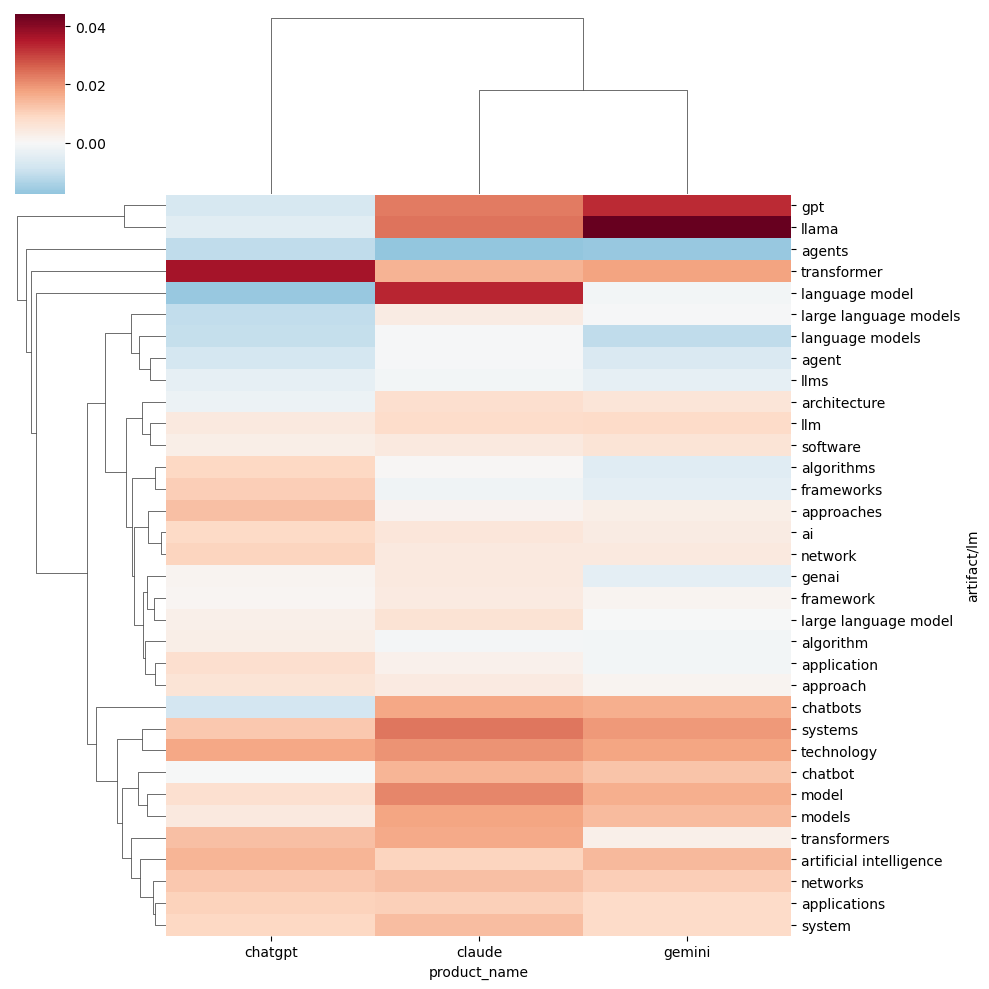

In [81]:
sns.clustermap(effect_matrix.dropna(), yticklabels=1, cmap="RdBu_r", center=0)

The above visualization now shows that certain terms get higher scores when appearing in the same text with product name terms, but not all.

In [59]:
rows = []
for artifact in artifact_lm_terms:
    artifact_rows = edocs[edocs["entity_lower"] == artifact]
    for product_name in product_name_terms:
        has_pn = artifact_rows["id"].map(presence[product_name])
        with_pn = artifact_rows.loc[has_pn, "score"]
        without_pn = artifact_rows.loc[~has_pn, "score"]
        rows.append({
            'product_name': product_name, 'artifact/lm': artifact, 'is_artifact': artifact in artifact_terms,
            'mean_with': with_pn.mean(), 'mean_without': without_pn.mean(),
            'n_with': with_pn.shape[0], 'n_without': without_pn.shape[0],
            'effect': with_pn.mean() - without_pn.mean()
        })

summary = pd.DataFrame(rows).sort_values('effect', ascending=False)
print(summary.to_string(index=False))

product_name                 artifact/lm  is_artifact  mean_with  mean_without  n_with  n_without    effect
      gemini                       llama        False   0.043970     -0.000165     295       3043  0.044134
     chatgpt                 transformer        False  -0.006410     -0.043307     633       7705  0.036897
      claude            foundation model        False  -0.014197     -0.048736       6        613  0.034539
      claude              language model        False  -0.002405     -0.035900      48       7622  0.033494
      gemini                         gpt        False   0.043224      0.010484    1005       9585  0.032740
      claude                       llama        False   0.025367      0.001685     289       3049  0.023681
      claude                     systems         True  -0.055484     -0.078958     537      73598  0.023474
      claude                         gpt        False   0.034652      0.011755     849       9741  0.022896
      claude                

In [63]:
print(summary[summary["is_artifact"]].to_string(index=False))

product_name             artifact/lm  is_artifact  mean_with  mean_without  n_with  n_without    effect
      claude                 systems         True  -0.055484     -0.078958     537      73598  0.023474
      claude                   model         True  -0.014689     -0.035960     836      90090  0.021271
      claude              technology         True  -0.050785     -0.070412     118      48161  0.019627
      gemini                 systems         True  -0.059744     -0.078947     616      73519  0.019203
      gemini              technology         True  -0.052954     -0.070442     216      48063  0.017488
      claude                  models         True  -0.035443     -0.052636     984      79334  0.017194
     chatgpt              technology         True  -0.054183     -0.071171    2294      45985  0.016988
      gemini                   model         True  -0.019915     -0.035951    1055      89871  0.016036
     chatgpt artificial intelligence         True  -0.018303    

In [70]:
summary[(summary["is_artifact"]) & (summary["effect"] > 0)].groupby(["product_name"], observed=True)["effect"].mean().sort_values(ascending=False)

product_name
claude     0.009591
chatgpt    0.008894
gemini     0.008889
Name: effect, dtype: float64

In [71]:
summary[(summary["is_artifact"]) & (summary["effect"] > 0)].groupby(["artifact/lm"], observed=True)["effect"].mean().sort_values(ascending=False)

artifact/lm
systems                    0.018128
technology                 0.018035
model                      0.014828
artificial intelligence    0.012972
networks                   0.011970
models                     0.011869
frameworks                 0.011079
system                     0.010519
applications               0.009813
architecture               0.006544
network                    0.006129
approaches                 0.005994
ai                         0.005865
algorithms                 0.004985
application                0.004850
software                   0.004542
approach                   0.003797
algorithm                  0.003101
framework                  0.002051
Name: effect, dtype: float64

In [79]:
summary[(summary["is_artifact"]) & (summary["effect"] < 0)].groupby(["artifact/lm"], observed=True)["effect"].mean().sort_values()

artifact/lm
agents         -0.015040
algorithms     -0.005163
agent          -0.004779
frameworks     -0.002936
architecture   -0.002395
algorithm      -0.001114
application    -0.001027
Name: effect, dtype: float64

In [76]:
summary[(summary["is_artifact"]) & (summary["effect"] > 0)].groupby(["product_name", "artifact/lm"], observed=True)["effect"].mean().sort_values(ascending=False)

product_name  artifact/lm            
claude        systems                    0.023474
              model                      0.021271
              technology                 0.019627
gemini        systems                    0.019203
              technology                 0.017488
claude        models                     0.017194
chatgpt       technology                 0.016988
gemini        model                      0.016036
chatgpt       artificial intelligence    0.014974
gemini        artificial intelligence    0.014042
              models                     0.013846
claude        system                     0.013650
chatgpt       approaches                 0.013281
claude        networks                   0.013190
chatgpt       networks                   0.011946
              systems                    0.011706
              frameworks                 0.011079
gemini        networks                   0.010775
claude        applications               0.010618
chatgpt     

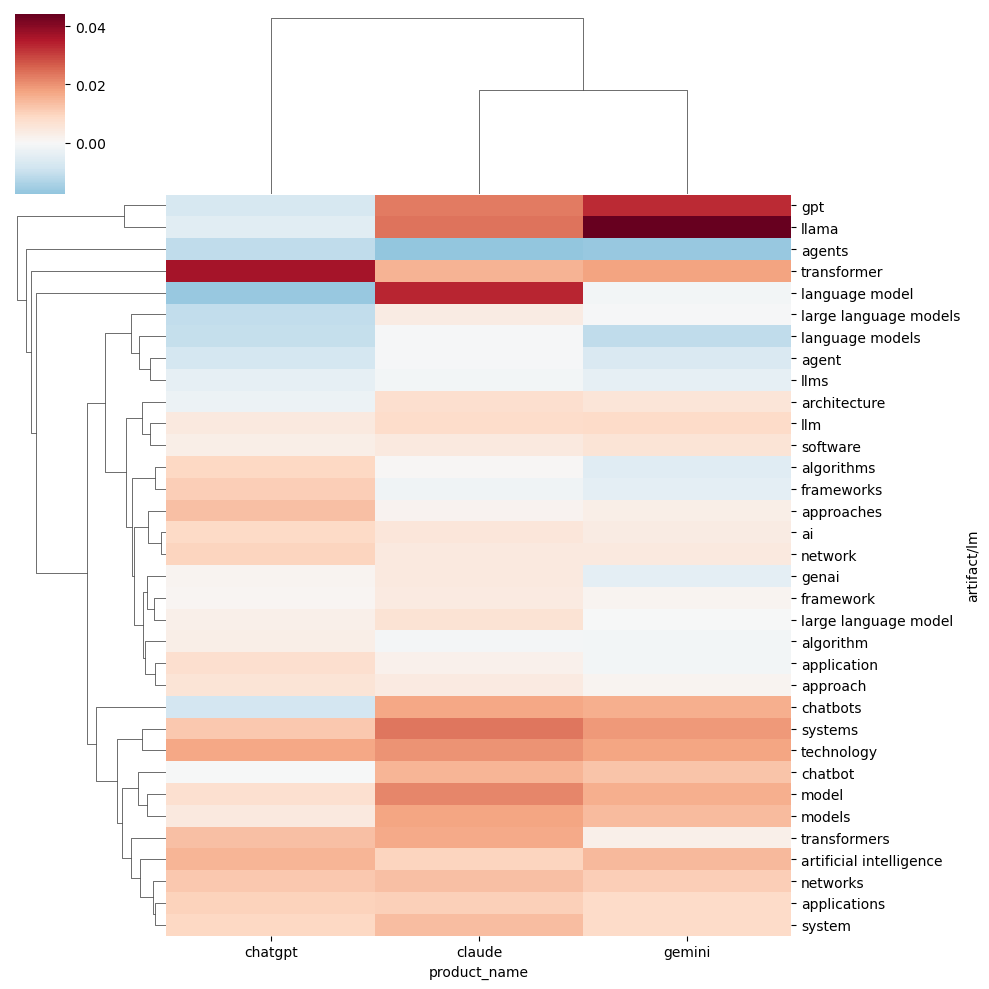

In [80]:
min_n = 20
effect_matrix = (summary[(summary["n_with"] >= min_n) & (summary["n_without"] >= min_n)][["product_name", "artifact/lm", "effect"]]
    .pivot(index="artifact/lm", columns="product_name", values="effect")
    .dropna())
sns.clustermap(effect_matrix, yticklabels=1, cmap="RdBu_r", center=0)

In [74]:
edocs["size"].describe(percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99])

count    1.561614e+06
mean     1.896289e+00
std      1.921102e+00
min      1.000000e+00
1%       1.000000e+00
10%      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      4.000000e+00
99%      9.000000e+00
max      1.680000e+02
Name: size, dtype: float64

In [75]:
edocs["entity_lower"].value_counts()

entity_lower
ai                            154411
we                            133567
artificial intelligence       133385
model                          90926
models                         80318
                               ...  
her                             1121
she                              717
pre-trained language model       684
foundation model                 619
him                              342
Name: count, Length: 64, dtype: int64

In [76]:
entity_std = edocs.groupby(["entity_lower"], observed=True)["score"].std().sort_values(ascending=False)

In [77]:
entity_std.head(20)

entity_lower
user                     0.069395
agents                   0.066697
humans                   0.064714
author                   0.063702
people                   0.063024
users                    0.062458
agent                    0.062432
authors                  0.058858
technology               0.057765
participants             0.056588
patients                 0.053781
large language models    0.053637
chatbots                 0.052707
language models          0.052662
him                      0.052404
claude                   0.051684
chatbot                  0.051409
organizations            0.050628
software                 0.050598
systems                  0.050299
Name: score, dtype: float64

In [78]:
entity_std.tail(20)

entity_lower
frameworks                    0.038123
llama                         0.037390
approaches                    0.036801
foundation model              0.036679
bert                          0.036326
students                      0.036010
llms                          0.035849
ai                            0.035561
architecture                  0.035115
transformer                   0.033818
algorithm                     0.033508
i                             0.032969
gpt                           0.032275
pre-trained language model    0.031062
we                            0.030266
framework                     0.030071
approach                      0.029979
genai                         0.029846
networks                      0.029445
network                       0.027103
Name: score, dtype: float64

To determine if the spread in scores of different entity types is significant, compare that to the spread of human pronouns, that one would assume to be relatively stable.

In [79]:
edocs[edocs["entity_type"] == "human"]["entity_lower"].value_counts()[lambda x: x > 0]

entity_lower
we               133567
user              23439
students          18326
patients          17660
users             17473
researchers       15682
people            12992
participants      11159
humans            10351
organizations      9214
authors            7191
companies          7144
us                 6945
teachers           5705
i                  5572
author             5120
he                 1768
her                1121
she                 717
him                 342
Name: count, dtype: int64

In [33]:
human_pronouns = set(("we", "she", "he", "i", "us", "her", "him"))

In [34]:
edocs["is_human_pronoun"] = edocs.entity_lower.isin(human_pronouns)

In [35]:
edocs.is_human_pronoun.value_counts()

is_human_pronoun
False    1411582
True      150032
Name: count, dtype: int64

In [36]:
edocs["entity_type_updated"] = edocs["entity_type"]
edocs["entity_type_updated"] = edocs["entity_type_updated"].cat.add_categories("human_pron")
edocs.loc[edocs["is_human_pronoun"], "entity_type_updated"] = "human_pron"

In [37]:
edocs.entity_type_updated.value_counts()

entity_type_updated
artifact      1060963
lm             172817
human          161456
human_pron     150032
propn_llm       16346
Name: count, dtype: int64

In [38]:
edocs.groupby("entity_type_updated", observed=True)["score"].agg(["mean", "median", "std", "var", "size"])

,mean,median,std,var,size
entity_type_updated,,,,,
artifact,-0.046608,-0.048999,0.044862,0.002013,1060963
human,0.068424,0.081702,0.062812,0.003945,161456
lm,-0.027104,-0.032727,0.048416,0.002344,172817
propn_llm,-0.005139,-0.010624,0.042848,0.001836,16346
human_pron,0.066958,0.071901,0.031811,0.001012,150032


In [107]:
(edocs.groupby(["entity_type_updated", "domain"], observed=True)["score"].agg(["mean", "median", "std", "var", stats.median_abs_deviation, "size"])
 .style.background_gradient(axis=0))

In [101]:
(edocs.groupby(["entity_type_updated", "domain"], observed=True)["score"].agg(["mean", "median", "std", "var"])
 .unstack("entity_type_updated").mean())

        entity_type_updated
mean    artifact              -0.044203
        human                  0.070373
        lm                    -0.026064
        propn_llm             -0.003994
        human_pron             0.068053
median  artifact              -0.045902
        human                  0.082562
        lm                    -0.031105
        propn_llm             -0.010030
        human_pron             0.073028
std     artifact               0.044031
        human                  0.061640
        lm                     0.048472
        propn_llm              0.043518
        human_pron             0.032010
var     artifact               0.001941
        human                  0.003809
        lm                     0.002356
        propn_llm              0.001899
        human_pron             0.001026
dtype: float64

## Averages per entity type

`etdocs` contains average per `entity_type` calculated from average score per entity (as opposed to averaging all entities with the same type jointly).

In [54]:
etdocs = edocs.groupby(["id", "entity_type_updated"], observed=True).agg(
        year=("year", "first"),
        domain=("domain", "first"),
        score=("score", "mean"),
        size=("id", "size")
    )
etdocs = etdocs.reset_index()
etdocs = etdocs.rename(columns={"entity_type_updated": "entity_type"})
etdocs

,id,entity_type,year,domain,score,size
0,W100457907,artifact,2024,Physical Sciences,-0.069018,5
1,W113601745,artifact,2020,Physical Sciences,-0.082946,4
2,W113601745,human_pron,2020,Physical Sciences,0.082319,1
3,W119893497,lm,2018,Physical Sciences,-0.016020,2
4,W119893497,human_pron,2018,Physical Sciences,0.049990,1
...,...,...,...,...,...,...
629046,W843687078,artifact,2020,Health Sciences,-0.076538,1
629047,W87527588,artifact,2018,Physical Sciences,-0.056352,3
629048,W87527588,human,2018,Physical Sciences,0.129198,1
629049,W87527588,human_pron,2018,Physical Sciences,0.096331,1


In [55]:
etdocs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629051 entries, 0 to 629050
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype   
---  ------       --------------   -----   
 0   id           629051 non-null  category
 1   entity_type  629051 non-null  category
 2   year         629051 non-null  int64   
 3   domain       629051 non-null  category
 4   score        629051 non-null  float64 
 5   size         629051 non-null  int64   
dtypes: category(3), float64(1), int64(2)
memory usage: 28.2 MB


In [56]:
etdocs.domain.value_counts()

domain
Physical Sciences    351007
Social Sciences      141991
Health Sciences       97093
Life Sciences         38960
Name: count, dtype: int64

In [57]:
pd.crosstab(etdocs["domain"], etdocs["entity_type"], margins=True)

entity_type,artifact,human,lm,propn_llm,human_pron,All
domain,,,,,,
Health Sciences,42603,23181,8174,5050,18085,97093
Life Sciences,18681,5972,3904,397,10006,38960
Physical Sciences,151366,51775,56925,5725,85216,351007
Social Sciences,65680,33066,14005,2944,26296,141991
All,278330,113994,83008,14116,139603,629051


## Research question X: Are language model terms different from other technical artifacts?

To investigate this, do a Kruskal-Wallis test for all entity types, followed by a Dunn's post-hoc, and Cliff's delta for effect size.

Quantify the difference between entity types

Kruskal-Wallis: H = 382174.244, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
3,artifact vs human_pron,278330,139603,-0.046186,0.071630,-0.967292,-0.971004,-0.963581,0.000000e+00,True
8,lm vs human_pron,83008,139603,-0.033837,0.071630,-0.915423,-0.920382,-0.910463,0.000000e+00,True
0,artifact vs human,278330,113994,-0.046186,0.076107,-0.872963,-0.876942,-0.868984,0.000000e+00,True
9,propn_llm vs human_pron,14116,139603,-0.011699,0.071630,-0.842976,-0.852970,-0.832982,0.000000e+00,True
4,human vs lm,113994,83008,0.076107,-0.033837,0.797279,0.792116,0.802442,0.000000e+00,True
5,human vs propn_llm,113994,14116,0.076107,-0.011699,0.685627,0.675531,0.695724,0.000000e+00,True
2,artifact vs propn_llm,278330,14116,-0.046186,-0.011699,-0.537492,-0.547254,-0.527729,0.000000e+00,True
7,lm vs propn_llm,83008,14116,-0.033837,-0.011699,-0.321706,-0.332009,-0.311404,0.000000e+00,True
1,artifact vs lm,278330,83008,-0.046186,-0.033837,-0.225915,-0.230390,-0.221440,0.000000e+00,True
6,human vs human_pron,113994,139603,0.076107,0.071630,0.069877,0.065360,0.074395,1.173460e-45,True


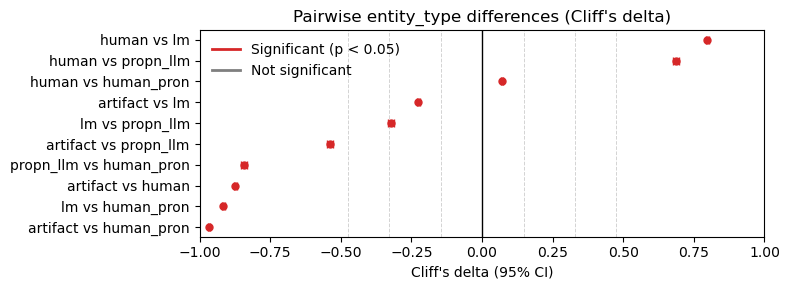

In [78]:
h_stat, kw_p, effects = kruskal_dunn_cliffs(etdocs, "score", "entity_type")
display(effects)

fig, ax = forest_plot_cliffs(effects, title=f"Pairwise entity_type differences (Cliff's delta)")
plt.show()

Kruskal-Wallis: H = 10064.152, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
1,Health Sciences vs Physical Sciences,42603,151366,-0.036502,-0.050600,0.283002,0.276796,0.289208,0.000000e+00,True
5,Physical Sciences vs Social Sciences,151366,65680,-0.050600,-0.041222,-0.179896,-0.185183,-0.174609,0.000000e+00,True
0,Health Sciences vs Life Sciences,42603,18681,-0.036502,-0.045661,0.169556,0.159626,0.179486,5.880782e-234,True
3,Life Sciences vs Physical Sciences,18681,151366,-0.045661,-0.050600,0.118770,0.109995,0.127545,1.889653e-149,True
2,Health Sciences vs Social Sciences,42603,65680,-0.036502,-0.041222,0.098918,0.091878,0.105957,3.848846e-175,True
4,Life Sciences vs Social Sciences,18681,65680,-0.045661,-0.041222,-0.066475,-0.075858,-0.057092,5.206254e-41,True


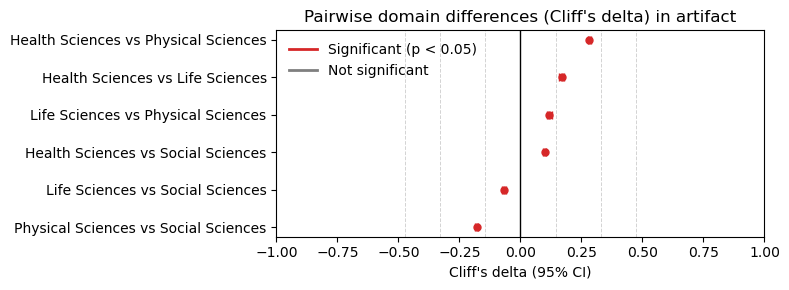

Kruskal-Wallis: H = 619.761, p = 5.24e-134


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
4,Life Sciences vs Social Sciences,3904,14005,-0.039787,-0.027628,-0.177707,-0.198187,-0.157227,1.087988e-66,True
0,Health Sciences vs Life Sciences,8174,3904,-0.028799,-0.039787,0.151579,0.129564,0.173595,3.805382e-45,True
5,Physical Sciences vs Social Sciences,56925,14005,-0.035332,-0.027628,-0.111226,-0.121899,-0.100552,1.360500e-90,True
1,Health Sciences vs Physical Sciences,8174,56925,-0.028799,-0.035332,0.088171,0.074786,0.101556,4.841107e-38,True
3,Life Sciences vs Physical Sciences,3904,56925,-0.039787,-0.035332,-0.072836,-0.091558,-0.054115,2.417212e-13,True
2,Health Sciences vs Social Sciences,8174,14005,-0.028799,-0.027628,-0.017689,-0.033440,-0.001938,6.760760e-03,True


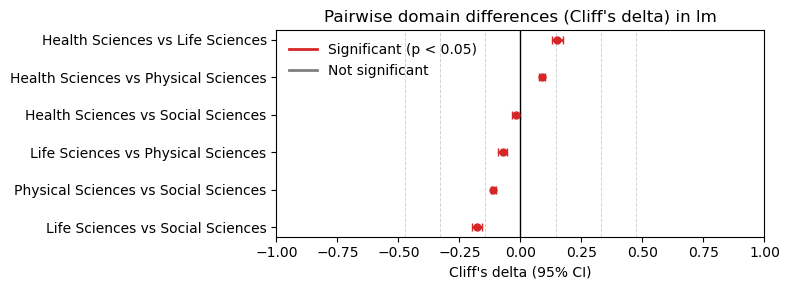

Kruskal-Wallis: H = 271.525, p = 1.444e-58


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
1,Health Sciences vs Physical Sciences,5050,5725,-0.003924,-0.016854,0.177760,0.155913,0.199606,3.836188e-55,True
2,Health Sciences vs Social Sciences,5050,2944,-0.003924,-0.015296,0.140906,0.114665,0.167147,2.478814e-26,True
3,Life Sciences vs Physical Sciences,397,5725,-0.007453,-0.016854,0.135699,0.076965,0.194432,1.264146e-05,True
4,Life Sciences vs Social Sciences,397,2944,-0.007453,-0.015296,0.103723,0.043213,0.164233,1.372626e-03,True
0,Health Sciences vs Life Sciences,5050,397,-0.003924,-0.007453,0.028894,-0.030094,0.087882,2.320949e-01,False
5,Physical Sciences vs Social Sciences,5725,2944,-0.016854,-0.015296,-0.028296,-0.053961,-0.002631,3.255380e-02,True


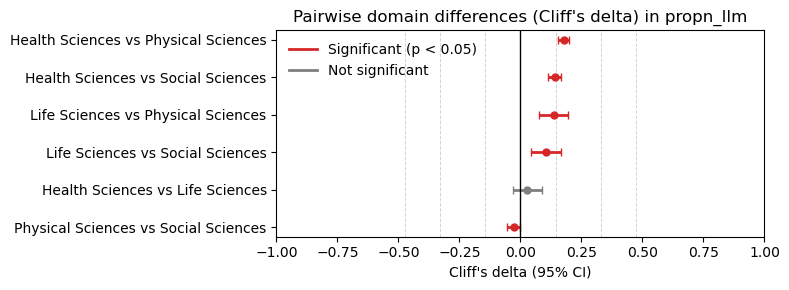

Kruskal-Wallis: H = 1732.323, p = 0


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
2,Health Sciences vs Social Sciences,23181,33066,0.089265,0.069170,0.189600,0.179907,0.199294,0.000000e+00,True
1,Health Sciences vs Physical Sciences,23181,51775,0.089265,0.073063,0.167317,0.158374,0.176260,3.975621e-295,True
0,Health Sciences vs Life Sciences,23181,5972,0.089265,0.078245,0.107395,0.090974,0.123817,1.029115e-37,True
4,Life Sciences vs Social Sciences,5972,33066,0.078245,0.069170,0.080573,0.064662,0.096483,1.301540e-22,True
3,Life Sciences vs Physical Sciences,5972,51775,0.078245,0.073063,0.058662,0.043198,0.074127,1.149798e-13,True
5,Physical Sciences vs Social Sciences,51775,33066,0.073063,0.069170,0.020649,0.012683,0.028616,2.235514e-07,True


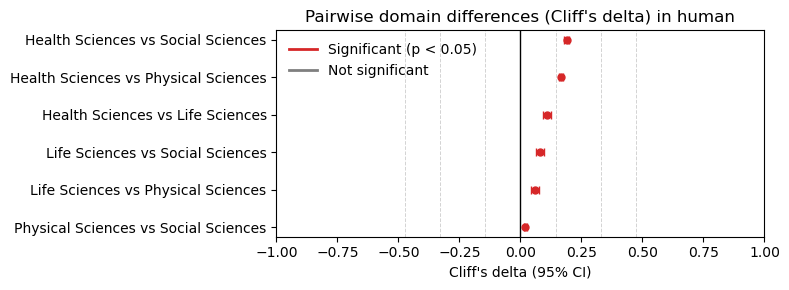

Kruskal-Wallis: H = 730.275, p = 5.715e-158


,pair,n1,n2,median1,median2,cliffs_delta,ci_low,ci_high,p_value,significant
5,Physical Sciences vs Social Sciences,85216,26296,0.070181,0.075022,-0.104732,-0.112714,-0.096749,1.572414e-143,True
1,Health Sciences vs Physical Sciences,18085,85216,0.072966,0.070181,0.062036,0.052772,0.071301,4.794370e-40,True
4,Life Sciences vs Social Sciences,10006,26296,0.072531,0.075022,-0.059858,-0.073150,-0.046566,1.210164e-17,True
3,Life Sciences vs Physical Sciences,10006,85216,0.072531,0.070181,0.045717,0.033759,0.057675,4.301489e-13,True
2,Health Sciences vs Social Sciences,18085,26296,0.072966,0.075022,-0.037958,-0.048890,-0.027027,4.301489e-13,True
0,Health Sciences vs Life Sciences,18085,10006,0.072966,0.072531,0.019798,0.005699,0.033897,1.200167e-02,True


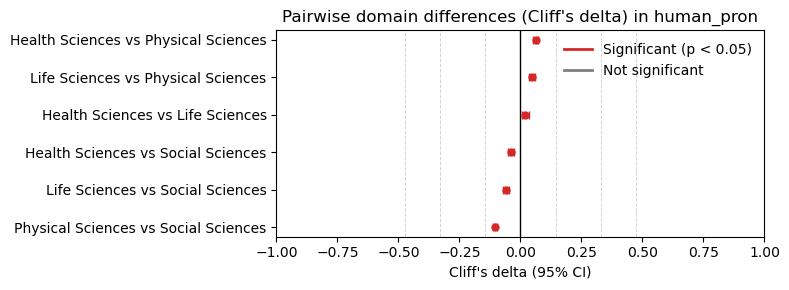

In [66]:
for et in ("artifact", "lm", "propn_llm", "human", "human_pron"):
    sub = etdocs[etdocs["entity_type"] == et].copy()
    h_stat, kw_p, effects = kruskal_dunn_cliffs(sub, "score", "domain")
    display(effects)
    
    fig, ax = forest_plot_cliffs(effects, title=f"Pairwise domain differences (Cliff's delta) in {et}")
    plt.show()

The highest effect size for human pronouns between domains, |0.11|, comes from the above table (Physical Sciences vs Social Sciences).

How do the scores vary (or how spread are the scores) within an entity type and a domain?

In [114]:
etdocs.groupby(["domain", "entity_type"], observed=True)["score"].std().unstack("domain")

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_type,,,,
artifact,0.031156,0.030345,0.029621,0.032167
human,0.052141,0.058027,0.060238,0.058945
lm,0.044221,0.037065,0.037531,0.041406
propn_llm,0.037161,0.044785,0.040445,0.042761
human_pron,0.032587,0.029759,0.030472,0.030078


Interestingly, human terms seem to have the most spread in them. This is, however, likely due to `organisations` and `companies` being included in them.

In [115]:
etdocs.groupby(["entity_type"], observed=True)["score"].std()

entity_type
artifact      0.030992
human         0.058622
lm            0.039012
propn_llm     0.040194
human_pron    0.030703
Name: score, dtype: float64

In [134]:
etdocs["score"].std()

0.06482339825632596

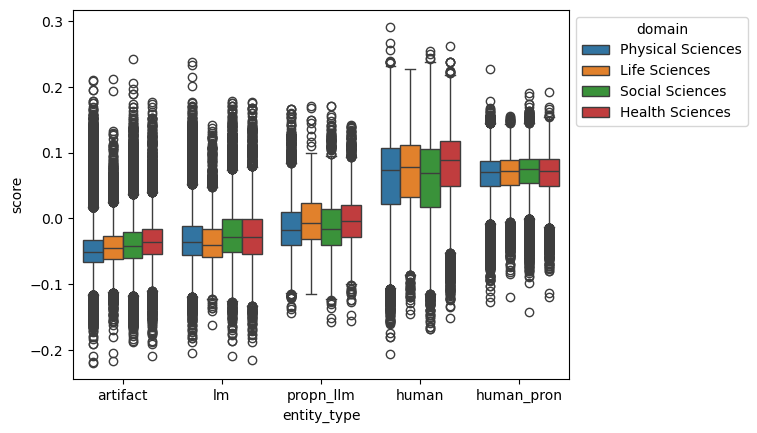

In [190]:
ax = sns.boxplot(etdocs, x="entity_type", y="score", hue="domain", order=et_order, hue_order=domain_order)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

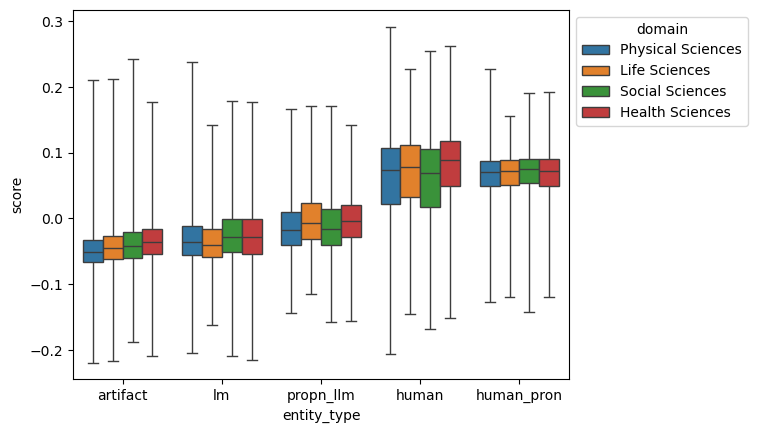

In [189]:
ax = sns.boxplot(etdocs, x="entity_type", y="score", hue="domain", order=et_order, hue_order=domain_order, whis=(0, 100))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

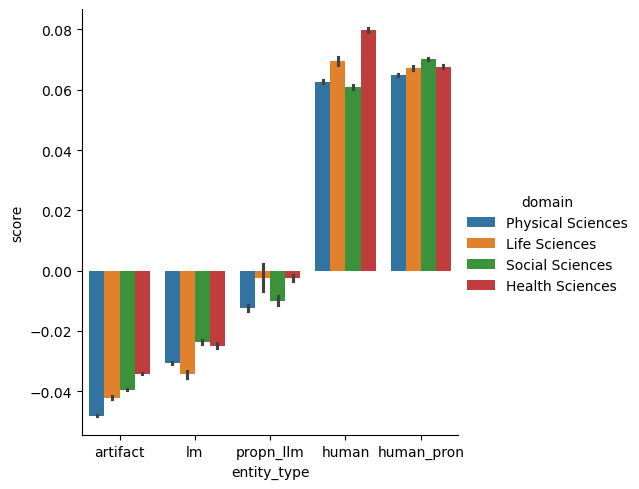

In [69]:
sns.catplot(
    data=etdocs, x='entity_type', y='score', hue='domain',
    hue_order=domain_order, order=et_order,
    kind='bar', estimator='mean'
)
plt.show()

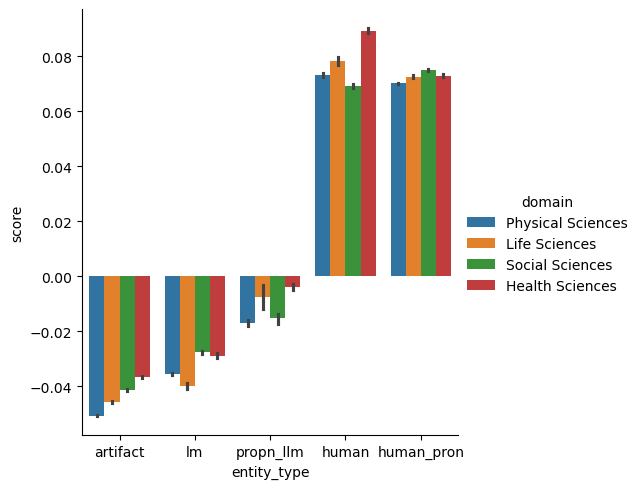

In [70]:
sns.catplot(
    data=etdocs, x='entity_type', y='score', hue='domain',
    hue_order=domain_order, order=et_order,
    kind='bar', estimator='median'
)
plt.show()

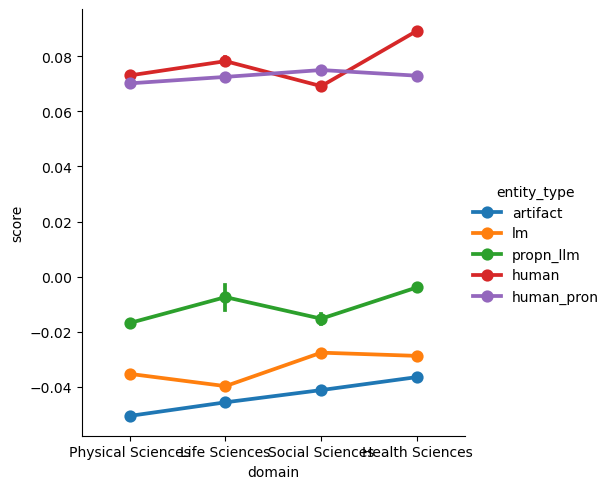

In [75]:
sns.catplot(
    data=etdocs, x='domain', y='score', hue='entity_type',
    hue_order=et_order, order=domain_order,
    kind='point', estimator='median'
)
plt.show()

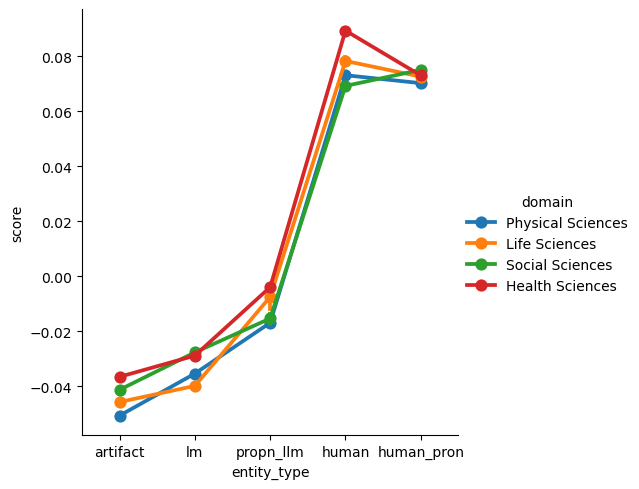

In [73]:
sns.catplot(
    data=etdocs, x='entity_type', y='score', hue='domain',
    hue_order=domain_order, order=et_order,
    kind='point', estimator='median'
)
plt.show()

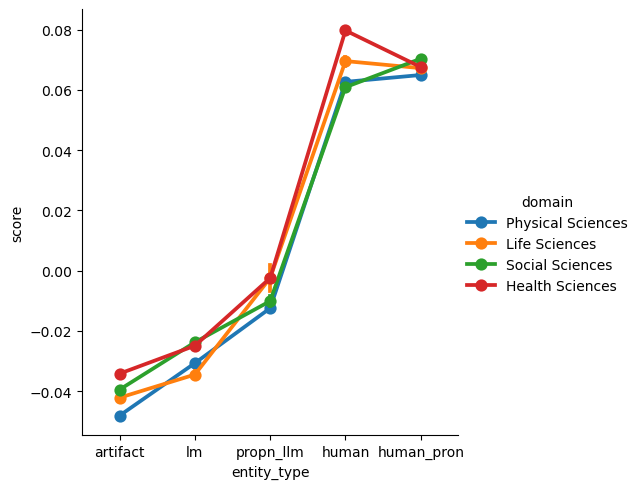

In [74]:
sns.catplot(
    data=etdocs, x='entity_type', y='score', hue='domain',
    hue_order=domain_order, order=et_order,
    kind='point', estimator='mean'
)
plt.show()

In [83]:
etdocs_nohum = etdocs[etdocs["entity_type"].isin(("artifact", "lm", "propn_llm"))].copy()
etdocs_nohum["entity_type"] = etdocs_nohum["entity_type"].cat.remove_unused_categories()

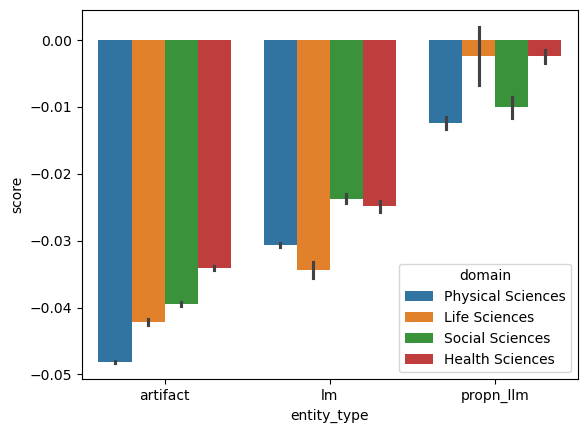

In [87]:
sns.barplot(
    data=etdocs_nohum, x='entity_type', y='score', hue='domain',
    hue_order=domain_order, order=et_order[:-2], estimator='mean'
)
plt.show()

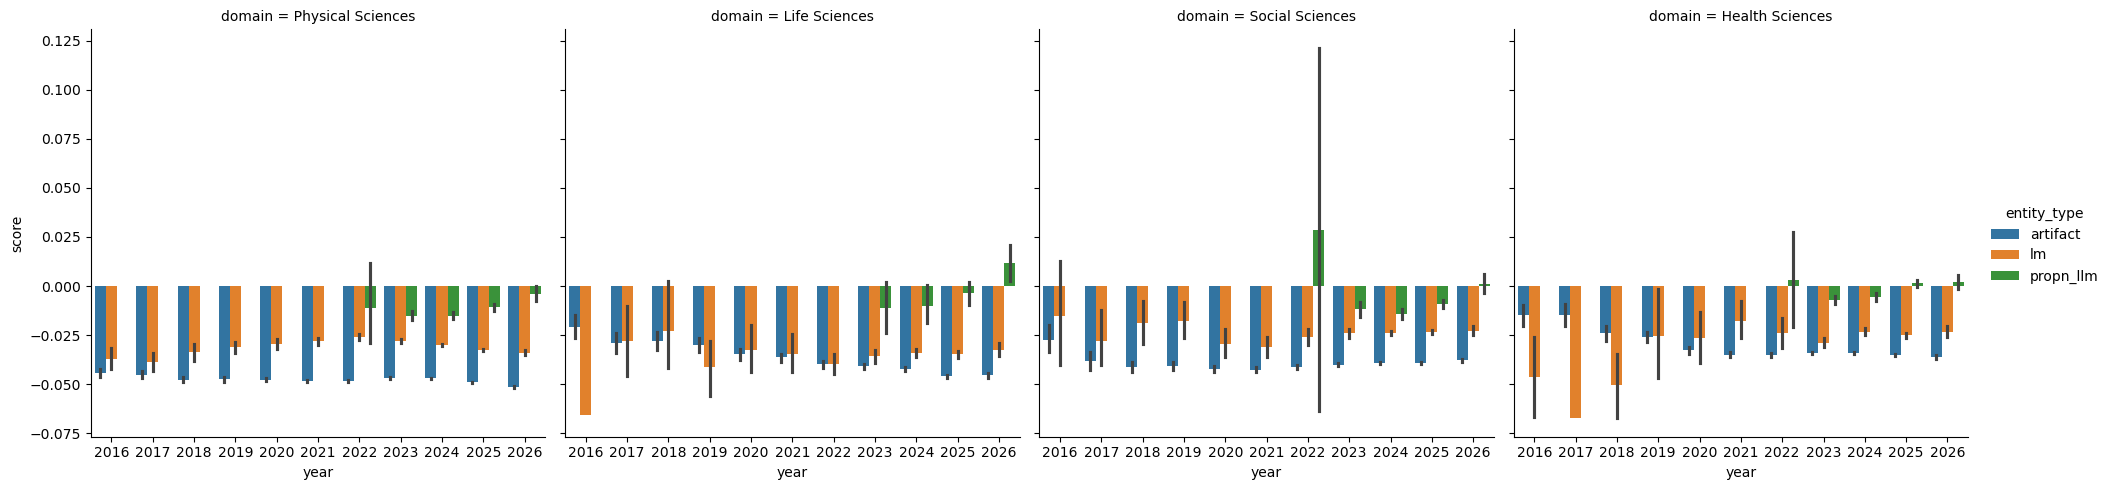

In [117]:
sns.catplot(
    data=etdocs_nohum, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order[:-1], col_order=domain_order,
    kind='bar', estimator='mean',
    order=sorted(etdocs['year'].unique())
)
plt.show()

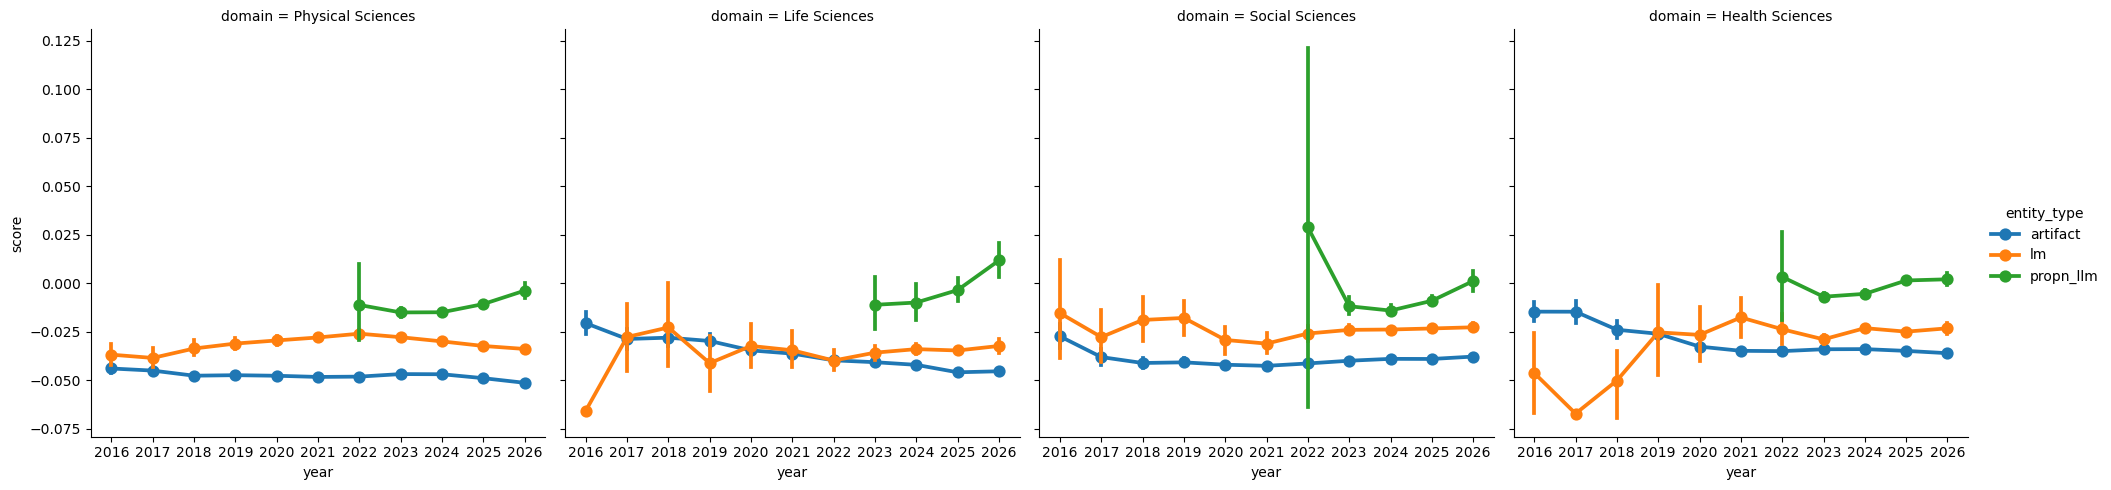

In [118]:
sns.catplot(
    data=etdocs_nohum, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order[:-1], col_order=domain_order,
    kind='point', estimator='mean',
    order=sorted(etdocs['year'].unique())
)
plt.show()

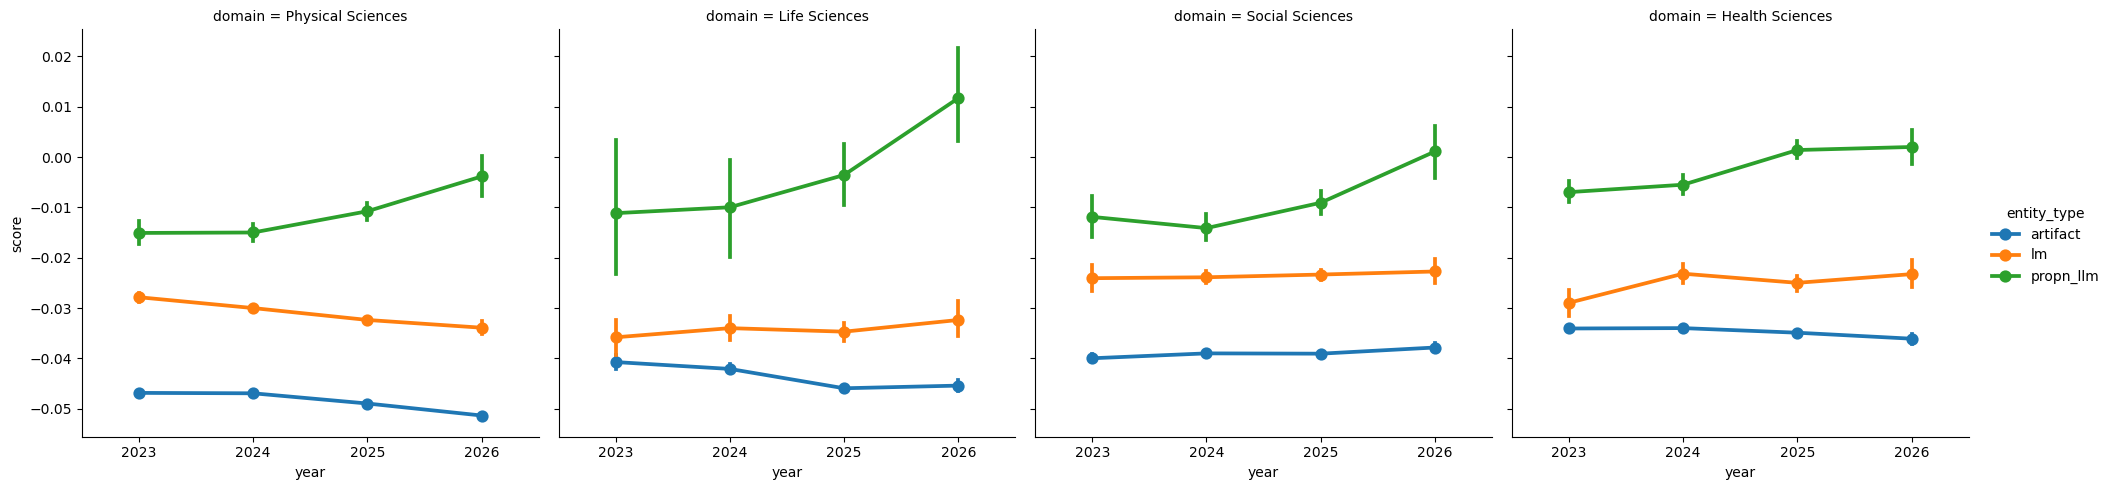

In [119]:
sns.catplot(
    data=etdocs_nohum[(etdocs_nohum["year"] > 2022)], x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order[:-1], col_order=domain_order,
    kind='point', estimator='mean'
)
plt.show()

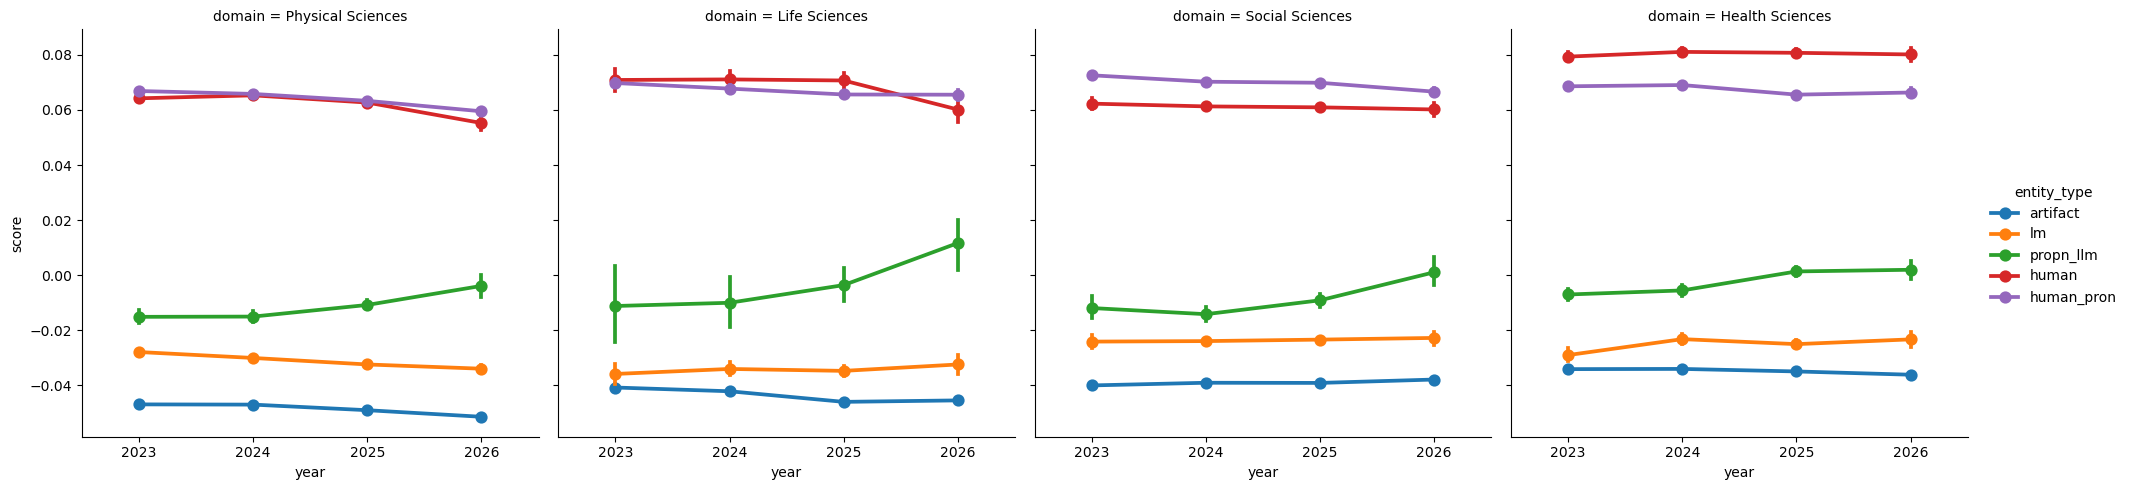

In [122]:
sns.catplot(
    data=etdocs[(etdocs["year"] > 2022)], x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    kind='point', estimator='mean'
)
plt.show()

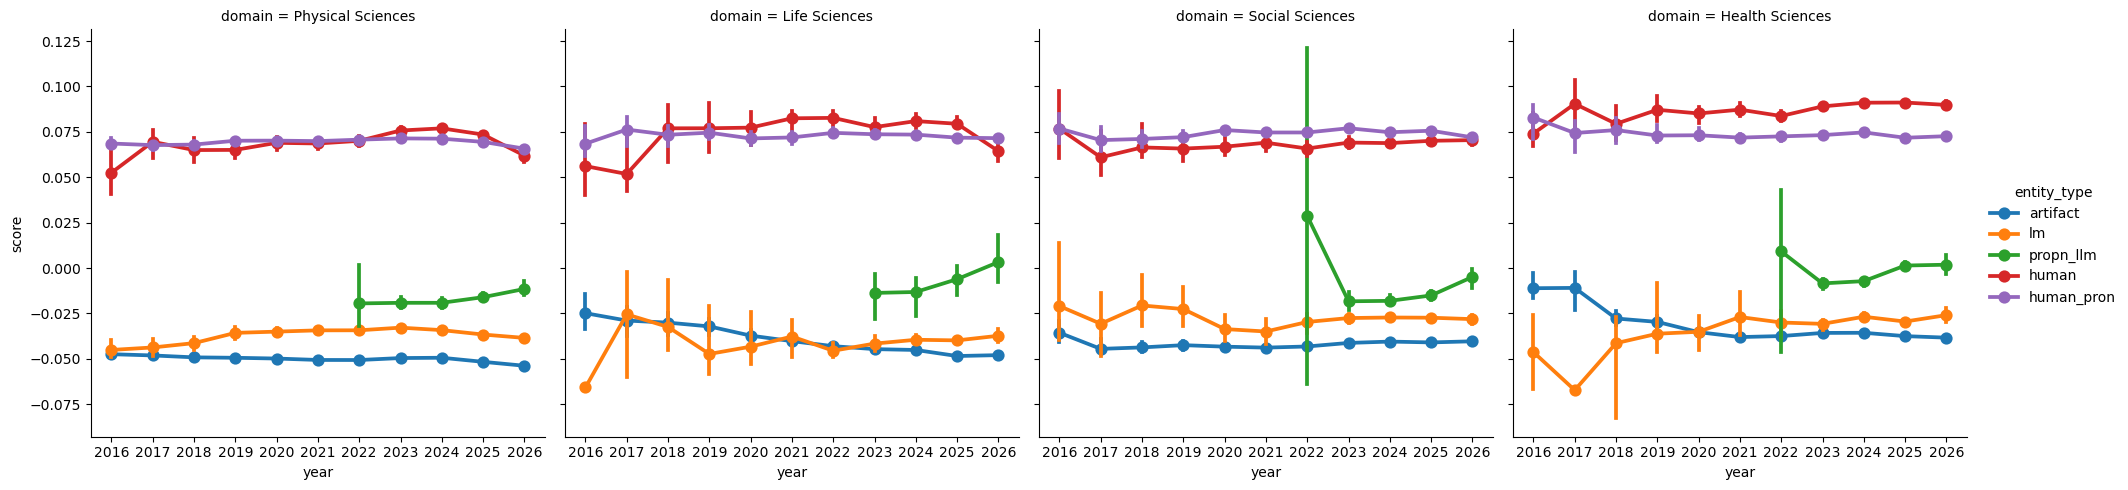

In [175]:
sns.catplot(
    data=etdocs, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    kind='point', estimator='median'
)
plt.show()

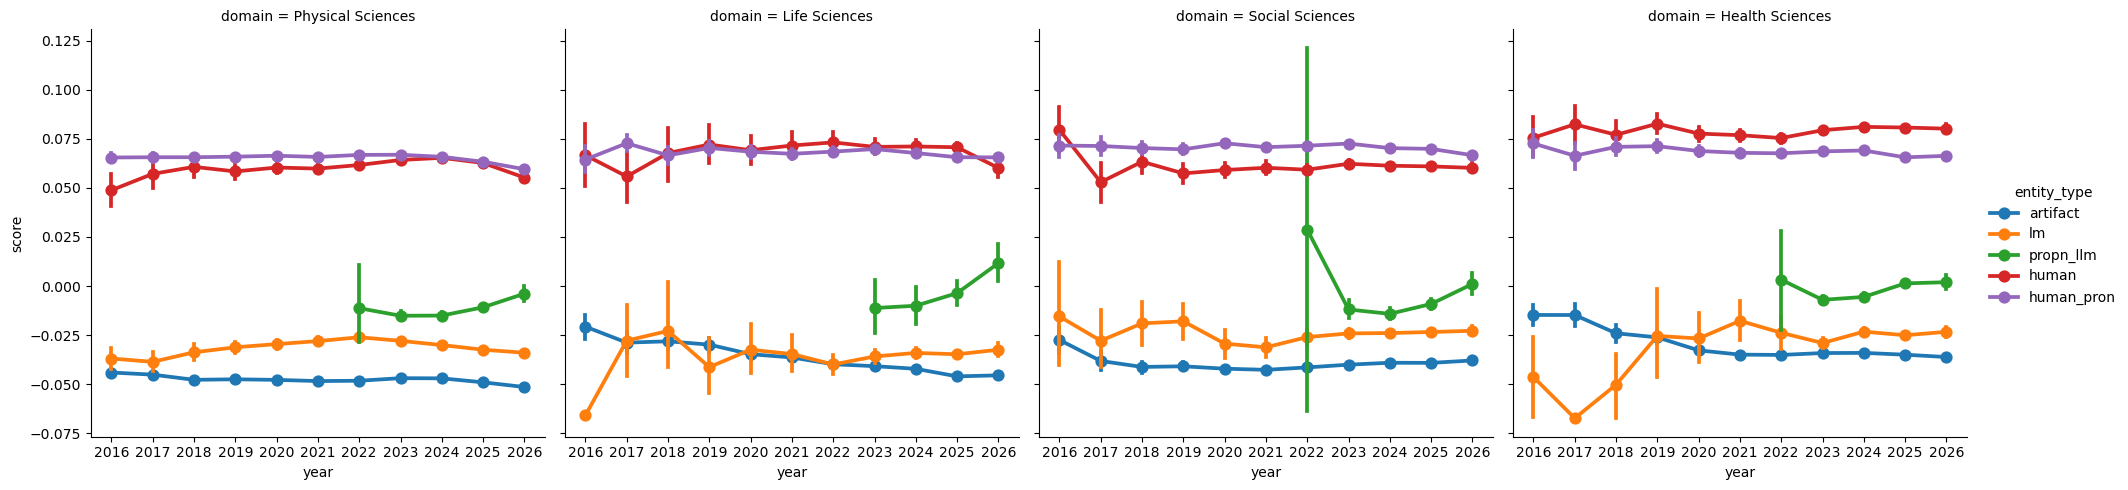

In [139]:
sns.catplot(
    data=etdocs, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    kind='point', estimator='mean'
)
plt.show()

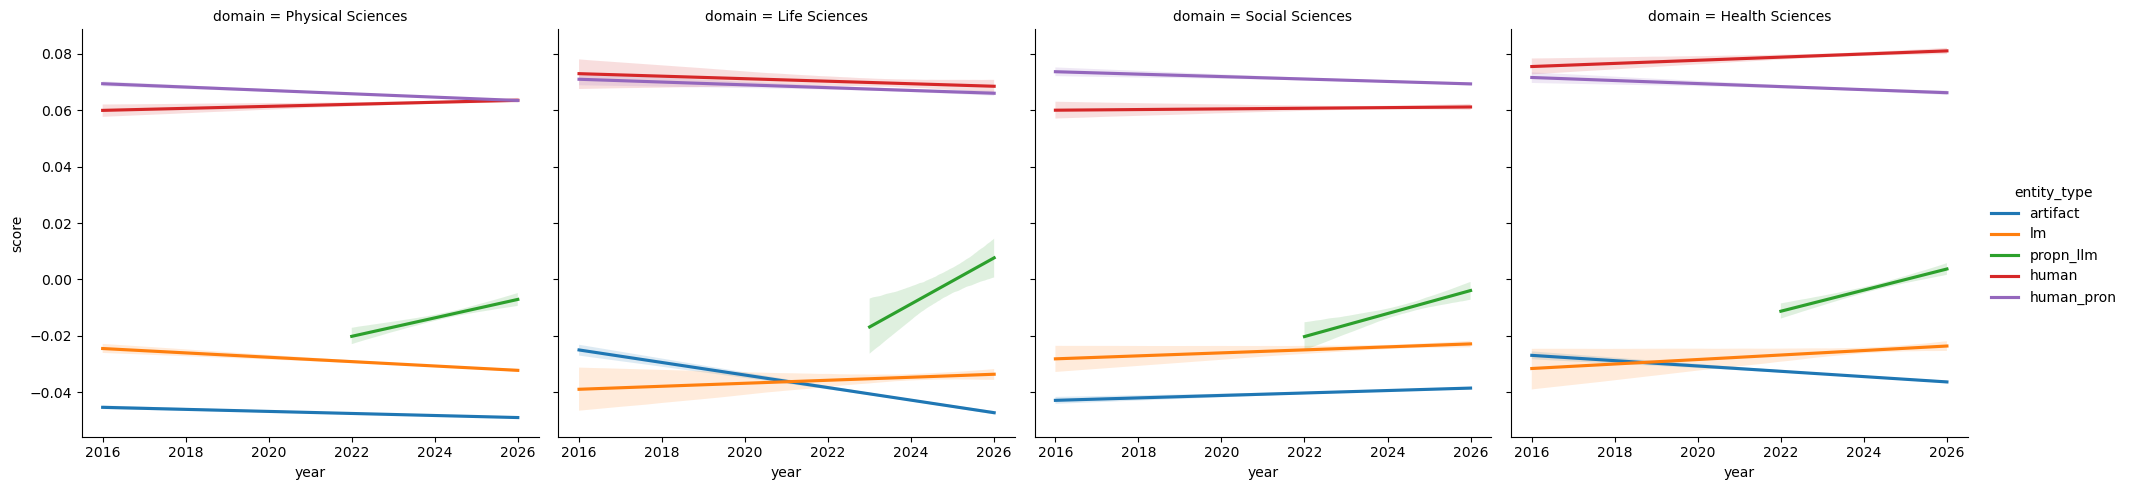

In [140]:
sns.lmplot(
    data=etdocs, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    scatter=False
)
plt.show()

## Artificial intelligence as a special case

Are there differences in how terms "AI" or "artificial intelligence" are treated in different domains?

In [157]:
ai_docs = edocs[edocs["entity_lower"].isin(("ai", "artificial intelligence", "genai"))].copy()
ai_docs["entity_lower"] = ai_docs["entity_lower"].cat.remove_unused_categories()

<Axes: xlabel='domain'>

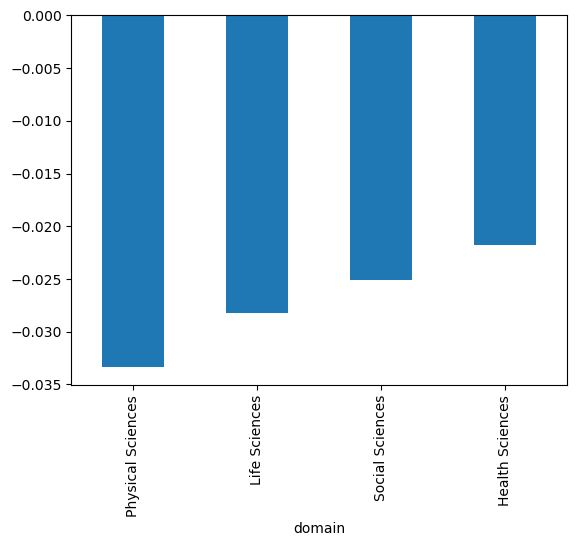

In [48]:
ai_docs.groupby("domain", observed=True)["score"].mean()[domain_order].plot.bar()

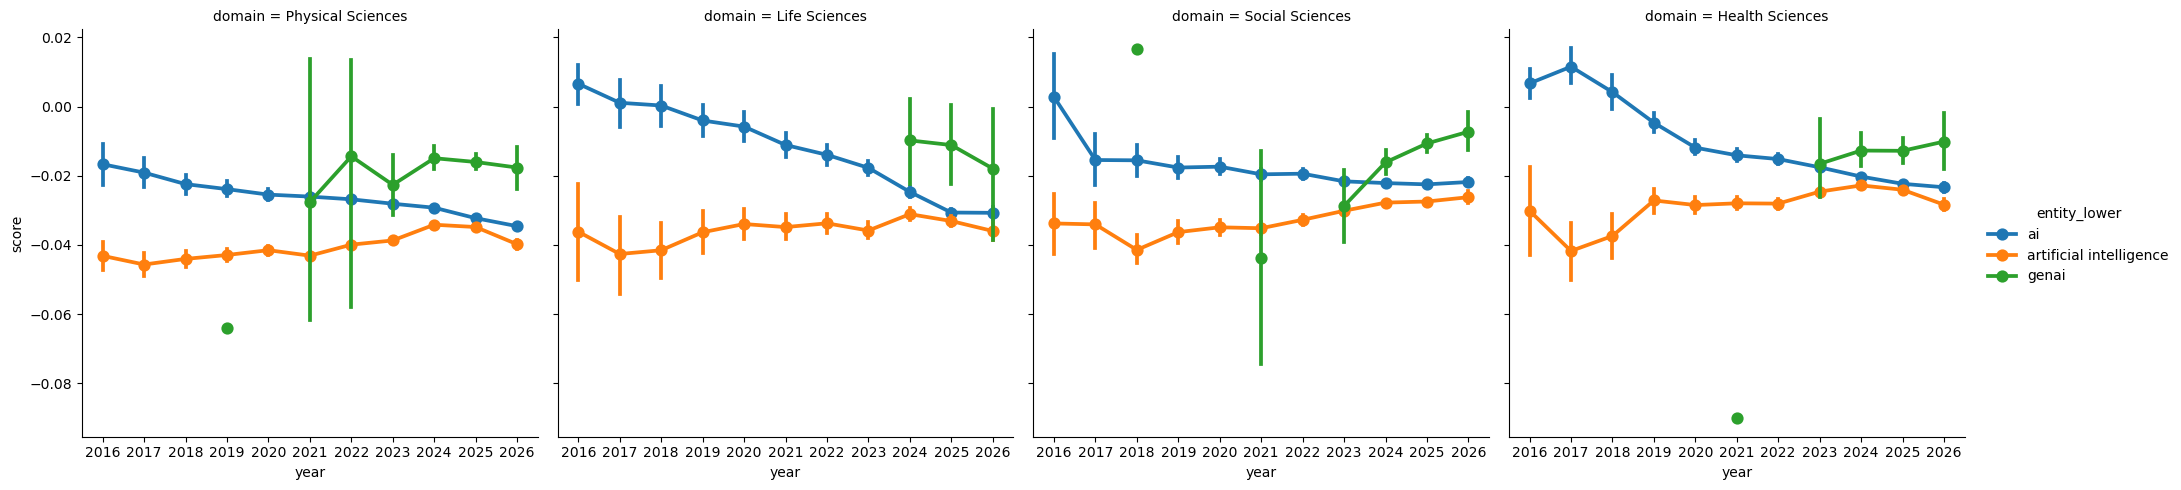

In [49]:
sns.catplot(
    data=ai_docs, x='year', y='score', hue='entity_lower', col='domain', col_order=domain_order,
    kind='point', estimator='mean'
)
plt.show()

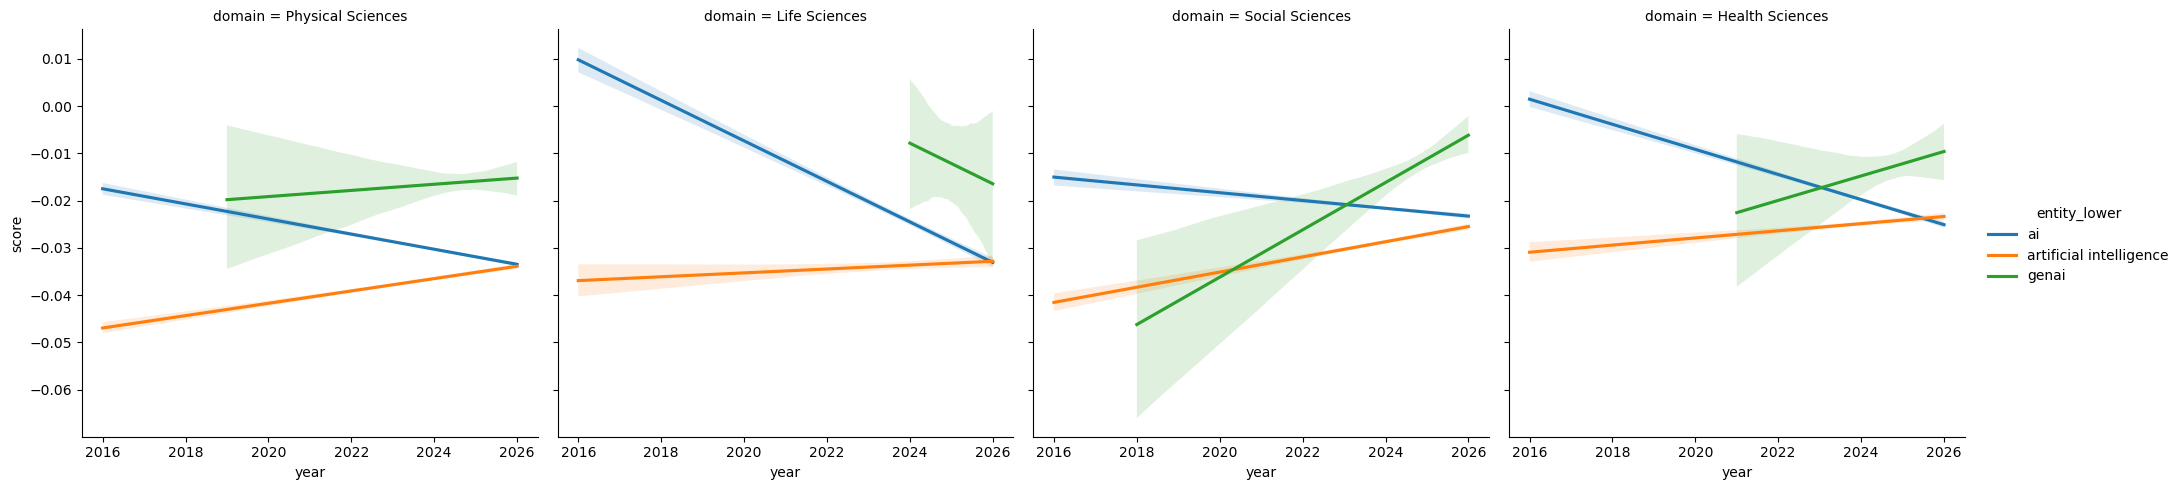

In [52]:
sns.lmplot(
    data=ai_docs, x='year', y='score', hue='entity_lower', col='domain', col_order=domain_order,
    scatter=False
)
plt.show()

In [59]:
ai_docs["year_mod"] = ai_docs["year"] - ai_docs["year"].min()

## Inspect a smaller subset of terms

In [50]:
terms = {"agent", "ai", "chatbot", "algorithm", "language model", "model", "system"}
subdocs = edocs[edocs["entity_lower"].isin(terms)].copy()
subdocs["entity_lower"] = subdocs["entity_lower"].cat.remove_unused_categories()

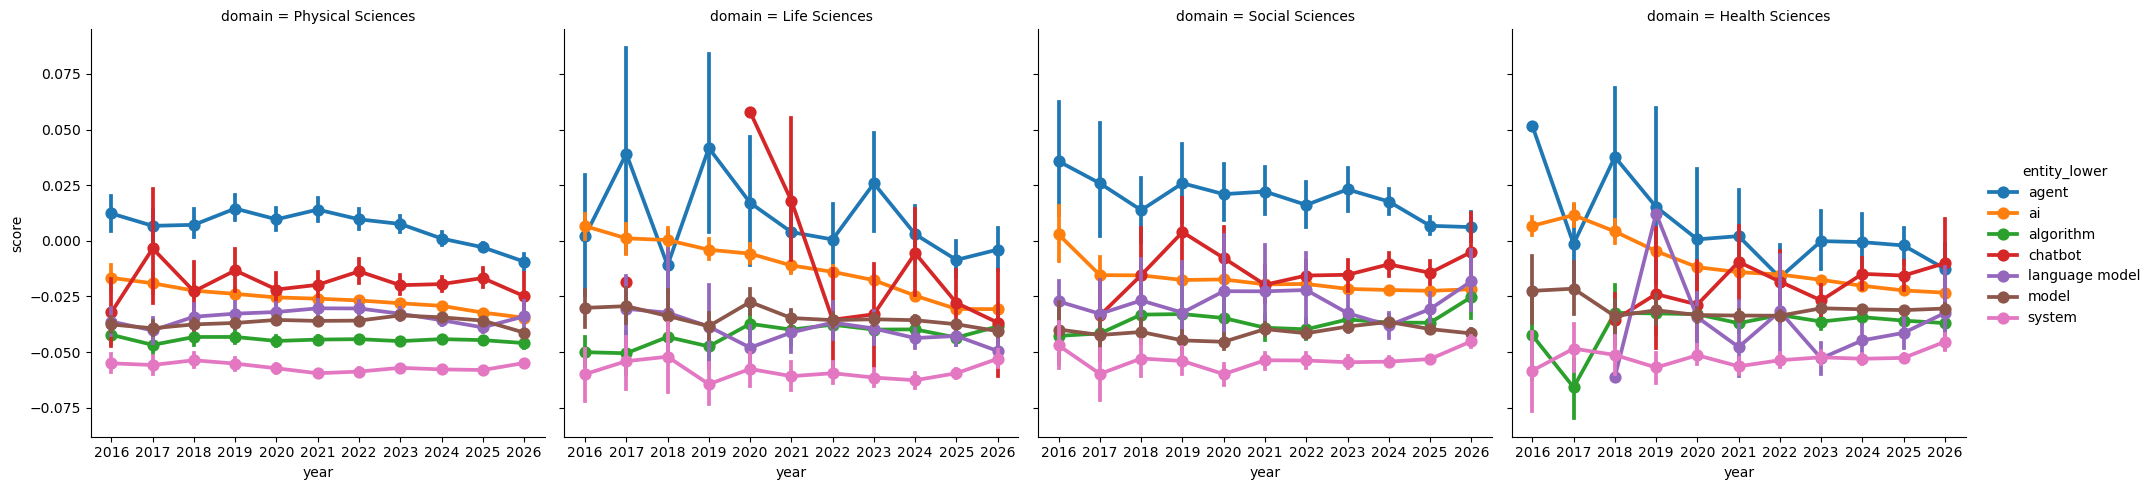

In [51]:
sns.catplot(
    data=subdocs, x='year', y='score', hue='entity_lower', col='domain', col_order=domain_order,
    kind='point', estimator='mean'
)
plt.show()

## Analyze the significance of differences between domains in entities

Per an earlier finding, the observed higher scores in Health Sciences can be, at least partially, attributed to the frequencies of the used entities. But are individual entities treated differently in different domains?

In [51]:
for et in edocs.entity_type.unique():
    subs = edocs[edocs["entity_type"] == et]
    display(subs.groupby(["domain", "entity_lower"], observed=True).size().unstack("domain"))

domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
agent,585,585,10508,2596
agents,857,682,8775,3045
ai,29008,10496,71990,42917
algorithm,3167,1246,13379,2515
algorithms,5061,1896,16530,5496
application,5693,2597,19146,7891
applications,6174,2693,26939,7915
approach,7929,3919,38034,14938
approaches,4521,2682,21014,7633


domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
author,838,340,1895,2047
authors,1822,437,2645,2287
companies,398,165,2623,3958
he,427,158,551,632
her,295,78,302,446
him,61,32,106,143
humans,1050,776,5315,3210
i,1024,622,1991,1935
organizations,794,128,3457,4835


domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
bert,180,147,2812,637
chatbot,972,118,2980,1458
chatbots,985,85,2907,1843
gpt,1664,416,6707,1803
language model,525,659,5733,753
language models,671,981,11670,1678
large language models,3104,1344,27917,6090
llms,2936,1026,23880,5112
lm,52,59,1152,89


domain,Health Sciences,Life Sciences,Physical Sciences,Social Sciences
entity_lower,,,,
chatgpt,4710,255,4246,2367
claude,421,112,969,465
gemini,723,127,1379,572


(From [scipy.stats.friedmanchisquare](https://docs.scipy.org/doc/scipy-1.18.0/reference/generated/scipy.stats.friedmanchisquare.html#scipy.stats.friedmanchisquare):)

"The Friedman test tests the null hypothesis that repeated samples of the same individuals have the same distribution. It is often used to test for consistency among samples obtained in different ways. For example, if two sampling techniques are used on the same set of individuals, the Friedman test can be used to determine if the two sampling techniques are consistent."

NOTE! I am not fully sure if this would be a valid approach, and it has thus not been included in the reported results.

artifact
FriedmanchisquareResult(statistic=34.8857142857143, pvalue=1.2878950043554857e-07) !
              HS        LS            PS        SS
HS  1.000000e+00  0.001209  2.298974e-07  0.405339
LS  1.209267e-03  1.000000  2.767112e-01  0.137089
PS  2.298974e-07  0.276711  1.000000e+00  0.000465
SS  4.053394e-01  0.137089  4.647091e-04  1.000000


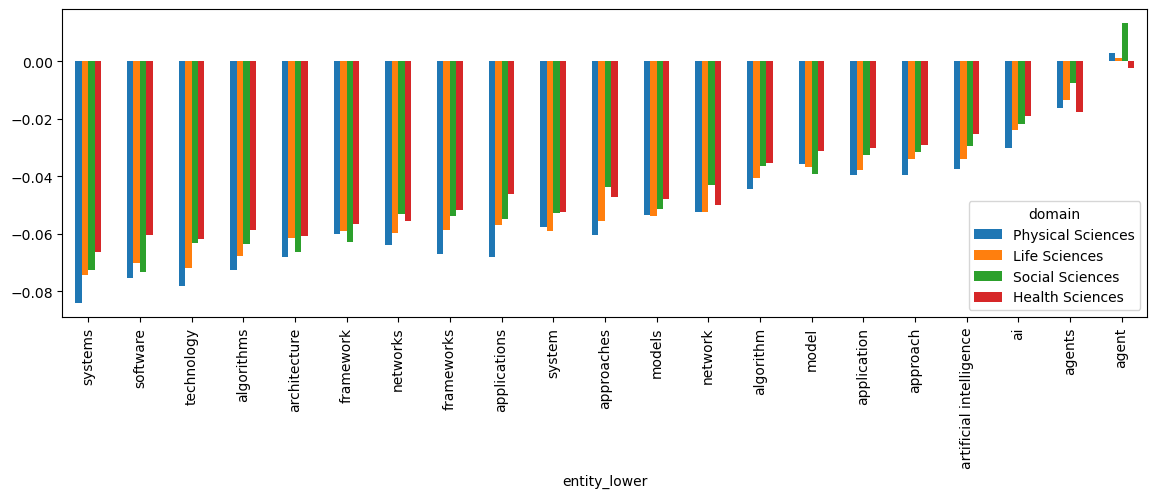

human_pron
FriedmanchisquareResult(statistic=6.599999999999994, pvalue=0.085801087400123) 


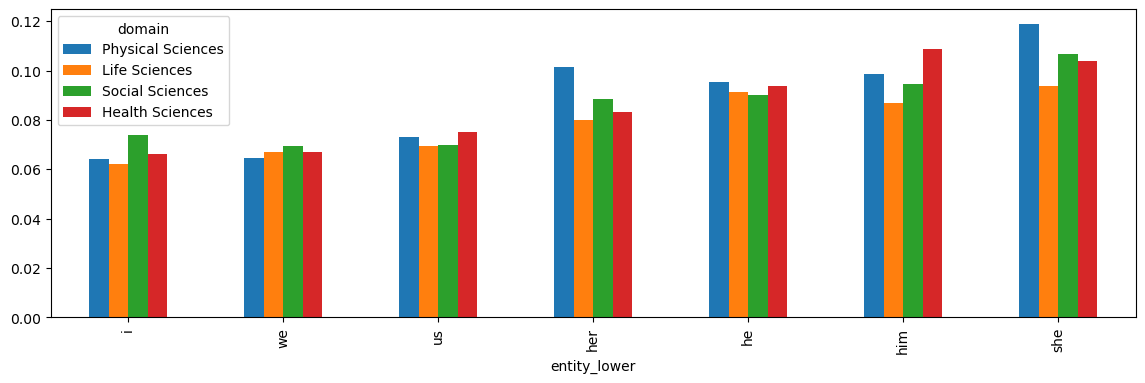

lm
FriedmanchisquareResult(statistic=6.659999999999968, pvalue=0.08356162963917335) 


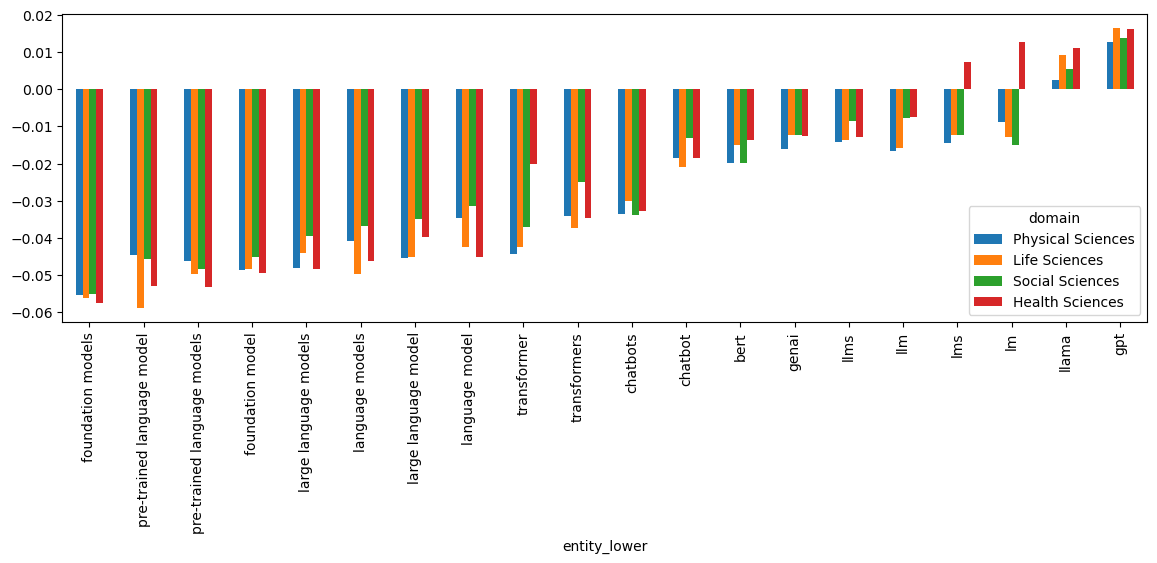

human
FriedmanchisquareResult(statistic=16.846153846153868, pvalue=0.0007601411254242609) !
          HS        LS        PS        SS
HS  1.000000  0.002681  0.004618  0.520031
LS  0.002681  1.000000  0.998752  0.144581
PS  0.004618  0.998752  1.000000  0.197498
SS  0.520031  0.144581  0.197498  1.000000


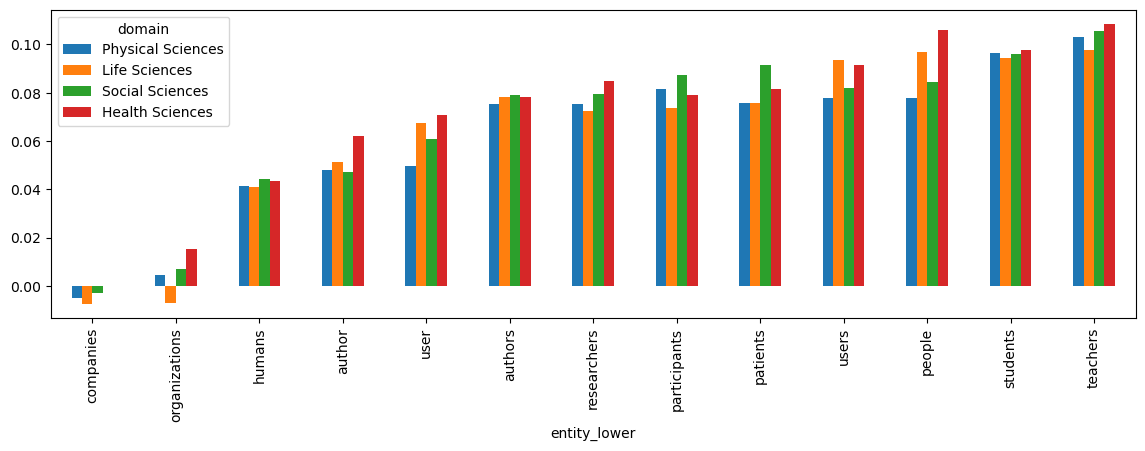

propn_llm
FriedmanchisquareResult(statistic=8.200000000000003, pvalue=0.04205418289496618) !
          HS        LS        PS        SS
HS  1.000000  0.778483  0.055437  0.119495
LS  0.778483  1.000000  0.389401  0.585369
PS  0.055437  0.389401  1.000000  0.989058
SS  0.119495  0.585369  0.989058  1.000000


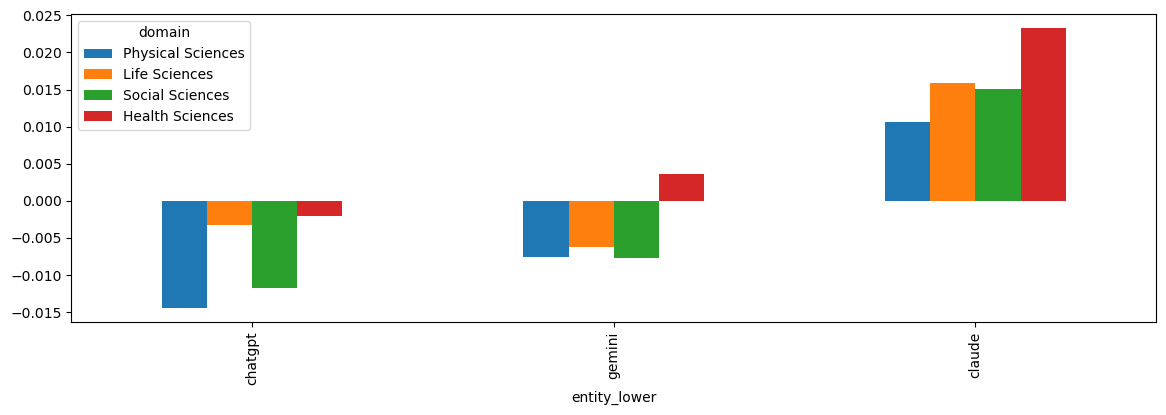

In [127]:
for et in edocs.entity_type_updated.unique():
    subs = edocs[edocs["entity_type_updated"] == et]
    escores = subs.groupby(["domain", "entity_lower"], observed=True)["score"].mean().unstack("domain")
    escores = escores.dropna()
    print(et)

    res = stats.friedmanchisquare(*[escores[d] for d in escores.columns])
    note = "!" if res.pvalue < 0.05 else ""
    print(res, note)
    if res.pvalue < 0.05:
        renamed = escores.rename(columns=abbr_map)
        print(sp.posthoc_nemenyi_friedman(renamed))
    sort_order = escores.mean(axis=1).sort_values().index.tolist()
    escores.loc[sort_order, domain_order].plot.bar(figsize=(14, 4))
    plt.show()
    print("="*30)

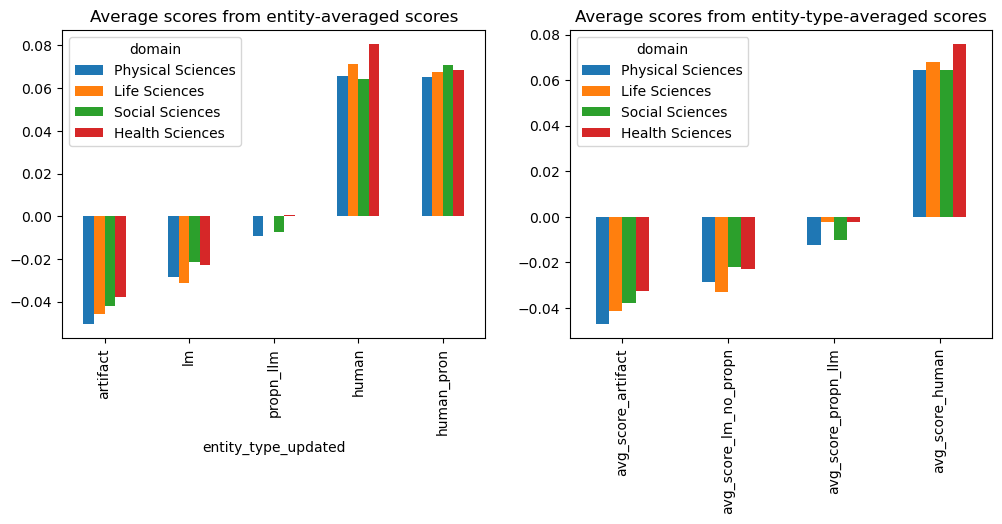

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

(edocs.groupby(["domain", "entity_type_updated"], observed=True)["score"].mean()
.unstack("domain").loc[et_order, domain_order].plot.bar(ax=axes[0]))
axes[0].set_title("Average scores from entity-averaged scores")

(docs.groupby(["domain"], observed=True)[avg_scores].mean().T[domain_order].plot.bar(ax=axes[1]))
axes[1].set_title("Average scores from entity-type-averaged scores")

plt.show()

<Axes: >

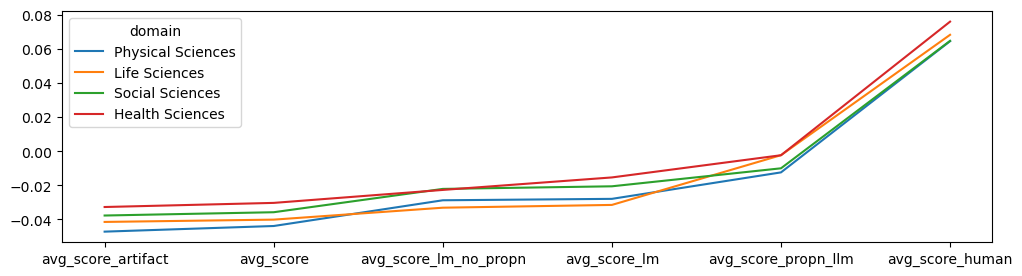

In [89]:
docs.groupby("domain", observed=True)[avg_cols].mean().T[domain_order].plot.line(figsize=(12,3))

## Inspection of linguistic features

In [105]:
def standardize(table):
    row_totals = table.sum(axis=1)
    col_totals = table.sum(axis=0)
    grand_total = table.sum().sum()
    
    E = np.outer(row_totals, col_totals) / grand_total
    E = pd.DataFrame(E, index=table.index, columns=table.columns)
    
    lift = table / E
    log_lift = np.log(lift.mask(lift == 0, np.nan))
    return log_lift

In [116]:
main_deps = set(df_dedupl.dep.value_counts()[:5].index)
main_deps_df = df_dedupl[(df_dedupl["entity_type_updated"] == "propn_llm") &
    (df_dedupl["dep"].isin(main_deps))].copy()
main_deps_df["dep"] = main_deps_df["dep"].cat.remove_unused_categories()

In [117]:
dep_counts = (main_deps_df
    .groupby(["domain", "entity_lower"], observed=True)["dep"]
    .value_counts()
    .unstack("domain")
)

In [129]:
dep_scores = (main_deps_df
    .groupby(["domain", "entity_lower", "dep"], observed=True)
    ["score"].mean()
    .unstack("domain")
)
score_order = dep_scores.mean(axis=1).sort_values(ascending=False).index

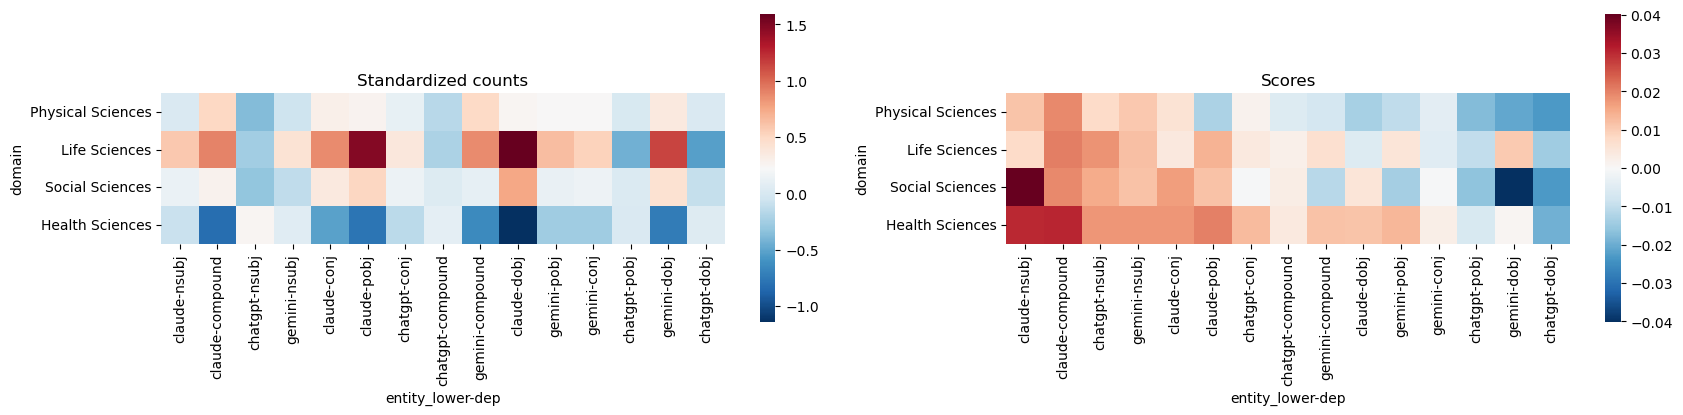

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(20, 4))

sns.heatmap(standardize(dep_counts)[domain_order].T[score_order], square=True, cmap="RdBu_r", ax=axes[0])
axes[0].set_title("Standardized counts")

sns.heatmap(dep_scores[domain_order].T[score_order], square=True, cmap="RdBu_r", ax=axes[1])
axes[1].set_title("Scores")

plt.show()

In [137]:
main_pos = set(df_dedupl.pos.value_counts()[:5].index)
main_pos_df = df_dedupl[(df_dedupl["pos"].isin(main_pos))].copy()
main_pos_df["pos"] = main_pos_df["pos"].cat.remove_unused_categories()

<Axes: xlabel='pos,entity_type_updated'>

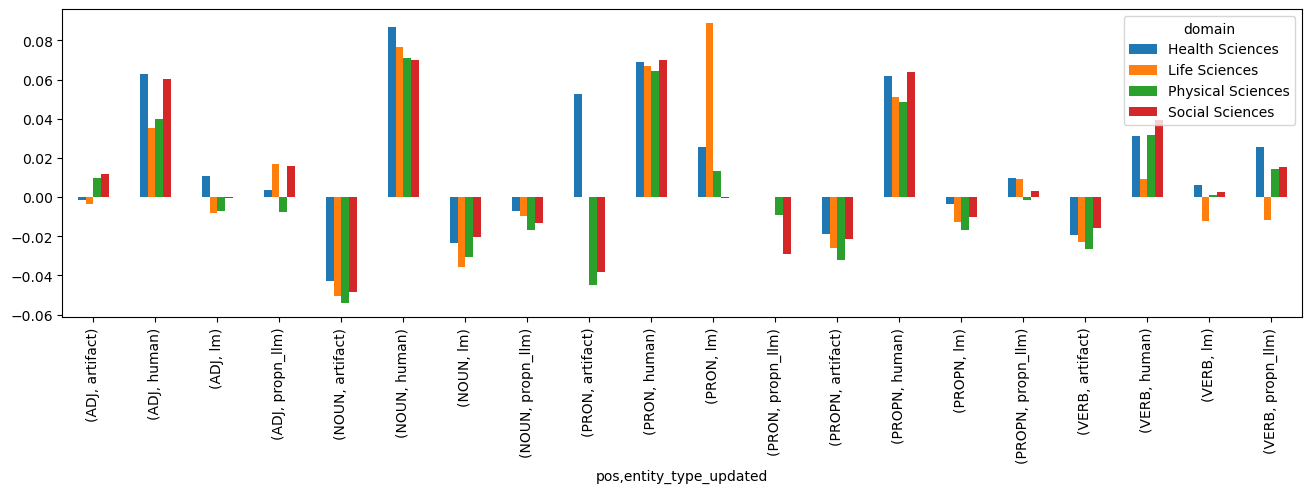

In [146]:
pos_scores = main_pos_df.groupby(["domain", "entity_type_updated", "pos"], observed=True)["score"].mean().unstack("domain").swaplevel().sort_index()
pos_scores.plot.bar(figsize=(16,4))

## Claude - human or model?

Take a stratified random sample to inspect if mentions of Claude are referring to the product name rather than a human name.

In [10]:
seed = 12345
claude_sample = df[df["entity_lower"] == "claude"].groupby(["domain", "year"], observed=True).sample(5, random_state=seed)

In [12]:
claude_sample[preview_cols]

,id,year,domain,masked_sentence_minimal,entity,score,dep,pos,ent_type
490907,W4389664539,2023,Health Sciences,These topics were transformed into learning ob...,Claude,-0.018634,conj,PROPN,PERSON
410813,W4386256885,2023,Health Sciences,Abstract Objectives To evaluate the effectiven...,Claude,0.031545,appos,PROPN,PERSON
501595,W4390229881,2023,Health Sciences,"Results: F1 Scores for GPT-4, Bard, and [MASK]...",Claude,-0.003541,conj,PROPN,PERSON
410826,W4386256885,2023,Health Sciences,Conclusion [MASK] demonstrated superior perfor...,Claude,-0.003521,nsubj,PROPN,PERSON
410823,W4386256885,2023,Health Sciences,[MASK] and ChatGPT4 both had a high capacity t...,Claude,0.027194,nsubj,PROPN,PERSON
...,...,...,...,...,...,...,...,...,...
3251786,W7140988659,2026,Social Sciences,The above was written by [MASK].,Claude,0.116424,pobj,PROPN,PERSON
3265162,W7149487898,2026,Social Sciences,This essay was drafted by [MASK] (Anthropic) b...,Claude,0.115798,pobj,PROPN,PERSON
1264443,W7142052268,2026,Social Sciences,A secondary anomaly — [MASK] Sonnet's response...,Claude,0.018018,compound,PROPN,PERSON
3251782,W7140988659,2026,Social Sciences,This document contains the complete bilingual ...,Claude,0.110827,conj,PROPN,PERSON


In [25]:
for i, sent in enumerate(claude_sample["sentence"], start=1):
    print(f"{i}) {sent}")

1) These topics were transformed into learning objectives for chatbots like GPT-4, BingAI, and Claude to generate MCQs.
2) Abstract Objectives To evaluate the effectiveness of four large language models (LLMs) (Claude, Bard, ChatGPT4, and New Bing) that have large user bases and significant social attention, in the context of medical consultation and patient education in urolithiasis.
3) Results: F1 Scores for GPT-4, Bard, and Claude for predicting Emergency Severity Index 1 and 2 were 0.899, 0.791, and 0.865 respectively.
4) Conclusion Claude demonstrated superior performance compared with the other three in urolithiasis consultation and education.
5) Claude and ChatGPT4 both had a high capacity to analyze clinical cases of urolithiasis.
6) 423 board-style questions from 9 UK exams (MRCS, MRCP, etc.) were answered by seven LLMs (ChatGPT-3.5, ChatGPT-4, Bard, Perplexity, Claude, Bing, Claude Instant).
7) Claude, ChatGPT, and Bard followed with scores of 81, 76.5, and 80, respectively.


In [17]:
claudes = df[df["entity_lower"] == "claude"].copy()

In [23]:
claudes["surname"] = claudes["masked_sentence_minimal"].str.extract(r"\[MASK\] (?P<surname>[A-Z]\w+)", expand=False)

In [24]:
claudes["surname"].value_counts()

surname
Sonnet         213
Opus           142
AI              41
Code            37
Haiku           19
Shannon         11
Anthro           3
Instant          3
Desktop          2
LLM              2
Agent            2
Enhanced         1
Sonet            1
AUC              1
Ai               1
V3               1
Monet            1
Aria             1
Chat             1
III              1
Computer         1
Bernard          1
System           1
Schaeffer        1
Workbench        1
Health           1
Manifesto        1
Certificate      1
Dozier           1
Hannes           1
Coinaud          1
Beck             1
Cowork           1
Mythos           1
Name: count, dtype: int64

In [27]:
surnames = set(("Shannon", "Bernard", "Schaeffer", "Dozier", "Hannes", "Coinaud", "Beck"))
human_claudes = claudes[claudes["surname"].isin(surnames)]
for i, sent in enumerate(human_claudes["sentence"], start=1):
    print(f"{i}) {sent}")

1) Further contributions to the development of AI theory were made by scholars such as John McCarthy, Valerie Barr, Edward Feigenbaum, Claude Shannon and others.
2) Abstract Pioneered by the foundational information theory by Claude Shannon and the visionary framework of machine intelligence by Alan Turing, the convergent evolution of information and communication technologies (IT/CT) has created an unbroken wave of connectivity and computation.
3) Camera information capacity (C), based on Claude Shannon's ground-breaking work on information theory, holds great promise as a figure of merit for a variety of imaging systems, but it has traditionally been difficult to measure.
4) It follows how generative AI derives from the measures of probability first described in the information theory of Claude Shannon and discusses specific datasets used to train and manage the "perplexity" of specific AI models, including
5) This Zenodo record contains the slides for the 1-hour seminar "Computer Vi

How much does removing the obviously human Claudes from all Claudes affect the average score?

In [28]:
human_claudes.score.mean()

0.14380284455689646

In [33]:
claudes.score.mean()

0.02076011061789306

In [36]:
claudes[~claudes.index.isin(human_claudes.index)].score.mean()

0.020059129895050213

## Score ranges on different aggregation levels

In [130]:
dfs = {}
for dataframe, name in zip((df_dedupl, edocs, etdocs), ("sentence_level", "entity", "entity_type")):
        dfs[name] = dataframe["score"].describe()

with pd.option_context("display.float_format", "{:.6f}".format):
    display(pd.DataFrame(dfs))

,sentence_level,entity,entity_type
count,2961271.000000,1561614.000000,629051.000000
mean,-0.014530,-0.021212,0.003422
std,0.069880,0.064602,0.064823
min,-0.234611,-0.229879,-0.219427
25%,-0.063880,-0.065313,-0.049442
50%,-0.027414,-0.034251,-0.015314
75%,0.025936,0.009774,0.062183
max,0.295214,0.293799,0.292030


In [132]:
avgs_df = {}
for col in avg_cols:
    avgs_df[col] = docs[col].describe()

with pd.option_context("display.float_format", "{:.6f}".format):
    display(pd.DataFrame(avgs_df))

,avg_score_artifact,avg_score,avg_score_lm_no_propn,avg_score_lm,avg_score_propn_llm,avg_score_human
count,278330.000000,283183.000000,83008.000000,88132.000000,14116.000000,201709.000000
mean,-0.042318,-0.039616,-0.027254,-0.025372,-0.008066,0.066423
std,0.031504,0.030626,0.038943,0.038285,0.040155,0.041596
min,-0.219427,-0.219427,-0.215185,-0.209236,-0.157619,-0.180921
25%,-0.062041,-0.058962,-0.052629,-0.050746,-0.035670,0.045159
50%,-0.044888,-0.041955,-0.031474,-0.029483,-0.011600,0.071712
75%,-0.025051,-0.022102,-0.005503,-0.003589,0.015947,0.092589
max,0.243426,0.211933,0.238203,0.238203,0.171064,0.292030


## Conclusions from subjects and objects

(To directly compare with AnthroScore)

In [142]:
subj_obj = df_dedupl[df_dedupl["dep"].isin(("nsubj", "dobj"))].copy()
len(subj_obj) / len(df_dedupl)

0.3707776154225669

In [143]:
edocs_subj_obj = entity_averages(subj_obj)

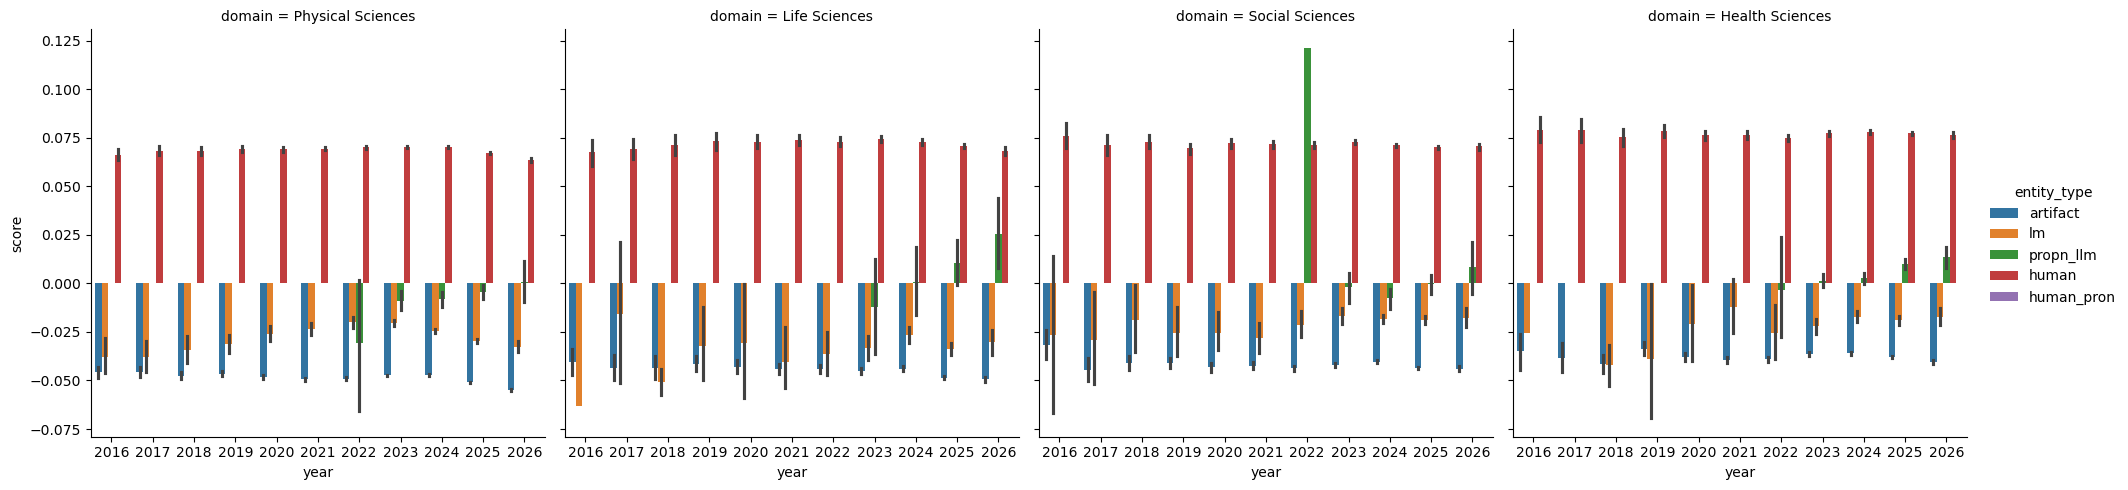

In [149]:
sns.catplot(
    data=edocs_subj_obj, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    kind='bar', estimator='mean'
)
plt.show()

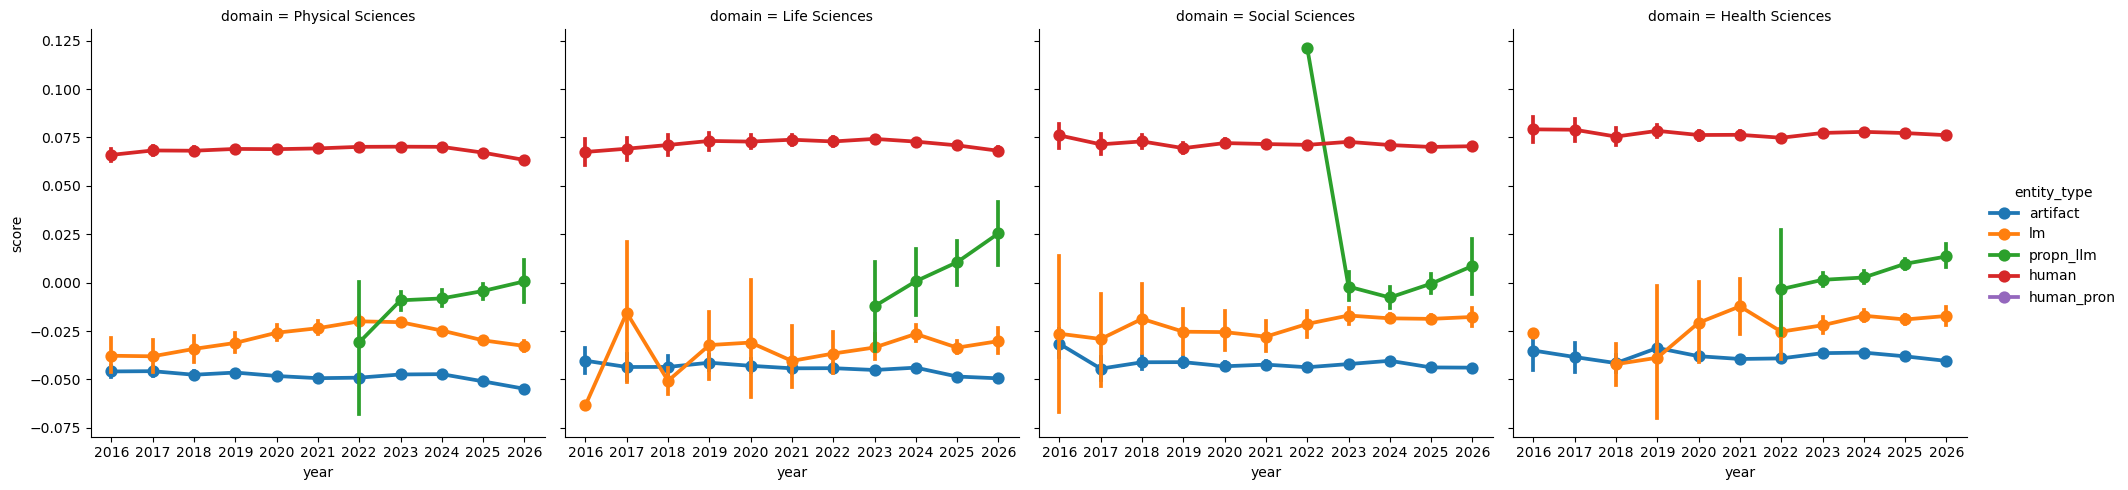

In [153]:
sns.catplot(
    data=edocs_subj_obj, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    kind='point', estimator='mean'
)
plt.show()

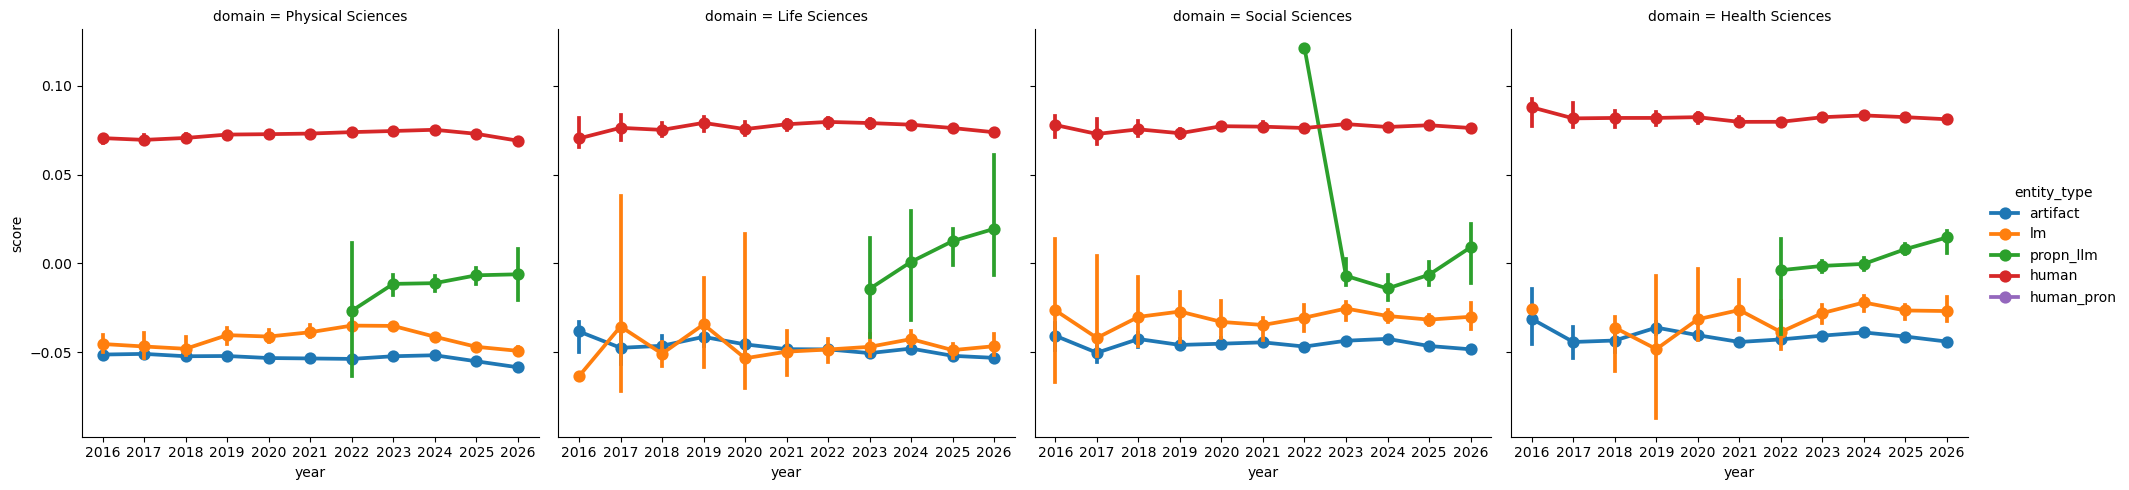

In [172]:
sns.catplot(
    data=edocs_subj_obj, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    kind='point', errorbar="ci", estimator="median"
)
plt.show()

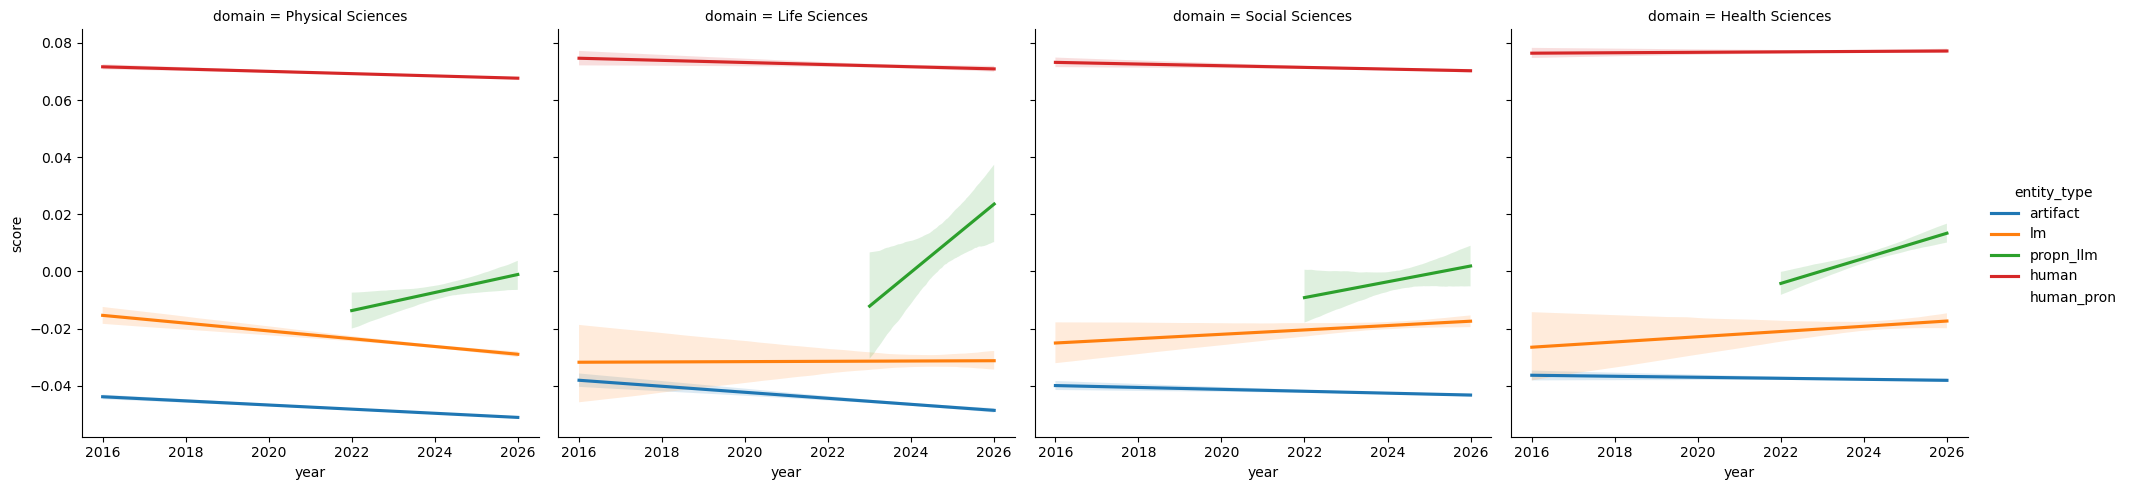

In [152]:
sns.lmplot(
    data=edocs_subj_obj, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    scatter=False
)
plt.show()

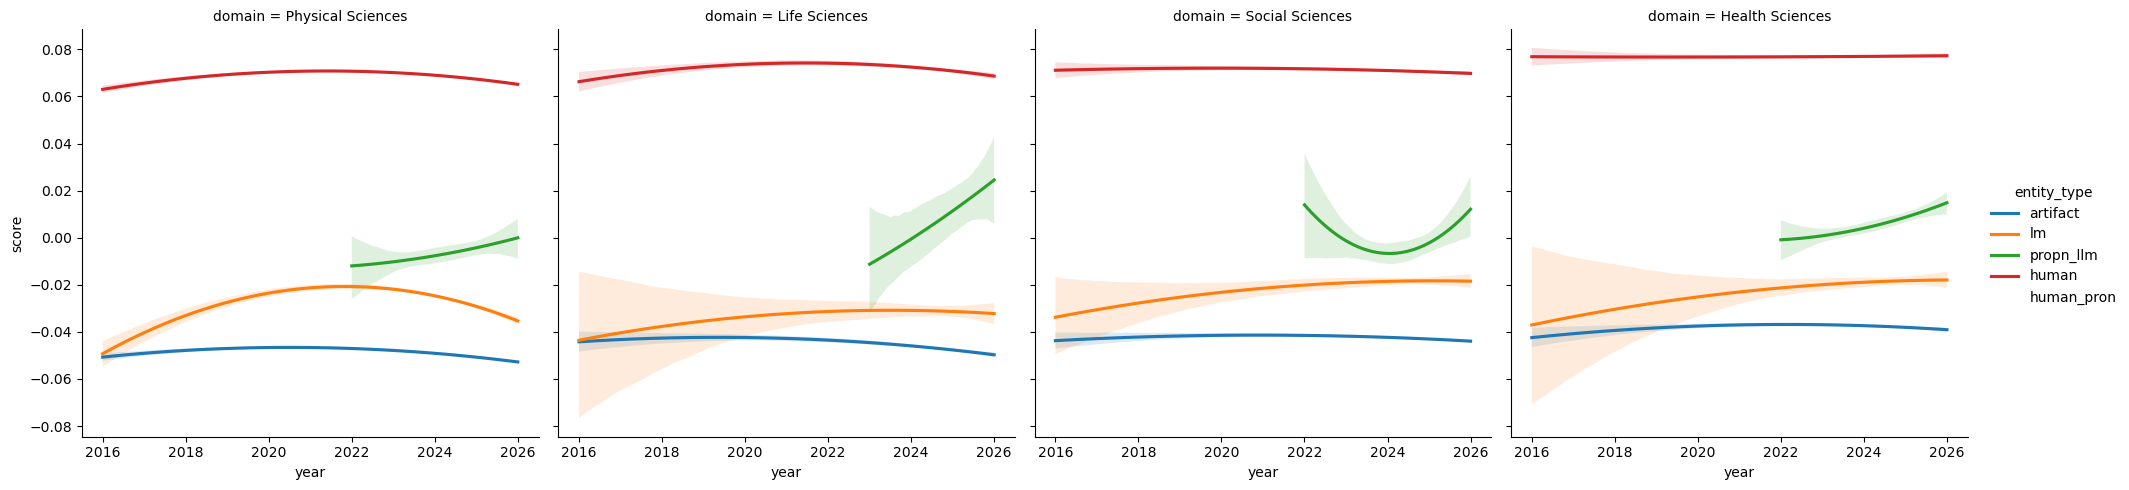

In [165]:
sns.lmplot(
    data=edocs_subj_obj, x='year', y='score', hue='entity_type', col='domain',
    hue_order=et_order, col_order=domain_order,
    scatter=False, order=2
)
plt.show()

<Axes: xlabel='entity_type_updated,dep'>

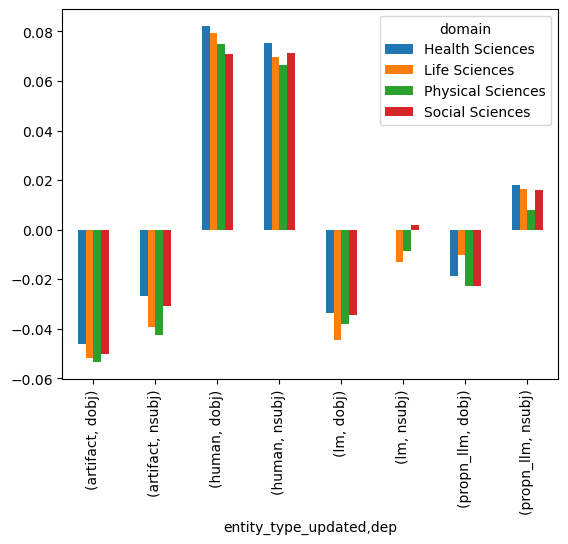

In [164]:
subj_obj.groupby(["domain", "entity_type_updated", "dep"], observed=True)["score"].mean().unstack("domain").plot.bar()